# NeuroVascNet — merged v1 (Muntasir + Maisha)

Built from `NeuroVascNet_Merge_Plan.md`. Muntasir's pipeline is the base; Maisha's
protocol, checks and reliability stack are ported onto it.

## Declared before running (do not change after seeing full-run results)

| Decision | Setting |
|---|---|
| Dataset roles | **train fNIRS = TU Berlin hBCI (MI + MA)**, train fMRI = ds002336, external fNIRS = HEFMI, external fMRI = ds002739, clinical = HEFMI. Chosen from target quality measured before any model was fitted (hBCI split-half 0.50, HbO/HbR −0.44; HEFMI 0.08, +0.92). |
| Primary encoder | Muntasir's trunk on raw EEG (`ENCODER="trunk"`, `EEG_INPUT="raw"`). Secondary: Maisha's EEGNet + TCN on band-power (`"eegnet_tcn"`, `"bandpower"`), run as a separate run tag. |
| Primary metric | Subject-demeaned r on hBCI subject-wise 5-fold CV, **tested at subject level** (pairing and sign-flip nulls). |
| Seeds | 1337, 20260726, 7, 42, 2718 — one per kernel run. Folds and splits are fixed (seed 1337); seeds change training only. Sweeps and learned-delay heads run in the first two seeds only. |
| fMRI regions | 5 sensorimotor ROIs for training **and** for ds002739 (the head predicts these 5; ds002739 is a visual task, so its external result is a cross-task stress test). |
| ds002336 tasks | All six (main). Sensitivity run: `DS2336_TASKS = ("motorloc", "MIpre", "MIpost")`. |
| EEG filtering | 0.5–45 Hz band-pass + 50 Hz notch on every dataset. |
| `w_fmri` | 1.0 (fixed; the grid is reported as a sensitivity analysis only, never used to re-select). |
| "Correct" for calibration | error ≤ median error of the **fitting** subjects, frozen and applied to unseen subjects / the external set. |
| Abstention | threshold giving 75% coverage on fitting subjects, locked. |
| Personalisation | 10%, 20%, 40% of each held-out person's trials; no-EEG control = that person's calibration mean. |
| Compact response window | 5.2–15.2 s after the cue (window coordinates 7.2–17.2 s, since hBCI windows start 2 s before the cue). |

## What changed relative to the two source notebooks

* **Fixed from Muntasir:** EEG filtering added; ds002739 electrodes matched by name
  (`electrode_info.elp`) and spherical-spline interpolation; **ds002739 EEG windows are now 30 s**
  (the old loader took 6,000 samples at the native 1 kHz = 6 s); subject-level p-values;
  class-mean demeaning row; MAE/RMSE; Claim 3 split into 3a / 3b with a shuffled-lag null;
  calibration uses a fixed tolerance instead of a median split; MC dropout keeps BatchNorm in
  eval mode; `DS2336_TASKS` switch.
* **Ported from Maisha:** 5-seed protocol with auto seed selection and aggregator; content-hashed
  data cache; timing (alignment) check; GSR A/B; EEGNet + TCN encoder with per-dataset input
  BatchNorm; band-power front end; subject-balanced sampling option; block-separated same-person
  probe with shuffled null; LOSO ridge baseline; compact endpoint + personalisation with a
  no-EEG control; amplitude evaluation; learned reliability gate → temperature → isotonic;
  locked abstention + deployment inference; per-prediction audit file; claim guard.
* **Not used from Maisha** (bugs when TU Berlin is training data): her TU Berlin loader loads MA runs
  despite claiming MI only, starts windows at the cue, and zero-fills ~20 of 32 EEG channels; her
  ds002739 loader is not event-locked.

Run with `QUICK_TEST = True` first. For the report: `QUICK_TEST = False`, then restart the kernel and
**Run All once per seed** (cell 3 picks the next missing seed). The last cell aggregates the five seeds.

## 1. Environment

In [1]:
import sys, subprocess

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

for _mod, _pkg in [("numpy", "numpy"), ("scipy", "scipy"), ("pandas", "pandas"),
                   ("torch", "torch"), ("sklearn", "scikit-learn"),
                   ("nibabel", "nibabel"), ("nilearn", "nilearn"), ("mne", "mne")]:
    try:
        __import__(_mod)
    except ImportError:
        print(f"installing {_pkg} ...")
        _pip(_pkg)

import os, re, json, math, time, random, copy, warnings
from dataclasses import dataclass, asdict, replace
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.io as sio
from scipy import signal as sps
from scipy import stats
import torch
import torch.nn as nn

if not hasattr(np, "trapezoid"):
    np.trapezoid = np.trapz          # numpy < 2 compatibility

SEED = 1337


def set_determinism(seed=SEED):
    """Put every random source into a known state.

    Called once at import and again before each training run, so a rerun on a
    different machine follows the same sequence. Seeding numpy and torch alone
    is not enough: Python's own `random` drives some library code, cuDNN picks
    convolution algorithms by timing unless told not to, and cuBLAS needs a
    workspace setting before the first CUDA call for reproducible reductions.
    """
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False       # benchmark picks by timing


def seeded_loader(ds, batch_size, seed=SEED, shuffle=True):
    """DataLoader whose shuffle order depends only on `seed`.

    Without an explicit generator the shuffle draws from the global torch RNG,
    so the batch order silently depends on how many random numbers were drawn
    earlier in the notebook -- run cells in a different order and the training
    data arrives in a different sequence.
    """
    g = torch.Generator()
    g.manual_seed(int(seed))
    return torch.utils.data.DataLoader(
        ds, batch_size=batch_size, shuffle=shuffle, drop_last=False,
        generator=g if shuffle else None, num_workers=0)


import matplotlib
matplotlib.use("Agg")                      # write files, never open a window
import matplotlib.pyplot as plt

FIGDIR = Path("neurovascnet_merge_v1_outputs") / "figures"   # reset per run tag in section 2
FIGDIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "legend.frameon": False,
})
INK, ACC, HBO, OK_, NO_ = "#11151a", "#1d4c6b", "#a3312a", "#1f6549", "#98382f"


def save_fig(fig, name, caption=""):
    """Write a figure next to the CSVs and say where it went."""
    f = FIGDIR / f"{name}.png"
    fig.savefig(f)
    plt.close(fig)
    print(f"   figure -> {f}" + (f"\n   {caption}" if caption else ""))


set_determinism()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---- merged: numeric warnings visible, cosmetic ones silenced (Maisha) -------
warnings.resetwarnings()
for _cat in (DeprecationWarning, FutureWarning, UserWarning):
    warnings.filterwarnings("ignore", category=_cat)
warnings.filterwarnings("once", category=RuntimeWarning)
from sklearn.linear_model import Ridge, LogisticRegression

## 2. Settings — the only cells you need to edit

In [2]:
# =============================================================================
#                          >>>  EDIT THIS CELL  <<<
# =============================================================================

# =============================================================================
#                     >>>  EVERY DATASET HAS ITS OWN PATH  <<<
#
#   Paste the full path of each dataset folder on YOUR computer below,
#   inside r"...". Each line is independent. Set any path to None to switch
#   that dataset off. The comment above each line says which folder must
#   exist inside it; the path check in section 2 prints [ok] / [BAD].
# =============================================================================
# By default every dataset is looked for in dataset/ at the repository root (the folder
# above pipeline/). Set the environment variable NVN_DATA to use another folder.
DATA_ROOT = Path(os.environ.get("NVN_DATA", Path.cwd().resolve().parent / "dataset"))
# ---- THE TWO fNIRS COHORTS ---------------------------------------------------
# One trains the fNIRS head, the other validates it. FNIRS_TRAIN below decides
# which way round. Both are motor imagery EEG+fNIRS and the people never
# overlap, so either direction is a legitimate experiment.

# HEFMI-ICH, 37 people (17 control, 20 haemorrhage).   must contain  epo_data/
PATH_FNIRS_HEFMI            = str(DATA_ROOT / "HEFMI-ICH EEG+FNRI")

# TU Berlin hBCI, 29 people, motor imagery + arithmetic. must contain  EEG data/
PATH_FNIRS_HBCI             = str(DATA_ROOT / "TU Berlin hBCI EEG+FNRI")

# ---- WHICH fNIRS COHORT TRAINS? ----------------------------------------------
#   "HEFMI"  HEFMI trains, hBCI validates.  The original 4-dataset blueprint.
#   "hBCI"   hBCI trains, HEFMI validates.  What the data audit argues for:
#            HEFMI's fNIRS target reproduces itself poorly (split-half 0.207)
#            and its HbO/HbR correlation is POSITIVE, meaning the signal is
#            dominated by systemic blood flow rather than an evoked response.
#            hBCI scores 0.440 and negative on the same two measures.
# Everything else is unchanged, so the two runs are directly comparable.
# The clinical analysis always uses HEFMI, whichever way this is set.
FNIRS_TRAIN = "hBCI"

# hBCI recorded motor imagery AND mental arithmetic from the same 29 people.
# True pools both, roughly doubling trials per person. A person keeps one
# subject id across the two tasks, so cross-subject splits stay honest.
HBCI_POOL_MI_MA = True

# ---- WHICH fMRI COHORT TRAINS? -----------------------------------------------
#   "ds002336"  10 subjects, ~384 trials, R128 scanner triggers (exact EEG<->BOLD
#               alignment). The blueprint's primary fMRI supervision.
#   "ds002739"  24 subjects, ~4700 trials after the per-run cap, events.tsv
#               alignment only. Roughly 12x the training trials.
# Set on TRIAL COUNTS, before seeing any external result. Report whichever is
# used -- swapping train and validation after seeing results is not a free move.
FMRI_TRAIN = "ds002336"

# ---- WHICH fMRI REGIONS ARE THE TARGET? --------------------------------------
#   "all48"  every Harvard-Oxford cortical region.
#   "motor"  the sensorimotor subset only -- blueprint 6.3 asks for "a justified
#            ROI subset focused on cortical regions relevant to the task
#            domains", and both training tasks are motor imagery. Averaging over
#            45 unrelated regions dilutes the evoked response into noise: the
#            audit measured one subject's target reliability going from -0.066
#            over 48 ROIs to +0.568 over the motor subset.
FMRI_ROIS = "motor"

# ---- MEMORY LIMIT ------------------------------------------------------------
# Each EEG trial is 30 s at 200 Hz = 6000 samples. ds002739 has ~450 stimulus
# events per run, so 24 subjects x 2 runs is ~21,400 trials -> 27.8 GB in ONE
# array, which does not fit in 32 GB of RAM.
#
# This caps the trials taken per fMRI run, sampled EVENLY across the run so the
# whole session is still covered. It also balances the two modalities: without
# it the fMRI trials outnumber the fNIRS trials roughly 6:1 and the shared
# encoder is dominated by fMRI.
#
# 100 per run  ~=  4,800 trials  ~=  6.7 GB   (fits, and is what runs by default)
# None         ->  every trial. Needs ~64 GB of RAM.
MAX_FMRI_TRIALS_PER_RUN = 100

# ---- fMRI DATA (roles are fixed) ---------------------------------------------
# fMRI supervision. ds002336, 10 subjects. Contains "derivatives/".
PATH_TRAIN_FMRI_DS002336     = str(DATA_ROOT / "OpenNeuro ds002336")

# External fMRI, never trained on. ds002739, 24 subjects. Contains "sub-01/".
PATH_EXTERNAL_FMRI_DS002739  = str(DATA_ROOT / "External fMRI validation OpenNeuro ds002739")

# ---- CLINICAL DATA (section 16) ----------------------------------------------
# The SAME HEFMI folder as above, deliberately not written out a second time --
# two copies of one path drift apart the moment you edit one of them.
#
# It keeps its own name because section 16 asks a different question: 17 healthy
# controls against 20 haemorrhage patients, measured directly from the
# recordings with no model involved. Set it to None to skip that section, or to
# another folder to point it elsewhere, without disturbing the training set.
PATH_CLINICAL_HEFMI = PATH_FNIRS_HEFMI

# =============================================================================
#                        >>>  CHOOSE HOW TO RUN  <<<
#
#   True   SMOKE TEST -- few subjects, 2 epochs, ~10 min.
#                        Proves every cell runs. NUMBERS ARE NOISY.
#   False  FULL RUN    -- all subjects, 30 epochs, 1000 permutations.
#                        Hours. These are the numbers you report.
# =============================================================================
QUICK_TEST = False    # merged v1: smoke-test first; set False for the five-seed full run
# =============================================================================

# =============================================================================
#                 >>>  MERGED-NOTEBOOK SWITCHES (declared in cell 0)  <<<
# =============================================================================
ENCODER = "trunk"          # "trunk" (Muntasir, PRIMARY) | "eegnet_tcn" (Maisha, secondary)
EEG_INPUT = "raw"          # "raw" (PRIMARY) | "bandpower" (fixed band-power front end, Maisha)
EEG_FILTER = True          # 0.5-45 Hz band-pass + 50 Hz notch on every dataset
DS2336_TASKS = ("motorloc", "MIpre", "MIpost", "eegNF", "fmriNF", "eegfmriNF")
#   sensitivity run without neurofeedback: ("motorloc", "MIpre", "MIpost")
BALANCED_SUBJECTS = False  # subject-balanced sampling (Maisha) -- off in the primary run
RUN_SWEEPS = True          # w_fmri grid, bottleneck sweep, learned-delay heads (first 2 seeds only)
USE_CACHE = True           # content-hashed array cache (Maisha); delete the folder to rebuild
SEEDS = [1337, 20260726, 7, 42, 2718]
RUN_SEED_INDEX = "auto"    # "auto" = first seed without a finished summary; or 0..4 to force one

In [3]:
@dataclass(frozen=True)
class Config:
    tmin_s: float = -2.0
    tmax_s: float = 28.0
    eeg_fs: float = 200.0
    hemo_fs: float = 10.0
    eeg_samples: int = 6000        # 30 s @ 200 Hz
    hemo_samples: int = 300        # 30 s @ 10 Hz
    fmri_vols: int = 15            # 30 s @ TR 2 s
    baseline_s: float = 2.0
    n_folds: int = 5
    n_perm: int = 1000
    epochs: int = 30
    batch_size: int = 64
    lr: float = 1e-3
    apply_gsr: bool = False        # audited: GSR removes much of the evoked response
    w_main: float = 1.0            # pearson (shape)
    w_hetero: float = 0.1          # gaussian NLL -> uncertainty
    w_smooth: float = 0.05
    w_fmri: float = 1.0            # fixed (declared); grid is sensitivity only
    n_null: int = 100              # shuffles for probe / delay nulls
    abstain_coverage: float = 0.75
    personal_fracs: tuple = (0.10, 0.20, 0.40)
    response_start_s: float = 7.2  # window coords: 2 s pre-cue + 5.2 s
    response_dur_s: float = 10.0
    practical_r: float = 0.05      # below this a significant r is reported as "negligible"
    reliability_inner_folds: int = 3   # Claim 5 nested calibration (audit fix 2)


CFG = Config()
if QUICK_TEST:
    CFG = replace(CFG, epochs=2, n_perm=200, n_folds=3, n_null=20)

# ---- run tag, output folders and automatic seed choice (Maisha's protocol) ----
import hashlib
# audit fix 3: every declared switch and setting is part of the run identity, so a run
# with different settings can never be aggregated with (or mistaken for) another one.
RUN_SPEC = {"encoder": ENCODER, "eeg_input": EEG_INPUT, "eeg_filter": EEG_FILTER,
            "ds2336_tasks": list(DS2336_TASKS), "balanced_subjects": BALANCED_SUBJECTS,
            "run_sweeps": RUN_SWEEPS, "quick_test": QUICK_TEST, "config": asdict(CFG),
            "fnirs_train": FNIRS_TRAIN, "fmri_train": FMRI_TRAIN, "fmri_rois": FMRI_ROIS,
            "hbci_pool_mi_ma": HBCI_POOL_MI_MA, "max_fmri_trials_per_run": MAX_FMRI_TRIALS_PER_RUN,
            "fold_seed": SEED, "seeds": SEEDS, "notebook": "merge_v1.2",
            # folder NAMES only: the same run on another PC must get the same run tag
            "paths": [None if p is None else Path(p).name for p in
                      (PATH_FNIRS_HBCI, PATH_FNIRS_HEFMI, PATH_TRAIN_FMRI_DS002336,
                       PATH_EXTERNAL_FMRI_DS002739, PATH_CLINICAL_HEFMI)]}
RUN_FINGERPRINT = hashlib.sha256(json.dumps(RUN_SPEC, sort_keys=True, default=str).encode()).hexdigest()
RUN_TAG = f"{ENCODER}_{EEG_INPUT}_{RUN_FINGERPRINT[:10]}" + ("_quick" if QUICK_TEST else "")
OUT = Path("neurovascnet_merge_v1_outputs") / RUN_TAG
OUT.mkdir(parents=True, exist_ok=True)
FIGDIR = OUT / "figures"
FIGDIR.mkdir(exist_ok=True)


def seed_done(s):
    f = OUT / f"summary_seed{s}.json"
    if not f.is_file():
        return False
    try:
        with open(f, encoding="utf-8") as fh:
            doc = json.load(fh)
        prov = doc.get("provenance", {})
        return (prov.get("seed") == s and prov.get("run_fingerprint") == RUN_FINGERPRINT
                and doc.get("claim_guard", {}).get("passed") is True)
    except Exception:
        return False


SEEDS_DONE = [s for s in SEEDS if seed_done(s)]
if os.environ.get("NEUROVASCNET_RUN_SEED"):
    RUN_SEED = int(os.environ["NEUROVASCNET_RUN_SEED"])
elif RUN_SEED_INDEX == "auto":
    _todo = [s for s in SEEDS if s not in SEEDS_DONE]
    RUN_SEED = _todo[0] if _todo else SEEDS[0]
    if not _todo:
        print("all five seeds already have summaries -- re-running", RUN_SEED)
else:
    RUN_SEED = SEEDS[int(RUN_SEED_INDEX)]
assert RUN_SEED in SEEDS, f"{RUN_SEED} is not in the declared protocol {SEEDS}"
TRAIN_SEED = RUN_SEED                       # model init + batch order; folds stay on SEED
DO_SWEEPS = RUN_SWEEPS and RUN_SEED in SEEDS[:2]
SEED_OUT = OUT / f"seed{RUN_SEED}"
SEED_OUT.mkdir(exist_ok=True)

print(f"numpy {np.__version__} | torch {torch.__version__} | device {DEVICE}")
print(f"run tag {RUN_TAG} | seed {RUN_SEED} (done: {SEEDS_DONE or 'none'}) | sweeps {DO_SWEEPS}")
print("MODE:", "SMOKE TEST -- numbers are NOT reportable" if QUICK_TEST else "FULL RUN")
if ENCODER == "eegnet_tcn" and EEG_INPUT == "raw":
    print("WARNING: EEGNet+TCN on raw 6000-sample EEG is memory-heavy; the declared secondary is bandpower.")

numpy 1.26.4 | torch 2.7.1+cu118 | device cuda
run tag trunk_raw_430e7e788f | seed 1337 (done: none) | sweeps True
MODE: FULL RUN


In [4]:
# ---- resolve the dataset paths -----------------------------------------------
# FNIRS_TRAIN decides which cohort trains and which validates. Each entry also
# records WHICH LOADER to use, so the roles can swap without the loading code
# having to guess what it is being handed.
_HEFMI = (PATH_FNIRS_HEFMI, "epo_data", "HEFMI",  "hefmi")
_HBCI  = (PATH_FNIRS_HBCI,  "EEG data", "hBCI",   "hbci")

if FNIRS_TRAIN == "HEFMI":
    _tr, _ex = _HEFMI, _HBCI
elif FNIRS_TRAIN == "hBCI":
    _tr, _ex = _HBCI, _HEFMI
else:
    raise ValueError(f'FNIRS_TRAIN must be "HEFMI" or "hBCI", got {FNIRS_TRAIN!r}')

_DS2336 = (PATH_TRAIN_FMRI_DS002336,    "derivatives", "ds002336", "ds002336")
_DS2739 = (PATH_EXTERNAL_FMRI_DS002739, "sub-01",      "ds002739", "ds002739")

if FMRI_TRAIN == "ds002336":
    _mtr, _mex = _DS2336, _DS2739
elif FMRI_TRAIN == "ds002739":
    _mtr, _mex = _DS2739, _DS2336
else:
    raise ValueError(f'FMRI_TRAIN must be "ds002336" or "ds002739", got {FMRI_TRAIN!r}')

ROLES = {
    "train_fnirs":    (_tr[0], _tr[1], f"TRAIN    fNIRS  {_tr[2]}"),
    "train_fmri":     (_mtr[0], _mtr[1], f"TRAIN    fMRI   {_mtr[2]}"),
    "external_fnirs": (_ex[0], _ex[1], f"EXTERNAL fNIRS  {_ex[2]}"),
    "external_fmri":  (_mex[0], _mex[1], f"EXTERNAL fMRI   {_mex[2]}"),
    "clinical":       (PATH_CLINICAL_HEFMI,         "epo_data",    "CLINICAL        ICH vs controls"),
}
FNIRS_LOADER = {"train_fnirs": _tr[3], "external_fnirs": _ex[3]}
FMRI_LOADER  = {"train_fmri": _mtr[3], "external_fmri": _mex[3]}
print(f"fNIRS configuration: {_tr[2]} trains, {_ex[2]} validates")
print(f"fMRI  configuration: {_mtr[2]} trains, {_mex[2]} validates")
print(f"fMRI  target       : {FMRI_ROIS} ({'sensorimotor subset' if FMRI_ROIS == 'motor' else 'all cortical regions'})\n")

# A training set and its external partner must never be the same folder.
for _a, _b, _m in (("train_fnirs", "external_fnirs", "fNIRS"),
                   ("train_fmri", "external_fmri", "fMRI")):
    _pa, _pb = ROLES[_a][0], ROLES[_b][0]
    if _pa and _pb and Path(_pa).resolve() == Path(_pb).resolve():
        raise ValueError(f"{_a} and {_b} are the same folder -- the {_m} external "
                         "validation would be testing on training data.")

PATHS = {}
for _key, (_raw, _marker, _label) in ROLES.items():
    if not _raw:
        print(f"  [off ] {_label}")
        PATHS[_key] = None
        continue
    _p = Path(_raw)
    if not _p.exists():
        print(f"  [BAD ] {_label}   path does not exist: {_p}")
        PATHS[_key] = None
    elif not (_p / _marker).exists():
        print(f"  [BAD ] {_label}   no '{_marker}/' inside: {_p}")
        PATHS[_key] = None
    else:
        print(f"  [ok  ] {_label}")
        PATHS[_key] = _p

if not (PATHS["train_fnirs"] or PATHS["train_fmri"]):
    _lines = []
    for _k, (_r, _m, _l) in ROLES.items():
        _lines.append(f"      {_l}\n         path   {_r}\n         needs  {_m}/")
    raise FileNotFoundError(
        "No TRAINING dataset resolved -- nothing to train on.\n\n"
        "  Edit the PATH_* lines in the settings cell. Each one is a full path\n"
        "  to that dataset's folder, and each must contain the folder named\n"
        "  below:\n\n" + "\n".join(_lines))

print(f"\noutputs -> {OUT.resolve()}")

# A fingerprint of the environment. If two machines produce different numbers,
# comparing these lines is the fastest way to find out why.
print("\nenvironment")
print(f"  python  {sys.version.split()[0]}")
print(f"  numpy   {np.__version__}   scipy {__import__('scipy').__version__}")
print(f"  torch   {torch.__version__}   device {DEVICE}")
if DEVICE == "cuda":
    print(f"  gpu     {torch.cuda.get_device_name(0)}")
    print(f"  seed    {SEED}   cudnn.deterministic={torch.backends.cudnn.deterministic}"
      f"  benchmark={torch.backends.cudnn.benchmark}")

fNIRS configuration: hBCI trains, HEFMI validates
fMRI  configuration: ds002336 trains, ds002739 validates
fMRI  target       : motor (sensorimotor subset)

  [ok  ] TRAIN    fNIRS  hBCI
  [ok  ] TRAIN    fMRI   ds002336
  [ok  ] EXTERNAL fNIRS  HEFMI
  [ok  ] EXTERNAL fMRI   ds002739
  [ok  ] CLINICAL        ICH vs controls

outputs -> G:\research_bio_medical\merge\neurovascnet_merge_v1_outputs\trunk_raw_430e7e788f

environment
  python  3.12.0
  numpy   1.26.4   scipy 1.16.1
  torch   2.7.1+cu118   device cuda
  gpu     NVIDIA GeForce RTX 3060 Ti
  seed    1337   cudnn.deterministic=True  benchmark=False


## 3. Data loading (Muntasir's loaders, with the merge fixes)

In [5]:
# ---- shared signal helpers ---------------------------------------------------
EXT_COEF = {760: {"HbO": 1486.59, "HbR": 3843.71},
            850: {"HbO": 2526.39, "HbR": 1798.64}}
DPF = {760: 6.4, 850: 5.8}
SD_CM = 3.0


def bandpass(x, fs, lo, hi, order=3):
    nyq = fs / 2.0
    hi = min(hi, nyq * 0.95)
    if lo >= hi:
        return x
    b, a = sps.butter(order, [lo / nyq, hi / nyq], btype="band")
    return sps.filtfilt(b, a, x, axis=-1)


def resample_to(x, n):
    return x if x.shape[-1] == n else sps.resample(x, n, axis=-1)


# --- EEG montage crosswalk ----------------------------------------------------
# HEFMI and hBCI use different montages. HEFMI has C3/C4/FC5/CP5; hBCI uses the
# 10-5 intermediate positions (FCC3h, CCP3h ...) and has NO C3 or C4 at all.
# Only 12 labels are shared and not one of them is a motor electrode, so matching
# by name would hand the encoder exactly the wrong channels. Matching by POSITION
# in the array is worse still -- it pairs electrodes that are nowhere near each
# other. Both montages do have known 3-D coordinates, so the honest route is to
# interpolate one onto the other's positions with spherical splines, which is
# what recovers a genuine C3 estimate from FCC3h and CCP3h.

HEFMI_CH = ["FC1", "AF3", "AF4", "CP1", "CP2", "CP6", "Cz", "C3",
            "C4", "T7", "T8", "FC2", "FC5", "FC6", "Pz", "CP5",
            "PO3", "PO4", "Oz", "FP2", "FP1", "FZ", "F3", "F4",
            "F7", "F8", "P3", "P4", "P7", "P8", "O1", "O2"]


def _canon(name):
    """MATLAB-cased labels -> the casing MNE's standard_1005 uses."""
    n = str(name).strip()
    up = n.upper()
    fixed = {"FP1": "Fp1", "FP2": "Fp2", "FZ": "Fz", "CZ": "Cz",
             "PZ": "Pz", "OZ": "Oz", "FPZ": "Fpz"}
    return fixed.get(up, n)


def electrode_positions(names):
    """3-D positions for electrode labels.

    Returns None when the labels are missing or any one is unknown -- the fMRI
    datasets carry no electrode names at all, so callers must handle None.
    """
    if not names:
        return None
    try:
        import mne
        pos = mne.channels.make_standard_montage(
            "standard_1005").get_positions()["ch_pos"]
        return np.array([pos[_canon(c)] for c in names])
    except (KeyError, ImportError):
        return None


def interpolation_matrix(src_names, dst_names):
    """Spherical-spline matrix mapping src electrodes onto dst positions.

    None whenever the crosswalk cannot be built -- missing names, an unknown
    label, or MNE unavailable. Callers fall back and say so in the output.
    """
    ps, pdst = electrode_positions(src_names), electrode_positions(dst_names)
    if ps is None or pdst is None:
        return None
    try:
        from mne.channels.interpolation import _make_interpolation_matrix
        r = np.linalg.norm(ps, axis=1).mean()      # project to a unit sphere
        return _make_interpolation_matrix(ps / r, pdst / r)
    except Exception:
        return None


def compact_response(hemo, fs, start_s=5.2, dur_s=10.0):
    """Four physiological summaries per trial, as in the personalised analysis.

    Averages across optodes, then takes the response window and reduces it to
    HbO_mean, HbR_mean, HbO_peak, HbR_trough. The window (5.2 s for 10 s) is the
    one selected on training subjects only in that analysis.
    """
    a = max(int(round(start_s * fs)), 0)
    b = min(int(round((start_s + dur_s) * fs)), hemo.shape[-1])
    if b - a < 3:
        a, b = 0, hemo.shape[-1]
    k = hemo.shape[1] // 2
    hbo = hemo[:, :k, a:b].mean(1)
    hbr = hemo[:, k:, a:b].mean(1)
    return np.stack([hbo.mean(1), hbr.mean(1), hbo.max(1), hbr.min(1)], 1)


def subsample_onsets(onsets, cap=None):
    """Keep at most `cap` onsets, spread EVENLY over the run.

    Taking the first N would sample only the start of the session and inherit
    whatever drift or habituation lives there.
    """
    cap = MAX_FMRI_TRIALS_PER_RUN if cap is None else cap
    onsets = np.asarray(onsets)
    if not cap or len(onsets) <= cap:
        return onsets
    idx = np.unique(np.linspace(0, len(onsets) - 1, cap).round().astype(int))
    return onsets[idx]


def stack_free(arrays, n_ch=None):
    """np.stack that does not hold two full copies at once.

    np.stack allocates the whole output while the input list is still alive,
    so peak memory is 2x the result. These arrays run to gigabytes, so instead
    preallocate once and drop each input as it is copied in.
    """
    if not arrays:
        return None
    a0 = arrays[0]
    rows = a0.shape[0] if n_ch is None else n_ch
    out = np.empty((len(arrays), rows) + a0.shape[1:], dtype=np.float32)
    for i in range(len(arrays)):
        out[i] = arrays[i][:rows]
        arrays[i] = None          # free as we go
    arrays.clear()
    return out


def zscore_trial(seg):
    return ((seg - seg.mean(-1, keepdims=True)) /
            (seg.std(-1, keepdims=True) + 1e-6)).astype(np.float32)


def baseline_correct(seg, n_base):
    return seg - seg[:, :n_base].mean(-1, keepdims=True)


def beer_lambert(lo_wl, hi_wl):
    """Raw 760/850 nm intensities -> HbO, HbR in micromolar."""
    def od(x):
        base = np.median(x, axis=-1, keepdims=True)
        base = np.where(np.abs(base) < 1e-12, 1e-12, base)
        return -np.log(np.clip(x / base, 1e-9, None))
    a1, a2 = od(lo_wl), od(hi_wl)
    L1, L2 = SD_CM * DPF[760], SD_CM * DPF[850]
    E = np.array([[EXT_COEF[760]["HbO"] * L1, EXT_COEF[760]["HbR"] * L1],
                  [EXT_COEF[850]["HbO"] * L2, EXT_COEF[850]["HbR"] * L2]])
    Ei = np.linalg.inv(E)
    return ((Ei[0, 0] * a1 + Ei[0, 1] * a2) * 1e6,
            (Ei[1, 0] * a1 + Ei[1, 1] * a2) * 1e6)


def pool_hbo_hbr(hemo):
    """(n, 2k, T) -> (n, 2, T): mean HbO and mean HbR.

    The only montage-independent way to compare two fNIRS datasets whose optode
    layouts have no published crosswalk. Used for external validation ONLY.
    """
    k = hemo.shape[1] // 2
    return np.stack([hemo[:, :k].mean(1), hemo[:, k:].mean(1)], axis=1)


# ---- merged helpers ---------------------------------------------------------------
_STD_POS = None


def _std_positions():
    global _STD_POS
    if _STD_POS is None:
        import mne
        _STD_POS = mne.channels.make_standard_montage("standard_1005").get_positions()["ch_pos"]
    return _STD_POS


def keep_known_channels(eeg, names):
    """Keep channels whose name has a standard 10-05 position (drops ECG/EOG/unknown).

    Returns the kept rows and their names in MNE's spelling, so the spline
    interpolation can place every one of them."""
    pos = _std_positions()
    upper = {k.upper(): k for k in pos}
    keep, out = [], []
    for i, n in enumerate(names):
        k = upper.get(str(n).strip().upper())
        if k is not None and k not in out:
            keep.append(i)
            out.append(k)
    return eeg[keep], out


def align_channels(eeg, names, ref):
    """Reorder/subset rows to the reference name list; None if any reference name is missing."""
    idx = {n: i for i, n in enumerate(names)}
    if any(r not in idx for r in ref):
        return None
    return eeg[[idx[r] for r in ref]]


def ds2739_labels(root, n):
    """ds002739 electrode names from electrode_info.elp (Maisha's fix for index pairing)."""
    import re as _re
    for p in (root / "additional_files" / "electrode_info.elp", root / "electrode_info.elp"):
        if not p.exists():
            continue
        labs = []
        with open(p, encoding="utf-8", errors="replace") as fh:
            lines = fh.read().splitlines()
        for line in lines:
            parts = line.split()
            if not parts or parts[0][0] in "%#;":
                continue
            tok = parts[1] if parts[0].upper() in ("EEG", "EOG", "ECG", "EMG") and len(parts) > 1 else parts[0]
            if _re.fullmatch(r"[A-Za-z][A-Za-z0-9]{0,5}", tok):
                labs.append(tok)
        if len(labs) < n:
            print(f"   WARNING: {p.name} lists {len(labs)} names for {n} channels")
            labs += [f"CH{i}" for i in range(len(labs), n)]
        return labs[:n]
    return [f"CH{i + 1}" for i in range(n)]


def filter_eeg_inplace(x, fs, lo=0.5, hi=45.0, notch=50.0, chunk=128):
    """0.5-45 Hz band-pass + 50 Hz notch, then per-trial z-score (Maisha's EEG cleaning)."""
    sos = sps.butter(4, [lo, min(hi, 0.45 * fs)], btype="band", fs=fs, output="sos")
    bn, an = sps.iirnotch(notch, 30.0, fs=fs) if notch < fs / 2 else (None, None)
    for i in range(0, len(x), chunk):
        seg = sps.sosfiltfilt(sos, np.asarray(x[i:i + chunk], np.float64), axis=-1)
        if bn is not None:
            seg = sps.filtfilt(bn, an, seg, axis=-1)
        seg = (seg - seg.mean(-1, keepdims=True)) / (seg.std(-1, keepdims=True) + 1e-6)
        x[i:i + chunk] = seg.astype(np.float32)
    return x


# ---- content-hashed cache (Maisha): a loader edit can never reuse stale arrays ----
LOADER_VERSION = "merge_v1"
CACHE_DIR = Path("neurovascnet_merge_v1_cache")
_ARRAY_KEYS = ("eeg", "hemo", "labels", "subject_ids", "task_ids", "rec_ids")


def _cache_key(role):
    import inspect
    import hashlib
    src = ""
    for f in ("load_hefmi", "load_hbci", "load_ds002336", "load_ds002739", "load_fnirs",
              "load_fmri", "keep_known_channels", "ds2739_labels", "filter_eeg_inplace", "_roi",
              "bandpass", "resample_to", "zscore_trial", "baseline_correct", "beer_lambert",
              "_runs", "_split_wavelengths", "subsample_onsets", "stack_free", "align_channels",
              "_canon", "_std_positions", "_ho_masker", "select_rois", "motor_roi_index", "_detrend",
              "_hefmi_window"):
        try:
            src += inspect.getsource(globals()[f])
        except Exception:
            return None                     # cannot fingerprint -> caller disables the cache
    info = {"role": role, "v": LOADER_VERSION, "path": str(PATHS.get(role)),
            "fnirs_train": FNIRS_TRAIN, "fmri_train": FMRI_TRAIN, "rois": FMRI_ROIS,
            "tasks": list(DS2336_TASKS), "cap": MAX_FMRI_TRIALS_PER_RUN, "filter": EEG_FILTER,
            "pool": HBCI_POOL_MI_MA, "quick": QUICK_TEST,
            "data_cfg": {k: getattr(CFG, k) for k in ("tmin_s", "tmax_s", "eeg_fs", "hemo_fs", "eeg_samples",
                                                      "hemo_samples", "fmri_vols", "baseline_s")},
            "constants": {"TR_S": TR_S, "EXT_COEF": EXT_COEF, "DPF": DPF, "SD_CM": SD_CM, "EOG": EOG,
                          "HEFMI_CH": HEFMI_CH, "HEFMI_CUE_S": HEFMI_CUE_S, "motor": MOTOR_ROI_PATTERNS},
            "src": hashlib.sha256(src.encode()).hexdigest()}
    return hashlib.sha256(json.dumps(info, sort_keys=True).encode()).hexdigest()[:16]


def cached(role, builder):
    key = _cache_key(role)
    use = USE_CACHE and key is not None
    if USE_CACHE and key is None:
        print(f"   WARNING: could not fingerprint the loader code -- cache disabled for {role}")
    cdir = CACHE_DIR / f"{role}_{key}"
    if use and (cdir / "meta.json").exists():
        with open(cdir / "meta.json", encoding="utf-8") as fh:
            meta = json.load(fh)
        d = {k: np.load(cdir / f"{k}.npy") for k in meta["arrays"]}
        d.update(meta["info"])
        print(f"loaded {role} from cache {cdir.name}")
        return d
    d = builder()
    if d is None:
        return None
    if EEG_FILTER:
        filter_eeg_inplace(d["eeg"], CFG.eeg_fs)
    if use:
        cdir.mkdir(parents=True, exist_ok=True)
        arrays = [k for k in _ARRAY_KEYS if isinstance(d.get(k), np.ndarray)]
        for k in arrays:
            np.save(cdir / f"{k}.npy", d[k])
        info = {"name": d["name"], "modality": d["modality"], "ch_names": d.get("ch_names")}
        with open(cdir / "meta.json", "w", encoding="utf-8") as fh:
            json.dump({"arrays": arrays, "info": info}, fh)
    return d

In [6]:
# ---- fNIRS cohort: HEFMI (train or external -- set by FNIRS_TRAIN) -----------
# EEG channel names live in code/EpoDataMaking/MakeDatasetFromRaw.m, because the
# .mat stores them as a MATLAB string object SciPy decodes to an opaque blob.
HEFMI_EEG_CHANNELS = [
    "FC1", "AF3", "AF4", "CP1", "CP2", "CP6", "Cz", "C3",
    "C4",  "T7",  "T8",  "FC2", "FC5", "FC6", "Pz", "CP5",
    "PO3", "PO4", "Oz",  "FP2", "FP1", "FZ",  "F3", "F4",
    "F7",  "F8",  "P3",  "P4",  "P7",  "P8",  "O1", "O2",
]


def read_probe(root):
    """fNIRS optode geometry from any .nirs file (SD struct)."""
    hits = sorted(Path(root).rglob("*.nirs"))
    if not hits:
        return None
    try:
        SD = sio.loadmat(hits[0], squeeze_me=True, struct_as_record=False)["SD"]
    except Exception:
        return None
    ml = np.asarray(SD.MeasList)
    return {"sources": int(np.asarray(SD.SrcPos).shape[0]),
            "detectors": int(np.asarray(SD.DetPos).shape[0]),
            "pairs": len({(int(a), int(b)) for a, b in ml[:, :2]}),
            "wavelengths": sorted({int(w) for w in np.atleast_1d(SD.Lambda).ravel()}),
            "unit": str(getattr(SD, "SpatialUnit", "?"))}


# Epoch layout from code/EpoDataMaking/MakeDatasetFromRaw.m:
#   X = data(cue - 10*fs : rest + 15*fs)   -> cue at 10.0 s, ~37.2 s per epoch
# The old loader resampled the WHOLE 37.2 s epoch onto the 30 s grid, so HEFMI time
# ran 1.24x fast against hBCI (lags, filters and the external comparison all off).
HEFMI_EEG_FS, HEFMI_NIRS_FS = 256.0, 11.0
HEFMI_CUE_S = 10.0


def _hefmi_window(x, fs, cfg=CFG):
    """(T, ch) epoch -> (ch, T) window cfg.tmin_s..cfg.tmax_s around the cue, native rate.

    The epoch ends ~0.8 s before +28 s; that short tail is filled with the last sample
    so every dataset keeps the same 30 s grid with the cue at the same position.
    """
    a = int(round((HEFMI_CUE_S + cfg.tmin_s) * fs))
    b = int(round((HEFMI_CUE_S + cfg.tmax_s) * fs))
    seg = np.asarray(x[a:min(b, len(x))], float).T
    if seg.shape[1] < b - a:
        seg = np.pad(seg, ((0, 0), (0, b - a - seg.shape[1])), mode="edge")
    return seg


def load_hefmi(root, cfg=CFG, max_people=None):
    n_base = int(cfg.baseline_s * cfg.hemo_fs)
    eeg_l, hemo_l, lab_l, sid_l, audit = [], [], [], [], []
    rec_l = []
    people = {}
    for group in ("Normals", "Patients"):
        gdir = root / "epo_data" / group / "EEG"
        if not gdir.exists():
            continue
        for sd in sorted(p for p in gdir.iterdir() if p.is_dir()):
            person = f"{group}_{sd.name}"        # Normals/subject1 != Patients/subject1
            if max_people and person not in people and len(people) >= max_people:
                continue
            for ef in sorted(sd.glob("*_epo.mat")):
                nf = root / "epo_data" / group / "NIRS" / sd.name / ef.name
                if not nf.exists():
                    audit.append({"person": person, "file": ef.name,
                                  "status": "no fNIRS partner", "trials": 0}); continue
                try:
                    e = sio.loadmat(ef, squeeze_me=True, struct_as_record=False)["epo"]
                    n = sio.loadmat(nf, squeeze_me=True, struct_as_record=False)["epo"]
                    X = np.asarray(e.X, float)
                    oxy, dxy = np.asarray(n.oxy.X, float), np.asarray(n.doxy.X, float)
                    y = np.asarray(e.y).ravel()
                except Exception as exc:
                    audit.append({"person": person, "file": ef.name,
                                  "status": f"read fail: {type(exc).__name__}",
                                  "trials": 0}); continue
                sid = people.setdefault(person, len(people))
                k = min(X.shape[2], oxy.shape[2], dxy.shape[2], len(y))
                n_ok = 0
                fs_e = float(np.atleast_1d(getattr(e, "fs", HEFMI_EEG_FS)).ravel()[0])
                fs_n = float(np.atleast_1d(getattr(n.oxy, "fs", HEFMI_NIRS_FS)).ravel()[0])
                for t in range(k):
                    eeg_l.append(zscore_trial(resample_to(_hefmi_window(X[:, :, t], fs_e, cfg), cfg.eeg_samples)))
                    # HEFMI stores concentrations ~1e6 smaller than hBCI's Beer-Lambert umol/L
                    # (mol/L); without this the error-based Claim 5 scores are meaningless
                    so = baseline_correct(resample_to(_hefmi_window(oxy[:, :, t], fs_n, cfg) * 1e6, cfg.hemo_samples), n_base)
                    sr = baseline_correct(resample_to(_hefmi_window(dxy[:, :, t], fs_n, cfg) * 1e6, cfg.hemo_samples), n_base)
                    hemo_l.append(np.concatenate([so, sr], 0).astype(np.float32))
                    lab_l.append(int(y[t])); sid_l.append(sid); rec_l.append(f"{person}/{ef.name}"); n_ok += 1
                audit.append({"person": person, "file": ef.name,
                              "status": "ok" if n_ok else "no trials", "trials": n_ok})
    if not eeg_l:
        return None
    return {"name": "HEFMI", "modality": "fnirs",
            "ch_names": list(HEFMI_CH),
            "eeg": np.stack(eeg_l), "hemo": np.stack(hemo_l),
            "labels": np.asarray(lab_l, np.int64),
            "subject_ids": np.asarray(sid_l, np.int64),
            "rec_ids": np.asarray(rec_l),
            "people": {v: k for k, v in people.items()},
            "audit": pd.DataFrame(audit)}

In [7]:
# ---- fNIRS cohort: TU Berlin hBCI (train or external -- set by FNIRS_TRAIN) --
EOG = ("VEOG", "HEOG")


def _runs(path, key=None):
    m = sio.loadmat(path, squeeze_me=True, struct_as_record=False)
    keys = [k for k in m if not k.startswith("__")]
    return np.atleast_1d(m[key if key in keys else keys[0]]).ravel()


def _split_wavelengths(x, clab):
    names = [str(c) for c in np.atleast_1d(clab)]
    lo = {n.replace("lowWL", ""): i for i, n in enumerate(names) if "lowWL" in n}
    hi = {n.replace("highWL", ""): i for i, n in enumerate(names) if "highWL" in n}
    pairs = sorted(set(lo) & set(hi))
    return (np.stack([x[:, lo[p]] for p in pairs]),
            np.stack([x[:, hi[p]] for p in pairs]))


def load_hbci(root, cfg=CFG, subjects=range(1, 30), task="MI"):
    eeg_dir, nirs_dir = root / "EEG data", root / "NRI data" / "NIRS_01-29"
    n_base = int(cfg.baseline_s * cfg.hemo_fs)
    eeg_l, hemo_l, lab_l, sid_l, audit = [], [], [], [], []
    rec_l = []

    def subj_dir(n):
        for g in sorted(eeg_dir.glob("EEG_*")):
            d = g / f"subject {n:02d}" / "with occular artifact"
            if d.exists():
                return d
        return None

    for s in subjects:
        ed, nd = subj_dir(s), nirs_dir / f"subject {s:02d}"
        if ed is None or not nd.exists():
            audit.append({"subject": s, "status": "missing", "trials": 0}); continue
        try:
            er_all, em_all = _runs(ed / "cnt.mat", "cnt"), _runs(ed / "mrk.mat", "mrk")
            nr_all, nm_all = _runs(nd / "cnt.mat", "cnt"), _runs(nd / "mrk.mat", "mrk")
        except Exception as exc:
            audit.append({"subject": s, "status": f"read fail: {exc}", "trials": 0}); continue
        n_ok = 0
        for r in range(min(er_all.size, nr_all.size)):
            er, nr = er_all[r], nr_all[r]
            if not str(getattr(er, "title", "")).upper().startswith(task):
                continue
            e_fs = float(np.atleast_1d(er.fs).ravel()[0])
            clab = [str(c) for c in np.atleast_1d(er.clab)]
            keep = [i for i, c in enumerate(clab) if c not in EOG]
            ch_names = [clab[i] for i in keep]
            ex = np.asarray(er.x, float)[:, keep].T
            n_fs = float(np.atleast_1d(nr.fs).ravel()[0])
            lo, hi = _split_wavelengths(np.asarray(nr.x, float), nr.clab)
            hbo, hbr = beer_lambert(lo, hi)
            hbo, hbr = bandpass(hbo, n_fs, .01, .2), bandpass(hbr, n_fs, .01, .2)
            em = em_all[r] if r < em_all.size else None
            nm = nm_all[r] if r < nm_all.size else None
            if em is None or nm is None:
                continue
            e_on = np.atleast_1d(np.asarray(em.time, float)) / 1000.0
            n_on = np.atleast_1d(np.asarray(nm.time, float)) / 1000.0
            yy = np.asarray(em.y)
            labels = np.argmax(yy, 0) if yy.ndim == 2 else np.asarray(yy).ravel()
            for k in range(min(e_on.size, n_on.size, labels.size)):
                a_e, b_e = (int(round((e_on[k] + cfg.tmin_s) * e_fs)),
                            int(round((e_on[k] + cfg.tmax_s) * e_fs)))
                a_n, b_n = (int(round((n_on[k] + cfg.tmin_s) * n_fs)),
                            int(round((n_on[k] + cfg.tmax_s) * n_fs)))
                if a_e < 0 or b_e > ex.shape[1] or a_n < 0 or b_n > hbo.shape[1]:
                    continue
                eeg_l.append(zscore_trial(resample_to(ex[:, a_e:b_e], cfg.eeg_samples)))
                so = baseline_correct(resample_to(hbo[:, a_n:b_n], cfg.hemo_samples), n_base)
                sr = baseline_correct(resample_to(hbr[:, a_n:b_n], cfg.hemo_samples), n_base)
                hemo_l.append(np.concatenate([so, sr], 0).astype(np.float32))
                lab_l.append(int(labels[k])); sid_l.append(int(s)); rec_l.append(f"s{s:02d}/{task}_run{r}"); n_ok += 1
        audit.append({"subject": s, "status": "ok" if n_ok else "no trials", "trials": n_ok})
    if not eeg_l:
        return None
    return {"name": "TU Berlin hBCI", "modality": "fnirs",
            "ch_names": ch_names,
            "eeg": np.stack(eeg_l), "hemo": np.stack(hemo_l),
            "labels": np.asarray(lab_l, np.int64),
            "subject_ids": np.asarray(sid_l, np.int64),
            "rec_ids": np.asarray(rec_l),
            "audit": pd.DataFrame(audit)}

In [8]:
# ---- 3/4 and 4/4  fMRI: ds002336 (train) and ds002739 (external) -------------
# Both use the SAME Harvard-Oxford 48-ROI atlas, so their targets are directly
# comparable ROI by ROI -- which is what makes the fMRI external arm valid.
TR_S = 2.0
_MASKER = None


def _ho_masker():
    global _MASKER
    if _MASKER is None:
        from nilearn import datasets
        from nilearn.maskers import NiftiLabelsMasker
        atlas = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")
        _MASKER = (NiftiLabelsMasker(labels_img=atlas.maps, standardize=False, verbose=0),
                   [str(x) for x in atlas.labels[1:]])
    return _MASKER


# Harvard-Oxford cortical regions covering sensorimotor cortex and the areas
# that co-activate during motor imagery. Matched on label text so a change in
# atlas ordering cannot silently select the wrong regions.
MOTOR_ROI_PATTERNS = (
    "Precentral Gyrus",
    "Postcentral Gyrus",
    "Supplementary Motor Cortex",
    "Juxtapositional Lobule Cortex",      # SMA in some atlas releases
    "Superior Parietal Lobule",
    "Insular Cortex",
)


def motor_roi_index(labels):
    """Indices of the sensorimotor subset within the 48-label atlas."""
    idx = [j for j, lab in enumerate(labels)
           if any(pat.lower() in str(lab).lower() for pat in MOTOR_ROI_PATTERNS)]
    return idx


def select_rois(ts, labels):
    """Apply FMRI_ROIS to an aligned (time, 48) ROI matrix."""
    if FMRI_ROIS == "all48":
        return ts
    idx = motor_roi_index(labels)
    if not idx:
        print("   WARNING: no motor ROIs matched the atlas labels -- using all 48")
        return ts
    return ts[:, idx]


def _roi(bold):
    """ROI timeseries aligned to the FULL 48-label atlas.

    NiftiLabelsMasker silently drops regions with no voxels in a given subject's
    field of view, so different subjects come back with different column counts.
    That breaks stacking, and worse, it would misalign ds002336 against ds002739
    in the external comparison. Map every returned column back to its atlas
    index and leave missing regions as zeros, so column j is ALWAYS region j.
    """
    masker, labels = _ho_masker()
    ts = masker.fit_transform(str(bold))
    kept = [int(x) for x in getattr(masker, "labels_", [])]
    kept = [k for k in kept if k != 0]                 # 0 is background
    full = np.zeros((ts.shape[0], len(labels)), dtype=float)
    if len(kept) == ts.shape[1]:
        for j, lab in enumerate(kept):
            if 1 <= lab <= len(labels):
                full[:, lab - 1] = ts[:, j]
    elif ts.shape[1] == len(labels):
        full = ts                                       # already aligned
    else:
        full[:, :ts.shape[1]] = ts[:, :len(labels)]     # last resort, still fixed width
    # Alignment happens over the full 48 first, so the subset is taken from
    # columns that are already guaranteed to mean the same region everywhere.
    return select_rois(full, labels), labels


def _detrend(ts):
    """Remove cubic drift. Scanner drift alone inflates apparent reliability."""
    n = ts.shape[0]
    t = np.linspace(-1, 1, n)
    X = np.column_stack([np.ones(n), t, t ** 2, t ** 3])
    beta, *_ = np.linalg.lstsq(X, ts, rcond=None)
    return ts - X @ beta


def load_ds002336(root, cfg=CFG, max_subjects=None):
    """EEG-fMRI aligned by R128 scanner triggers: volume k IS EEG sample R128[k]."""
    import mne
    subs = sorted(d.name for d in root.glob("sub-*") if d.is_dir())[:max_subjects]
    tasks = tuple(DS2336_TASKS)
    tid_l, rec_l = [], []      # 6 different paradigms: strata() needs to know which
    eeg_l, hemo_l, sid_l, audit = [], [], [], []
    names_ref = None
    for si, sub in enumerate(subs):
        for ti, task in enumerate(tasks):
            vhdr = root / "derivatives" / sub / "eeg_pp" / f"{sub}_task-{task}_eeg_pp.vhdr"
            bolds = sorted(root.rglob(f"{sub}_task-{task}*_bold.nii.gz"))
            ev = root / f"task-{task}_events.tsv"
            if not (vhdr.exists() and bolds and ev.exists()):
                continue
            try:
                raw = mne.io.read_raw_brainvision(str(vhdr), preload=True, verbose="ERROR")
                _picks = mne.pick_types(raw.info, eeg=True)
                eeg = raw.get_data(picks=_picks) * 1e6
                # merged: keep named 10-05 electrodes so external montages can be interpolated
                eeg, _nm = keep_known_channels(eeg, [raw.ch_names[i] for i in _picks])
                if names_ref is None:
                    names_ref = _nm
                eeg = align_channels(eeg, _nm, names_ref)
                if eeg is None:
                    raise ValueError('electrode set differs from the first run')
                fs = float(raw.info["sfreq"])
                if abs(fs - cfg.eeg_fs) > 1e-6:   # the window below is 6000 samples with no resampling
                    raise ValueError(f"eeg_pp sampling rate is {fs} Hz, expected {cfg.eeg_fs}")
                trig = np.array([o for o, d in zip(raw.annotations.onset,
                                                   raw.annotations.description)
                                 if "R128" in str(d)])
                trig = (trig * fs).astype(int)
                if trig.size < cfg.fmri_vols:
                    raise ValueError(f"only {trig.size} R128 triggers")
                ts = _detrend(_roi(bolds[0])[0])
                df = pd.read_csv(ev, sep="\t")
                if "trial_type" in df.columns:
                    df = df[~df.trial_type.astype(str).str.lower().str.contains("rest")]
                n_ok = 0
                for o in subsample_onsets(
                        pd.to_numeric(df["onset"], errors="coerce").dropna().values):
                    v = int(round(o / TR_S))
                    if v < 0 or v + cfg.fmri_vols > ts.shape[0] or v >= trig.size:
                        continue
                    s0 = trig[v]
                    if s0 + cfg.eeg_samples > eeg.shape[1]:
                        continue
                    seg_h = ts[v:v + cfg.fmri_vols].T
                    hemo_l.append((seg_h - seg_h[:, :1]).astype(np.float32))
                    eeg_l.append(zscore_trial(eeg[:, s0:s0 + cfg.eeg_samples]))
                    sid_l.append(si); tid_l.append(ti); rec_l.append(f"{sub}/{task}"); n_ok += 1
                audit.append({"subject": sub, "task": task, "trials": n_ok,
                              "triggers": int(trig.size), "status": "ok" if n_ok else "none"})
            except Exception as exc:
                audit.append({"subject": sub, "task": task, "trials": 0,
                              "status": f"skip: {type(exc).__name__}"})
    if not eeg_l:
        return None
    nc = min(e.shape[0] for e in eeg_l)
    return {"name": "ds002336", "modality": "fmri",
            "ch_names": names_ref,
            "eeg": stack_free(eeg_l, nc), "hemo": stack_free(hemo_l),
            "labels": np.zeros(len(sid_l), np.int64),
            "subject_ids": np.asarray(sid_l, np.int64),
            "task_ids": np.asarray(tid_l, np.int64),
            "rec_ids": np.asarray(rec_l),
            "audit": pd.DataFrame(audit)}


def load_ds002739(root, cfg=CFG, max_subjects=None):
    """EEG-fMRI with per-run events.tsv (no R128 in this dataset)."""
    rec_l = []
    subs = sorted(d.name for d in root.glob("sub-*") if d.is_dir())[:max_subjects]
    eeg_l, hemo_l, sid_l, audit = [], [], [], []
    names_ref = None
    for si, sub in enumerate(subs):
        for run in ("01", "02"):
            mat = root / sub / "EEG" / f"EEG_data_{sub}_run-{run}.mat"
            bold = root / sub / "func" / f"{sub}_task-main_run-{run}_bold.nii.gz"
            ev = root / sub / "func" / f"{sub}_task-main_run-{run}_events.tsv"
            if not (mat.exists() and bold.exists() and ev.exists()):
                continue
            try:
                m = sio.loadmat(mat, squeeze_me=True, struct_as_record=False)["EEGdata"]
                eeg = np.asarray(m.Y, float)
                fs = float(np.asarray(m.fd).ravel()[0])
                # merged: electrode names from electrode_info.elp (was: paired by index)
                _e2, _nm = keep_known_channels(eeg, ds2739_labels(root, eeg.shape[0]))
                if len(_nm) < 8:   # audit fix 6: never mix named and index-paired runs
                    raise ValueError(f'only {len(_nm)} named EEG electrodes; refusing index pairing')
                if names_ref is None:
                    names_ref = _nm
                eeg = align_channels(_e2, _nm, names_ref)
                if eeg is None:
                    raise ValueError('electrode set differs from the first run')
                # merged FIX: a 30 s window is 30*fs native samples, resampled to 6000.
                # The old loader took 6000 native samples = 6 s of EEG at 1 kHz.
                n_nat = int(round(cfg.fmri_vols * TR_S * fs))
                ts = _detrend(_roi(bold)[0])
                df = pd.read_csv(ev, sep="\t")
                if "trial_type" in df.columns:
                    df = df[df.trial_type.astype(str).str.contains("stim", case=False)]
                n_ok = 0
                for o in subsample_onsets(
                        pd.to_numeric(df["onset"], errors="coerce").dropna().values):
                    v, s0 = int(round(o / TR_S)), int(round(o * fs))
                    if v < 0 or v + cfg.fmri_vols > ts.shape[0]:
                        continue
                    if s0 < 0 or s0 + n_nat > eeg.shape[1]:
                        continue
                    seg_h = ts[v:v + cfg.fmri_vols].T
                    hemo_l.append((seg_h - seg_h[:, :1]).astype(np.float32))
                    eeg_l.append(zscore_trial(resample_to(eeg[:, s0:s0 + n_nat], cfg.eeg_samples)))
                    sid_l.append(si); rec_l.append(f"{sub}/run-{run}"); n_ok += 1
                audit.append({"subject": sub, "run": run, "trials": n_ok,
                              "status": "ok" if n_ok else "none"})
            except Exception as exc:
                audit.append({"subject": sub, "run": run, "trials": 0,
                              "status": f"skip: {type(exc).__name__}"})
    if not eeg_l:
        return None
    nc = min(e.shape[0] for e in eeg_l)
    assert names_ref is not None and all(e.shape[0] == len(names_ref) for e in eeg_l), 'channel/name mismatch'
    return {"name": "ds002739", "modality": "fmri",
            "ch_names": names_ref,
            "eeg": stack_free(eeg_l, nc), "hemo": stack_free(hemo_l),
            "labels": np.zeros(len(sid_l), np.int64),
            "subject_ids": np.asarray(sid_l, np.int64),
            "rec_ids": np.asarray(rec_l),
            "audit": pd.DataFrame(audit)}

### Load all four (cached; EEG filtered once on the way in)

In [9]:
LIMIT_PEOPLE = 6 if QUICK_TEST else None
LIMIT_FMRI   = 3 if QUICK_TEST else None

DATA = {}
t0 = time.time()

# --- clinical descriptors (used by the delay section AND section 16) ---
CLIN_EEG_FS, CLIN_NIRS_FS = 256.0, 11.0    # native rates in the HEFMI epo files
CLIN_BAND = (13.0, 30.0)                   # beta -- sensorimotor
CLIN_MAX_LAG_S = 12.0                      # HbO cannot lead the EEG


def beta_envelope(x, fs, band, out_fs):
    """Band-power envelope of EEG, resampled to the fNIRS rate."""
    e = np.abs(sps.hilbert(bandpass(x, fs, *band), axis=-1)) ** 2
    return sps.resample(e, max(int(round(e.shape[-1] / fs * out_fs)), 4), axis=-1)


def xcorr_lag(a, b, fs, max_lag_s=CLIN_MAX_LAG_S):
    """Peak correlation of a vs b, and the lag in seconds where it peaks.

    Only NON-NEGATIVE lags are searched: the haemodynamic response follows the
    electrical one. Allowing negative lags would let the fit claim blood flow
    preceded the neural activity that caused it.
    """
    a = (a - a.mean()) / (a.std() + 1e-12)
    b = (b - b.mean()) / (b.std() + 1e-12)
    n = min(len(a), len(b))
    a, b = a[:n], b[:n]
    best_r, best_l = -2.0, 0.0
    for lag in range(0, min(int(max_lag_s * fs), n - 4) + 1):
        x, y = a[:n - lag], b[lag:]
        if len(x) < 4:
            break
        r = float(np.corrcoef(x, y)[0, 1])
        if np.isfinite(r) and r > best_r:
            best_r, best_l = r, lag / fs
    return (best_r, best_l) if best_r > -2 else (np.nan, np.nan)


def load_clinical(root, groups=("Normals", "Patients")):
    """Per-recording coupling descriptors for the clinical comparison.

    A separate loader from load_hefmi(): that one produces trials for TRAINING,
    this one produces one row per recording with the descriptors the group
    comparison needs, plus the artefact controls that decide whether any
    difference is physiology or acquisition.

    Identity note: Normals/subject1 and Patients/subject1 are DIFFERENT people,
    and every person's files are named 1_epo.mat inside their own folder, so the
    group MUST be part of the key. Splitting on filename would merge two people.
    """
    rows = []
    for group in groups:
        gdir = root / "epo_data" / group / "EEG"
        if not gdir.exists():
            continue
        for sd in sorted(p for p in gdir.iterdir() if p.is_dir()):
            for ef in sorted(sd.glob("*_epo.mat")):
                nf = root / "epo_data" / group / "NIRS" / sd.name / ef.name
                if not nf.exists():
                    continue
                try:
                    e = sio.loadmat(ef, squeeze_me=True, struct_as_record=False)["epo"]
                    n = sio.loadmat(nf, squeeze_me=True, struct_as_record=False)["epo"]
                    X = np.asarray(e.X, float)
                    oxy = np.asarray(n.oxy.X, float)
                    dxy = np.asarray(n.doxy.X, float)
                except Exception:
                    continue
                k = min(X.shape[2], oxy.shape[2])
                hbo = np.transpose(oxy[:, :, :k], (2, 1, 0))
                hbr = np.transpose(dxy[:, :, :k], (2, 1, 0))
                eeg = np.transpose(X[:, :, :k], (2, 1, 0))
                cc = [np.corrcoef(hbo[t].ravel(), hbr[t].ravel())[0, 1] for t in range(k)]
                dd = np.diff(hbo.reshape(k, -1), axis=-1)

                # --- neurovascular coupling: beta envelope vs HbO -------------
                # Beta (13-30 Hz) is the sensorimotor band. Its power envelope is
                # the electrical event; HbO is the haemodynamic answer. Positive
                # lag means HbO trails the EEG, the physiological direction.
                rs, ls = [], []
                for t in range(k):
                    env = beta_envelope(eeg[t], CLIN_EEG_FS, CLIN_BAND, CLIN_NIRS_FS)
                    r, lag = xcorr_lag(env.mean(0), hbo[t].mean(0), CLIN_NIRS_FS)
                    if np.isfinite(r):
                        rs.append(r); ls.append(lag)

                # --- target reliability: split-half over trials ---------------
                rng = np.random.default_rng(0)
                rel = []
                for _ in range(30):
                    p = rng.permutation(k)
                    a_ = hbo[p[:k // 2]].mean(0).ravel()
                    b_ = hbo[p[k // 2:]].mean(0).ravel()
                    if a_.std() > 0 and b_.std() > 0:
                        rel.append(np.corrcoef(a_, b_)[0, 1])

                rows.append({
                    "person": f"{group}_{sd.name}", "group": group,
                    "recording": ef.name,
                    # primary measures -- ALL of them are reported, including the
                    # ones that come out null. Reporting only hbo_hbr because it
                    # reached significance would be selective reporting.
                    "coupling_r": float(np.mean(rs)) if rs else np.nan,
                    "coupling_lag_s": float(np.mean(ls)) if ls else np.nan,
                    "reliability": float(np.mean(rel)) if rel else np.nan,
                    "hbo_hbr": float(np.nanmedian(cc)),
                    # artefact controls -- patients move more, and haemorrhage
                    # alters skull optics, so these must be reported alongside
                    "motion_frac": float((np.abs(dd) > 5 * np.nanstd(dd)).mean()),
                    "hbo_amp": float(np.percentile(np.abs(hbo), 99.5)),
                    "eeg_amp": float(np.percentile(np.abs(eeg), 99.5)),
                    "n_trials": k})
    return pd.DataFrame(rows) if rows else None


def load_fnirs(role):
    """Load whichever fNIRS cohort FNIRS_TRAIN assigned to this role."""
    path, which = PATHS[role], FNIRS_LOADER[role]
    print(f"loading {role.replace('_', ' ').upper()} ({which}) ...", flush=True)
    if which == "hefmi":
        d = load_hefmi(path, max_people=LIMIT_PEOPLE)
        probe = read_probe(path)
        if probe:
            print(f"   montage: {probe['sources']} sources, {probe['detectors']} "
                  f"detectors, {probe['pairs']} S-D pairs, "
                  f"{probe['wavelengths']} nm ({probe['unit']})")
        return d
    subs = range(1, 7) if QUICK_TEST else range(1, 30)
    if not HBCI_POOL_MI_MA:
        return load_hbci(path, subjects=subs, task="MI")

    # hBCI recorded two paradigms from the SAME 29 people: motor imagery and
    # mental arithmetic. Pooling roughly doubles the trials per person.
    #
    # The subject id is the real subject number in both, so a person keeps ONE
    # id across the two tasks and cross-subject CV still splits by person. This
    # is deliberate: giving MA its own ids would make 58 "subjects" out of 29
    # people and put the same person in train and test.
    mi = load_hbci(path, subjects=subs, task="MI")
    ma = load_hbci(path, subjects=subs, task="MA")
    if mi is None:
        return ma
    if ma is None:
        return mi
    if mi["eeg"].shape[1:] != ma["eeg"].shape[1:] or \
       mi["hemo"].shape[1:] != ma["hemo"].shape[1:]:
        print("   MI and MA shapes differ -- using MI only")
        return mi

    # keep the two paradigms' labels distinct; nothing should silently treat
    # "left hand" and "mental arithmetic" as the same class
    off = int(mi["labels"].max()) + 1
    d = dict(mi)
    d["eeg"] = np.concatenate([mi["eeg"], ma["eeg"]], 0)
    d["hemo"] = np.concatenate([mi["hemo"], ma["hemo"]], 0)
    d["labels"] = np.concatenate([mi["labels"], ma["labels"] + off], 0)
    d["subject_ids"] = np.concatenate([mi["subject_ids"], ma["subject_ids"]], 0)
    d["rec_ids"] = np.concatenate([mi["rec_ids"], ma["rec_ids"]], 0)
    d["task_ids"] = np.concatenate([np.zeros(len(mi["eeg"]), np.int64),
                                    np.ones(len(ma["eeg"]), np.int64)], 0)
    d["name"] = "TU Berlin hBCI (MI+MA)"
    n_people = len(np.unique(d["subject_ids"]))
    print(f"   pooled MI ({len(mi['eeg'])} trials) + MA ({len(ma['eeg'])} trials) "
          f"= {len(d['eeg'])} trials from {n_people} people")
    return d


def load_fmri(role):
    """Load whichever fMRI cohort FMRI_TRAIN assigned to this role."""
    path, which = PATHS[role], FMRI_LOADER[role]
    print(f"loading {role.replace('_', ' ').upper()} ({which}) ...", flush=True)
    fn = load_ds002336 if which == "ds002336" else load_ds002739
    return fn(path, max_subjects=LIMIT_FMRI)


if PATHS["train_fnirs"]:   # moved below load_fmri so the cache key sees every loader
    DATA["train_fnirs"] = cached("train_fnirs", lambda: load_fnirs("train_fnirs"))

if PATHS["train_fmri"]:
    DATA["train_fmri"] = cached("train_fmri", lambda: load_fmri("train_fmri"))

if PATHS["external_fnirs"]:
    DATA["external_fnirs"] = cached("external_fnirs", lambda: load_fnirs("external_fnirs"))

if PATHS["external_fmri"]:
    DATA["external_fmri"] = cached("external_fmri", lambda: load_fmri("external_fmri"))

DATA = {k: v for k, v in DATA.items() if v is not None}
print(f"\nloaded {len(DATA)} datasets in {(time.time()-t0)/60:.1f} min")

loading TRAIN FNIRS (hbci) ...
   pooled MI (1740 trials) + MA (1740 trials) = 3480 trials from 29 people
loading TRAIN FMRI (ds002336) ...


[fetch_atlas_harvard_oxford] Dataset directory found: C:\Users\munta\nilearn_data\fsl

loading EXTERNAL FNIRS (hefmi) ...
   montage: 32 sources, 30 detectors, 90 S-D pairs, [730, 850] nm (cm)
loading EXTERNAL FMRI (ds002739) ...

loaded 4 datasets in 16.6 min


In [10]:
# ---- channel / montage report (Maisha's channel verification, adapted) -------
TRAIN_SETS = [DATA[k] for k in ("train_fnirs", "train_fmri") if k in DATA]
rows = []
for role, d in DATA.items():
    tr = next((t for t in TRAIN_SETS if t["modality"] == d["modality"]), None)
    names = d.get("ch_names")
    M = None if tr is None or d is tr else interpolation_matrix(names, tr.get("ch_names"))
    rows.append({"role": role, "dataset": d["name"], "eeg_channels": int(d["eeg"].shape[1]),
                 "named": bool(names), "zero_channels": int((np.asarray(d["eeg"][:200]).std(axis=(0, 2)) < 1e-8).sum()),
                 "maps_to_training_montage": ("is training set" if d is tr else
                                              ("spherical spline" if M is not None else "BY INDEX (weak)"))})
CHANNELS = pd.DataFrame(rows)
display(CHANNELS)
CHANNELS.to_csv(OUT / "channel_report.csv", index=False)

,role,dataset,eeg_channels,named,zero_channels,maps_to_training_montage
0,train_fnirs,TU Berlin hBCI (MI+MA),30,True,0,is training set
1,train_fmri,ds002336,63,True,0,is training set
2,external_fnirs,HEFMI,32,True,0,spherical spline
3,external_fmri,ds002739,63,True,0,spherical spline


## 4. Data quality: target reliability (Muntasir), timing check and GSR A/B (Maisha)

In [11]:
def split_half_reliability(hemo, sids, n_rep=50):
    """Does the target reproduce itself? Caps any model at sqrt(reliability)."""
    rng = np.random.default_rng(SEED)
    out = []
    for s in np.unique(sids):
        X = hemo[sids == s]
        if len(X) < 4:
            continue
        rs = []
        for _ in range(n_rep):
            p = rng.permutation(len(X))
            a = X[p[:len(X) // 2]].mean(0).ravel()
            b = X[p[len(X) // 2:]].mean(0).ravel()
            if a.std() > 0 and b.std() > 0:
                rs.append(np.corrcoef(a, b)[0, 1])
        if rs:
            out.append(np.mean(rs))
    return float(np.mean(out)) if out else float("nan")


def hbo_hbr_sign(hemo):
    """Negative = physiological. Positive = systemic (heartbeat, scalp flow)."""
    k = hemo.shape[1] // 2
    return float(np.nanmedian([np.corrcoef(t[:k].mean(0), t[k:].mean(0))[0, 1]
                               for t in hemo]))


rows = []
for role, d in DATA.items():
    rel = split_half_reliability(d["hemo"], d["subject_ids"])
    rows.append({
        "role": role, "dataset": d["name"], "modality": d["modality"],
        "subjects": int(len(np.unique(d["subject_ids"]))),
        "trials": int(len(d["eeg"])),
        "eeg_ch": int(d["eeg"].shape[1]),
        "targets": int(d["hemo"].shape[1]),
        "reliability": round(rel, 4),
        "ceiling": round(math.sqrt(max(rel, 0)), 4),
        "hbo_hbr": (round(hbo_hbr_sign(d["hemo"]), 3)
                    if d["modality"] == "fnirs" else None),
    })
summary_df = pd.DataFrame(rows)
summary_df.to_csv(OUT / "data_summary.csv", index=False)

# --- figure: can each dataset support a claim at all? ---
try:
    _d = summary_df.copy()
    fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))
    x = np.arange(len(_d))
    ax[0].bar(x - .2, _d["reliability"], .4, label="reliability", color=ACC)
    ax[0].bar(x + .2, _d["ceiling"], .4, label="ceiling = sqrt(rel)", color=HBO, alpha=.75)
    ax[0].set_xticks(x); ax[0].set_xticklabels(_d["dataset"], rotation=20, ha="right")
    ax[0].set_ylabel("split-half reliability"); ax[0].legend()
    ax[0].set_title("Does the target reproduce itself?")

    _f = _d.dropna(subset=["hbo_hbr"])
    cols = [NO_ if v > 0 else OK_ for v in _f["hbo_hbr"]]
    ax[1].barh(_f["dataset"], _f["hbo_hbr"], color=cols)
    ax[1].axvline(0, color=INK, lw=1)
    ax[1].set_xlabel("HbO / HbR correlation")
    ax[1].set_title("Negative = evoked response,  positive = systemic")
    save_fig(fig, "fig1_target_quality",
             "A model can never exceed the ceiling of the target it is scored against.")
except Exception as exc:
    print(f"   (target-quality figure skipped: {type(exc).__name__}: {exc})")

display(summary_df)

# Keep each set's own ceiling so later sections can express a correlation as a
# fraction of what is achievable ON THAT SET. Comparing a raw r measured on a
# noisy target against one measured on a clean target is meaningless.
TARGET_QUALITY = {r["role"]: {"dataset": r["dataset"],
                              "reliability": r["reliability"],
                              "ceiling": r["ceiling"],
                              "hbo_hbr": r["hbo_hbr"]} for r in rows}

print("reliability = does the target reproduce itself; ceiling = sqrt(reliability)")
print("hbo_hbr     = must be NEGATIVE for a real evoked response")
for r in rows:
    if r["hbo_hbr"] is not None and r["hbo_hbr"] > 0:
        print(f"  !! {r['dataset']}: HbO/HbR is {r['hbo_hbr']:+.3f} -- "
              "systemic-dominated, not brain-driven")

   figure -> neurovascnet_merge_v1_outputs\trunk_raw_430e7e788f\figures\fig1_target_quality.png
   A model can never exceed the ceiling of the target it is scored against.


,role,dataset,modality,subjects,trials,eeg_ch,targets,reliability,ceiling,hbo_hbr
0,train_fnirs,TU Berlin hBCI (MI+MA),fnirs,29,3480,30,72,0.5019,0.7085,-0.442
1,train_fmri,ds002336,fmri,10,384,63,5,0.7030,0.8384,NaN
2,external_fnirs,HEFMI,fnirs,37,2940,32,180,0.1127,0.3357,0.927
3,external_fmri,ds002739,fmri,22,4287,63,5,0.1738,0.4169,NaN


reliability = does the target reproduce itself; ceiling = sqrt(reliability)
hbo_hbr     = must be NEGATIVE for a real evoked response
  !! HEFMI: HbO/HbR is +0.927 -- systemic-dominated, not brain-driven


In [12]:
# ---- model-free EEG -> haemodynamic timing check per dataset (Maisha S-24) -------------
BETA = (13.0, 30.0)


def trial_envelopes(eeg, fs, band, n_out, chunk=64):
    """Channel-mean beta-power envelope per trial, resampled to the haemodynamic rate."""
    out = np.empty((len(eeg), n_out), np.float32)
    for i in range(0, len(eeg), chunk):
        x = bandpass(np.asarray(eeg[i:i + chunk], np.float64), fs, *band)
        e = (np.abs(sps.hilbert(x, axis=-1)) ** 2).mean(1)
        out[i:i + chunk] = sps.resample(e, n_out, axis=-1)
    return out


def lag_curves(env, hb, fs, max_lag_s=12.0, min_len=4):
    """Correlation of hb trailing env at each non-negative lag, for every trial (vectorised)."""
    a = env - env.mean(1, keepdims=True)
    b = hb - hb.mean(1, keepdims=True)
    n = a.shape[1]
    L = min(int(round(max_lag_s * fs)), n - min_len)
    R = np.zeros((len(a), L + 1))
    for lag in range(L + 1):
        x, y = a[:, :n - lag], b[:, lag:]
        x = x - x.mean(1, keepdims=True)
        y = y - y.mean(1, keepdims=True)
        R[:, lag] = (x * y).sum(1) / (np.sqrt((x ** 2).sum(1) * (y ** 2).sum(1)) + 1e-12)
    return R, np.arange(L + 1) / fs


def hemo_fs_of(d):
    return CFG.hemo_fs if d["modality"] == "fnirs" else 1.0 / TR_S


def hemo_trace(d):
    h = d["hemo"]
    return h[:, :h.shape[1] // 2].mean(1) if d["modality"] == "fnirs" else h.mean(1)


ENV_CACHE = {}


def env_of(role, d):
    if role not in ENV_CACHE:
        ENV_CACHE[role] = trial_envelopes(d["eeg"], CFG.eeg_fs, BETA, d["hemo"].shape[-1])
    return ENV_CACHE[role]


rows = []
for role, d in DATA.items():
    R, lags = lag_curves(env_of(role, d), hemo_trace(d), hemo_fs_of(d))
    sids = d["subject_ids"]
    peak = np.array([lags[int(np.argmax(R[sids == s].mean(0)))] for s in np.unique(sids)])
    in_band = float(np.mean((peak >= 2) & (peak <= 8)))
    rows.append({"role": role, "dataset": d["name"], "n_subjects": len(peak),
                 "median_lag_s": float(np.median(peak)), "frac_in_2_8s": round(in_band, 3),
                 "frac_at_edge": round(float(np.mean(peak >= lags[-1] - 1e-9)), 3),
                 "status": "PASS" if in_band >= 0.5 else "WARN"})
TIMING = pd.DataFrame(rows)
display(TIMING)
TIMING.to_csv(OUT / "timing_check.csv", index=False)
print("WARN = most subjects peak outside 2-8 s: timing-dependent claims are restricted for that set.")


# ---- GSR A/B on training fNIRS (Maisha S-22); GSR stays OFF as declared -------------
def _regress_out_global(block):
    g = block.mean(axis=0, keepdims=True)
    gc = g - g.mean(axis=-1, keepdims=True)
    bc = block - block.mean(axis=-1, keepdims=True)
    beta = (bc * gc).sum(-1, keepdims=True) / ((gc ** 2).sum(-1, keepdims=True) + 1e-12)
    return bc - beta * gc


GSR_AB = None
if "train_fnirs" in DATA:
    _h = DATA["train_fnirs"]["hemo"]
    _k = _h.shape[1] // 2
    _ix = np.random.default_rng(SEED).choice(len(_h), size=min(300, len(_h)), replace=False)
    _raw = _h[_ix].astype(np.float64)
    _raw = _raw - _raw.mean(-1, keepdims=True)
    _gsr = np.stack([np.concatenate([_regress_out_global(t[:_k]), _regress_out_global(t[_k:])]) for t in _raw])
    _rem = _raw - _gsr
    _glob = _rem.mean(1, keepdims=True)
    _rc, _gc = _rem - _rem.mean(-1, keepdims=True), _glob - _glob.mean(-1, keepdims=True)
    _u = (_rc * _gc).sum(-1) / (np.sqrt((_rc ** 2).sum(-1) * (_gc ** 2).sum(-1)) + 1e-12)
    GSR_AB = {"frac_variance_removed": float(1 - _gsr.var() / _raw.var()),
              "removed_spatial_uniformity_r": float(np.median(_u)), "decision": "GSR OFF (declared)"}
    print(f"GSR would remove {GSR_AB['frac_variance_removed']:.1%} of training-target variance; "
          f"uniformity of the removed part r = {GSR_AB['removed_spatial_uniformity_r']:+.2f} "
          "(near +1 = purely global/systemic)")

,role,dataset,n_subjects,median_lag_s,frac_in_2_8s,frac_at_edge,status
0,train_fnirs,TU Berlin hBCI (MI+MA),29,3.2,0.379,0.103,WARN
1,train_fmri,ds002336,10,3.0,0.800,0.000,PASS
2,external_fnirs,HEFMI,37,6.8,0.378,0.135,WARN
3,external_fmri,ds002739,22,4.0,0.500,0.227,PASS


WARN = most subjects peak outside 2-8 s: timing-dependent claims are restricted for that set.
GSR would remove 68.6% of training-target variance; uniformity of the removed part r = +0.70 (near +1 = purely global/systemic)


## 5. Metrics — subject-level statistics (fixes trial-level p-values)

In [13]:
def _center(x):
    x = x.reshape(len(x), -1).astype(np.float64)
    x = x - x.mean(1, keepdims=True)
    return x / (np.linalg.norm(x, axis=1, keepdims=True) + 1e-12)


def mean_corr(pred, targ):
    return float((_center(pred) * _center(targ)).sum(1).mean())


def perm_null(pred, targ, n_perm=None):
    """Exact permutation null in one matmul: G holds every pairing already,
    so each shuffle is a gather rather than a recomputation."""
    n_perm = n_perm or CFG.n_perm
    rng = np.random.default_rng(SEED)
    G = _center(pred) @ _center(targ).T
    obs = float(np.diag(G).mean())
    idx = np.arange(len(G))
    null = np.array([G[idx, rng.permutation(len(G))].mean() for _ in range(n_perm)])
    return obs, float((np.sum(null >= obs) + 1) / (n_perm + 1))


def constant_baseline(train_targ, test_targ):
    """Ignores EEG entirely: predicts the training mean for every trial."""
    return mean_corr(np.repeat(train_targ.mean(0, keepdims=True), len(test_targ), 0),
                     test_targ)


# used by the downstream probe (claim 4) and the within-subject probe,
# so it lives with the shared metrics rather than inside either section
def bandpower_features(eeg, fs=CFG.eeg_fs):
    feats = []
    for lo, hi in [(1, 4), (4, 8), (8, 13), (13, 30), (30, 45)]:
        x = bandpass(eeg.astype(np.float64), fs, lo, hi)
        feats.append(np.log(np.mean(x ** 2, axis=-1) + 1e-12))
    return np.concatenate(feats, axis=1)


def demean_by_subject(y, sids):
    out = y.astype(np.float64).copy()
    for s in np.unique(sids):
        m = sids == s
        out[m] -= out[m].mean(0, keepdims=True)
    return out


def strata(d, mask=None):
    """Grouping used for demeaning: subject, or subject x task when pooled.

    Demeaning by subject alone removes "which person is this". It does NOT
    remove "which task is this". With MI and MA pooled, the two paradigms have
    different mean haemodynamic responses, so a model that only classifies the
    task still scores a correlation -- the same artefact as the no-EEG baseline,
    one level up. Grouping by subject AND task removes that route.
    """
    sids = d["subject_ids"] if mask is None else d["subject_ids"][mask]
    tids = d.get("task_ids")
    if tids is None:
        return np.asarray(sids)
    tids = tids if mask is None else tids[mask]
    return np.asarray(sids).astype(np.int64) * 1000 + np.asarray(tids).astype(np.int64)


def subset(d, mask):
    """Slice every per-trial array in a dataset together.

    Spreading a `{**d, "eeg": ...}` literal across call sites silently kept
    task_ids and labels at full length while eeg was sliced, so any later use
    of them was misaligned.
    """
    out = dict(d)
    n = len(d["eeg"])
    for k, v in d.items():
        if isinstance(v, np.ndarray) and len(v) == n:
            out[k] = v[mask]
    return out


def bandpower_features(eeg, fs=CFG.eeg_fs, chunk=256):
    """Same features as before, computed in chunks (the old version held 5 GB at once)."""
    out = []
    for i in range(0, len(eeg), chunk):
        x0 = np.asarray(eeg[i:i + chunk], np.float64)
        f = []
        for lo, hi in [(1, 4), (4, 8), (8, 13), (13, 30), (30, 45)]:
            x = bandpass(x0, fs, lo, hi)
            f.append(np.log(np.mean(x ** 2, axis=-1) + 1e-12))
        out.append(np.concatenate(f, axis=1))
    return np.concatenate(out)


def subject_level_test(pred, targ, sids, n_perm=None, n_boot=2000, seed=SEED):
    """Headline statistics with the SUBJECT as the unit.

    r_subject   mean over subjects of each subject's mean trial correlation
    p_pairing   targets permuted WITHIN each subject (breaks EEG-target pairing, keeps identity)
    p_signflip  sign-flip test of per-subject (r - that subject's pairing-null mean)
    """
    n_perm = n_perm or CFG.n_perm
    rng = np.random.default_rng(seed)
    subs = [s for s in np.unique(sids) if (sids == s).sum() >= 2]
    obs, nulls = [], []
    for s in subs:
        m = sids == s
        G = _center(pred[m]) @ _center(targ[m]).T
        k = len(G)
        idx = np.arange(k)
        obs.append(float(np.diag(G).mean()))
        nulls.append(np.array([G[idx, rng.permutation(k)].mean() for _ in range(n_perm)]))
    obs, nulls = np.array(obs), np.array(nulls)
    r = float(obs.mean())
    null_mean = nulls.mean(0)
    p_pair = float((np.sum(null_mean >= r) + 1) / (len(null_mean) + 1))
    dlt = obs - nulls.mean(1)
    flips = rng.choice([-1.0, 1.0], size=(10000, len(dlt)))
    p_sf = float((np.sum(np.abs((flips * dlt).mean(1)) >= abs(dlt.mean())) + 1) / 10001)
    boot = np.array([obs[rng.integers(0, len(obs), len(obs))].mean() for _ in range(n_boot)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {"r_subject": r, "ci_low": float(lo), "ci_high": float(hi),
            "null_mean": float(null_mean.mean()), "p_pairing": p_pair, "p_signflip": p_sf,
            "n_subjects": int(len(obs)), "n_positive": int((dlt > 0).sum())}


def verdict_text(res):
    sig = res["p_signflip"] < 0.05 and res["ci_low"] > res["null_mean"]
    if sig and res["r_subject"] >= CFG.practical_r:
        return "detectable"
    if sig:
        return "detectable, negligible size"
    return "not distinguishable from the null"


def mae_rmse(pred, targ):
    e = (np.asarray(pred, np.float64) - targ).ravel()
    return float(np.mean(np.abs(e))), float(np.sqrt(np.mean(e ** 2)))


def strata_label(d, mask=None):
    """Subject x task x class grouping: removes 'which class is this' as well (fix M7)."""
    g = strata(d, mask)
    lab = d["labels"] if mask is None else d["labels"][mask]
    return g.astype(np.int64) * 100 + np.asarray(lab).astype(np.int64)


def fmt(res):
    return (f"r_subject {res['r_subject']:+.4f} [{res['ci_low']:+.4f}, {res['ci_high']:+.4f}] "
            f"null {res['null_mean']:+.4f} | p_pair {res['p_pairing']:.4f} p_signflip {res['p_signflip']:.4f} "
            f"| n={res['n_subjects']} -> {verdict_text(res)}")

## 6. Model — Muntasir's trunk (primary) and Maisha's EEGNet + TCN (secondary)

In [14]:
class SharedEncoder(nn.Module):
    """Per-dataset input adapters -> one shared convolutional trunk."""

    def __init__(self, in_channels: dict, width=64, emb=8, n_subjects=64,
                 bottleneck=None):
        super().__init__()
        self.bottleneck = bottleneck
        self.adapters = nn.ModuleDict(
            {k: nn.Conv1d(c, width, 1) for k, c in in_channels.items()})
        self.trunk = nn.Sequential(
            nn.Conv1d(width, width, 25, 5, 12), nn.BatchNorm1d(width), nn.GELU(),
            nn.Conv1d(width, width, 15, 4, 7),  nn.BatchNorm1d(width), nn.GELU(),
            nn.Conv1d(width, width, 9, 3, 4),   nn.BatchNorm1d(width), nn.GELU(),
            nn.AdaptiveAvgPool1d(16))
        self.subj = nn.Embedding(n_subjects, emb)
        nn.init.zeros_(self.subj.weight)
        # A narrow projection makes the two heads share capacity. Without it the
        # trunk is 1024-d and each head can use its own subspace, which is the
        # likeliest reason cross-modal supervision has no measurable effect.
        if bottleneck:
            self.proj = nn.Sequential(nn.Linear(width * 16, bottleneck), nn.GELU())
            self.out_dim = bottleneck + emb
        else:
            self.proj = None
            self.out_dim = width * 16 + emb

    @torch.no_grad()
    def taps(self, x, dataset_key):
        """Activations after each trunk stage, for read-out diagnostics.

        Returned before flattening, so the time axis (and therefore any
        oscillatory content) is still present at each depth.
        """
        h = self.adapters[dataset_key](x)
        out = {}
        stage = 0
        for layer in self.trunk:
            h = layer(h)
            if isinstance(layer, nn.GELU):
                stage += 1
                out[f"conv{stage}"] = h
        out["pooled"] = h if h.shape[-1] == 16 else self.trunk[-1](h)
        return out

    def forward(self, x, dataset_key, sid=None):
        h = self.trunk(self.adapters[dataset_key](x)).flatten(1)
        if self.proj is not None:
            h = self.proj(h)
        e = (self.subj(sid) if sid is not None
             else self.subj.weight.mean(0).expand(len(x), -1))
        return torch.cat([h, e], 1)


class HemoHead(nn.Module):
    """One modality's output: mean and log-variance over (channels, time)."""

    def __init__(self, in_dim, n_ch, n_t, hidden=256):
        super().__init__()
        self.body = nn.Sequential(nn.Linear(in_dim, hidden), nn.GELU(), nn.Dropout(0.3))
        self.mean = nn.Linear(hidden, n_ch * n_t)
        self.logvar = nn.Linear(hidden, n_ch * n_t)
        nn.init.zeros_(self.logvar.weight); nn.init.zeros_(self.logvar.bias)
        self.shape = (n_ch, n_t)

    def forward(self, z):
        h = self.body(z)
        return (self.mean(h).view(len(z), *self.shape),
                self.logvar(h).view(len(z), *self.shape).clamp(-8, 8))


class NeuroVascNet(nn.Module):
    def __init__(self, in_channels: dict, head_shapes: dict, n_subjects=64,
                 bottleneck=None):
        super().__init__()
        self.encoder = SharedEncoder(in_channels, n_subjects=n_subjects,
                                     bottleneck=bottleneck)
        self.heads = nn.ModuleDict(
            {m: HemoHead(self.encoder.out_dim, c, t) for m, (c, t) in head_shapes.items()})

    def forward(self, x, dataset_key, modality, sid=None):
        return self.heads[modality](self.encoder(x, dataset_key, sid))


# ---- loss --------------------------------------------------------------------
def pearson_loss(pred, target, eps=1e-6):
    """Scale-invariant: targets SHAPE, not amplitude. Amplitude here is dominated
    by systemic drift, which is exactly what we do not want to fit."""
    p = pred - pred.mean(-1, keepdim=True)
    t = target - target.mean(-1, keepdim=True)
    p = p / (p.norm(dim=-1, keepdim=True) + eps)
    t = t / (t.norm(dim=-1, keepdim=True) + eps)
    return (1.0 - (p * t).sum(-1)).mean()


def hetero_loss(mean, target, logvar):
    return (torch.exp(-logvar) * (mean - target) ** 2 + logvar).mean()


def smooth_loss(pred):
    d = pred[..., 1:] - pred[..., :-1]
    return (d ** 2).mean()


def compute_loss(mean, logvar, target, cfg=CFG):
    terms = {"pearson": pearson_loss(mean, target),
             "hetero": hetero_loss(mean, target, logvar),
             "smooth": smooth_loss(mean)}
    total = (cfg.w_main * terms["pearson"] + cfg.w_hetero * terms["hetero"]
             + cfg.w_smooth * terms["smooth"])
    return total, {k: float(v) for k, v in terms.items()}


# ---- merged: fixed band-power front end (Maisha's band-power input, inside the model so
#      montage interpolation still acts on raw EEG) -------------------------------------
class BandPowerFront(nn.Module):
    """Fixed FIR band-power envelopes: 4 bands x C channels at 20 Hz, log scale."""
    BANDS = ((4, 8), (8, 13), (13, 30), (30, 45))

    def __init__(self, fs=200.0, out_fs=20.0, taps=129):
        super().__init__()
        k = np.stack([sps.firwin(taps, b, pass_zero=False, fs=fs) for b in self.BANDS]).astype(np.float32)
        self.register_buffer("kern", torch.tensor(k).unsqueeze(1))      # (4, 1, taps)
        self.pool = int(round(fs / out_fs))
        self.pad = taps // 2

    def forward(self, x):                                                  # (B, C, T)
        B, C, T = x.shape
        y = nn.functional.conv1d(x.reshape(B * C, 1, T), self.kern, padding=self.pad)
        y = nn.functional.avg_pool1d(y ** 2, self.pool, self.pool)
        return torch.log(y + 1e-6).reshape(B, C * 4, -1)


def _add_dataset(self, new_key, src_key, n_ch):
    """Adapter for an unseen montage with no electrode names, copied from src (index pairing)."""
    src = self.adapters[src_key]
    n_in = n_ch * (4 if getattr(self, "front", None) is not None else 1)
    new = nn.Conv1d(n_in, src.weight.shape[0], 1).to(src.weight.device)
    with torch.no_grad():
        new.weight.zero_()
        n = min(n_in, src.weight.shape[1])
        new.weight[:, :n] = src.weight[:, :n]
        new.bias.copy_(src.bias)
    self.adapters[new_key] = new
    if hasattr(self, "bn_in"):
        self.bn_in[new_key] = copy.deepcopy(self.bn_in[src_key])


class TrunkEncoder(SharedEncoder):
    """Muntasir's trunk, optionally behind the band-power front end."""

    def __init__(self, in_channels, front=None, **kw):
        super().__init__(in_channels, **kw)
        self.front = front

    def forward(self, x, dataset_key, sid=None):
        return super().forward(self.front(x) if self.front is not None else x, dataset_key, sid)

    @torch.no_grad()
    def taps(self, x, dataset_key):
        return super().taps(self.front(x) if self.front is not None else x, dataset_key)

    add_dataset = _add_dataset


class _TCNBlock(nn.Module):
    def __init__(self, cin, cout, k, dil, dropout=0.2):
        super().__init__()
        self.pad = (k - 1) * dil
        self.c1 = nn.Conv1d(cin, cout, k, padding=self.pad, dilation=dil)
        self.c2 = nn.Conv1d(cout, cout, k, padding=self.pad, dilation=dil)
        self.b1, self.b2 = nn.BatchNorm1d(cout), nn.BatchNorm1d(cout)
        self.drop = nn.Dropout(dropout)
        self.res = nn.Conv1d(cin, cout, 1) if cin != cout else nn.Identity()

    def forward(self, x):
        h = self.drop(nn.functional.elu(self.b1(self.c1(x)[..., :-self.pad])))
        h = nn.functional.elu(self.b2(self.c2(h)[..., :-self.pad]))
        return nn.functional.elu(h + self.res(x))


class EEGNetTCNEncoder(nn.Module):
    """Maisha's encoder (EEGNet front + TCN). Per-dataset 1x1 adapters to a common width,
    with per-dataset input BatchNorm (separate normalisation statistics per cohort).
    Same interface as SharedEncoder: forward(x, key, sid), taps(), out_dim, add_dataset()."""

    def __init__(self, in_channels, front=None, width=32, F1=16, D=2, kern=64, pool=4,
                 tcn_ch=32, tcn_layers=4, emb=8, n_subjects=64, out_len=16, dropout=0.25):
        super().__init__()
        self.front = front
        self.adapters = nn.ModuleDict({k: nn.Conv1d(c, width, 1) for k, c in in_channels.items()})
        self.bn_in = nn.ModuleDict({k: nn.BatchNorm1d(width) for k in in_channels})
        F2 = F1 * D
        self.temporal = nn.Conv2d(1, F1, (1, kern), padding=(0, kern // 2), bias=False)
        self.bn1 = nn.BatchNorm2d(F1)
        self.spatial = nn.Conv2d(F1, F2, (width, 1), groups=F1, bias=False)
        self.bn2 = nn.BatchNorm2d(F2)
        self.pool1 = nn.AvgPool2d((1, pool))
        self.drop = nn.Dropout(dropout)
        self.sep = nn.Sequential(
            nn.Conv2d(F2, F2, (1, 16), padding=(0, 8), groups=F2, bias=False),
            nn.Conv2d(F2, F2, 1, bias=False), nn.BatchNorm2d(F2), nn.ELU(),
            nn.AvgPool2d((1, pool * 2)), nn.Dropout(dropout))
        layers, ch = [], F2
        for i in range(tcn_layers):
            layers.append(_TCNBlock(ch, tcn_ch, 5, 2 ** i))
            ch = tcn_ch
        self.tcn = nn.Sequential(*layers)
        self.pool_out = nn.AdaptiveAvgPool1d(out_len)
        self.subj = nn.Embedding(n_subjects, emb)
        nn.init.zeros_(self.subj.weight)
        self.out_dim = tcn_ch * out_len + emb

    def _stages(self, x, key):
        if self.front is not None:
            x = self.front(x)
        h = self.bn_in[key](self.adapters[key](x)).unsqueeze(1)                     # (B,1,W,T)
        h1 = nn.functional.elu(self.bn2(self.spatial(self.bn1(self.temporal(h)))))   # (B,F2,1,T)
        h2 = self.sep(self.drop(self.pool1(h1))).squeeze(2)                         # (B,F2,T')
        return h1.squeeze(2), h2, self.tcn(h2)

    def forward(self, x, dataset_key, sid=None):
        h = self.pool_out(self._stages(x, dataset_key)[2]).flatten(1)
        e = (self.subj(sid) if sid is not None
             else self.subj.weight.mean(0).expand(len(x), -1))
        return torch.cat([h, e], 1)

    @torch.no_grad()
    def taps(self, x, dataset_key):
        h1, h2, h3 = self._stages(x, dataset_key)
        return {"conv1": h1, "conv2": h2, "conv3": h3, "pooled": self.pool_out(h3)}

    add_dataset = _add_dataset


class MergedNet(nn.Module):
    def __init__(self, encoder, head_shapes):
        super().__init__()
        self.encoder = encoder
        self.heads = nn.ModuleDict(
            {m: HemoHead(encoder.out_dim, c, t) for m, (c, t) in head_shapes.items()})

    def forward(self, x, dataset_key, modality, sid=None):
        return self.heads[modality](self.encoder(x, dataset_key, sid))

## 7. Training (joint: both modalities in one backward pass per step)

In [15]:
def make_model(datasets, n_subjects=None, bottleneck=None, encoder=None):
    encoder = encoder or ENCODER
    front = BandPowerFront(CFG.eeg_fs) if EEG_INPUT == "bandpower" else None
    mult = 4 if front is not None else 1
    in_ch = {d["name"]: int(d["eeg"].shape[1]) * mult for d in datasets}
    heads = {}
    for d in datasets:
        heads.setdefault(d["modality"], (int(d["hemo"].shape[1]), int(d["hemo"].shape[2])))
    n_subj = n_subjects or max(int(d["subject_ids"].max()) for d in datasets) + 1
    if encoder == "trunk":
        enc = TrunkEncoder(in_ch, front=front, n_subjects=n_subj, bottleneck=bottleneck)
    else:
        enc = EEGNetTCNEncoder(in_ch, front=front, n_subjects=n_subj)
    return MergedNet(enc, heads).to(DEVICE)


def balanced_loader(ds, sids, batch_size, seed):
    """Subject-balanced sampling (Maisha): each person contributes equally per epoch."""
    _, inv, cnt = np.unique(sids, return_inverse=True, return_counts=True)
    w = torch.tensor(1.0 / cnt[inv], dtype=torch.double)
    g = torch.Generator()
    g.manual_seed(int(seed))
    sampler = torch.utils.data.WeightedRandomSampler(w, num_samples=len(w), replacement=True, generator=g)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, sampler=sampler, num_workers=0)


def train_joint(datasets, cfg=CFG, holdout=None, verbose=True, seed=None,
                use_adapter=True, bottleneck=None):
    """Train one encoder on any number of datasets.

    holdout: {dataset_name: array_of_subject_ids} kept out of training.
    seed:    re-seeded per call, so a run does not depend on how many random
             numbers earlier cells happened to consume.
    use_adapter: whether the per-subject embedding receives subject ids during
             training. False makes it dead weight, which is the control needed
             to tell subject adaptation apart from cross-modal supervision.
    """
    seed = TRAIN_SEED if seed is None else seed
    set_determinism(seed)
    model = make_model(datasets, bottleneck=bottleneck)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=1e-4)
    loaders = {}
    for d in datasets:
        m = np.ones(len(d["eeg"]), bool)
        if holdout and d["name"] in holdout:
            m = ~np.isin(d["subject_ids"], holdout[d["name"]])
        ds = torch.utils.data.TensorDataset(
            torch.tensor(d["eeg"][m], dtype=torch.float32),
            torch.tensor(d["hemo"][m], dtype=torch.float32),
            torch.tensor(d["subject_ids"][m], dtype=torch.long))
        loaders[d["name"]] = ((balanced_loader(ds, d["subject_ids"][m], cfg.batch_size, seed)
                               if BALANCED_SUBJECTS else seeded_loader(ds, cfg.batch_size, seed)),
                              d["modality"])

    # An epoch is as long as the LARGEST dataset; smaller ones cycle. Draining
    # each loader once instead would end every epoch with only the biggest
    # dataset still feeding the trunk -- 3480 fNIRS trials against 384 fMRI is
    # 55 steps versus 6, so the last 49 steps of each epoch would be
    # single-modality and the "joint" model would drift back to one modality.
    #
    # Each step also sums BOTH modalities into ONE backward pass. Stepping the
    # optimiser separately per modality is alternating fine-tuning: the second
    # step partly undoes the first, which is interference, not joint training.
    steps_per_epoch = max(len(dl) for dl, _ in loaders.values())
    model.train()
    for ep in range(cfg.epochs):
        iters = {k: iter(dl) for k, (dl, _) in loaders.items()}
        agg, steps = {}, 0
        for _ in range(steps_per_epoch):
            opt.zero_grad()
            total = 0.0
            for key, (dl, modality) in loaders.items():
                try:
                    be, bh, bs = next(iters[key])
                except StopIteration:
                    iters[key] = iter(dl)                # cycle the smaller set
                    be, bh, bs = next(iters[key])
                _sid = bs.to(DEVICE) if use_adapter else None
                mean, logvar = model(be.to(DEVICE), key, modality, _sid)
                loss, parts = compute_loss(mean, logvar, bh.to(DEVICE), cfg)
                # Blueprint 7.6: the arms are weighted, not simply added. With
                # 3480 fNIRS trials against 384 fMRI, equal weighting lets the
                # smaller arm pull the shared trunk around out of proportion to
                # what it can teach.
                w = cfg.w_fmri if modality == "fmri" else 1.0
                total = total + w * loss
                for k, v in parts.items():
                    agg[k] = agg.get(k, 0.0) + v
            total.backward(); opt.step()
            steps += 1
        if verbose and (ep + 1) % max(1, cfg.epochs // 3) == 0:
            print(f"   epoch {ep+1:3d}  " +
                  "  ".join(f"{k}={v/max(steps,1):.4f}" for k, v in agg.items()))
    return model


@torch.no_grad()
def predict(model, d, want_var=False):
    """Held-out prediction: sid=None -> average embedding, so no identity leak."""
    model.eval()
    means, lvs = [], []
    for i in range(0, len(d["eeg"]), 256):
        b = torch.tensor(d["eeg"][i:i + 256], dtype=torch.float32).to(DEVICE)
        m, lv = model(b, d["name"], d["modality"], None)
        means.append(m.cpu().numpy()); lvs.append(lv.cpu().numpy())
    return (np.concatenate(means), np.concatenate(lvs)) if want_var else np.concatenate(means)


# ---- batch helpers that can apply a montage matrix on the fly (no 7 GB copies) ----
def _batches(d, M=None, bs=128):
    Mt = None if M is None else torch.tensor(M, dtype=torch.float32, device=DEVICE)
    for i in range(0, len(d["eeg"]), bs):
        b = torch.tensor(np.asarray(d["eeg"][i:i + bs]), dtype=torch.float32, device=DEVICE)
        yield b if Mt is None else torch.einsum("ij,njt->nit", Mt, b)


@torch.no_grad()
def predict_m(model, d, key, modality, M=None, want_var=False):
    model.eval()
    means, lvs = [], []
    for b in _batches(d, M):
        mu, lv = model(b, key, modality, None)
        means.append(mu.cpu().numpy())
        lvs.append(lv.cpu().numpy())
    return (np.concatenate(means), np.concatenate(lvs)) if want_var else np.concatenate(means)


@torch.no_grad()
def latents(model, d, key, M=None, idx=None):
    model.eval()
    dd = d if idx is None else {"eeg": d["eeg"][idx]}
    return np.concatenate([model.encoder(b, key, None).cpu().numpy() for b in _batches(dd, M)])


@torch.no_grad()
def mc_disagreement(model, d, key, modality, M=None, n_pass=20):
    """MC dropout with BatchNorm in EVAL mode (dropout only) -- the old version used
    model.train(), which also switched BatchNorm to batch statistics."""
    model.eval()
    for mod in model.modules():
        if isinstance(mod, nn.Dropout):
            mod.train()
    means, spreads = [], []
    try:                                   # audit fix 7: running moments, one batch at a time
        for b in _batches(d, M):
            avg, m2 = None, None
            for j in range(1, n_pass + 1):
                x = model(b, key, modality, None)[0].cpu().numpy()
                if avg is None:
                    avg, m2 = x.copy(), np.zeros_like(x)
                else:
                    delta = x - avg
                    avg += delta / j
                    m2 += delta * (x - avg)
            sd = np.sqrt(np.maximum(m2 / n_pass, 0))
            means.append(avg)
            spreads.append(sd.reshape(len(sd), -1).mean(1))
    finally:
        model.eval()
    return np.concatenate(means), np.concatenate(spreads)

## 8. Internal evaluation — subject-wise CV, subject-level tests

In [16]:
OOF = {}


def cross_subject_cv(datasets, cfg=CFG):
    """Subject-wise folds (fixed by SEED); every fold trains a fresh JOINT model."""
    primary = datasets[0]
    subs = np.unique(primary["subject_ids"])
    folds = np.array_split(np.random.default_rng(SEED).permutation(subs), min(cfg.n_folds, len(subs)))
    pred_all = np.zeros_like(primary["hemo"])
    fold_of = np.full(len(primary["hemo"]), -1)
    rows = []
    for fi, te_subs in enumerate(folds):
        model = train_joint(datasets, cfg, holdout={primary["name"]: te_subs}, verbose=False)
        te = np.isin(primary["subject_ids"], te_subs)
        sub = subset(primary, te)
        pred = predict(model, sub)
        pred_all[te], fold_of[te] = pred, fi
        g, gl = strata(sub), strata_label(sub)
        mae, rmse = mae_rmse(demean_by_subject(pred, g), demean_by_subject(sub["hemo"], g))
        rows.append({"fold": fi, "test_subjects": len(te_subs), "trials": int(te.sum()),
                     "r_raw": mean_corr(pred, sub["hemo"]),
                     "r_no_eeg_baseline": constant_baseline(primary["hemo"][~te], sub["hemo"]),
                     "r_demeaned": mean_corr(demean_by_subject(pred, sub["subject_ids"]),
                                             demean_by_subject(sub["hemo"], sub["subject_ids"])),
                     "r_subject_x_task": mean_corr(demean_by_subject(pred, g), demean_by_subject(sub["hemo"], g)),
                     "r_subject_x_task_x_class": mean_corr(demean_by_subject(pred, gl),
                                                           demean_by_subject(sub["hemo"], gl)),
                     "mae": mae, "rmse": rmse})
        print(f"  fold {fi}: demeaned {rows[-1]['r_demeaned']:+.4f} | no-EEG {rows[-1]['r_no_eeg_baseline']:+.4f}"
              f" | +class {rows[-1]['r_subject_x_task_x_class']:+.4f}", flush=True)
        del model
        torch.cuda.empty_cache()
    g = strata(primary)
    P, T = demean_by_subject(pred_all, g), demean_by_subject(primary["hemo"], g)
    st = subject_level_test(P, T, primary["subject_ids"])
    st["r_trial_pooled"] = mean_corr(P, T)          # Muntasir's original headline estimator
    OOF[primary["name"]] = {"pred": pred_all, "fold": fold_of}
    return pd.DataFrame(rows), st


print(f"training on: {', '.join(d['name'] + ' (' + d['modality'] + ')' for d in TRAIN_SETS)}\n")
cv_tables, cv_summaries = {}, {}
for d in TRAIN_SETS:
    print(f"--- cross-subject CV, evaluated on {d['name']}")
    tbl, st = cross_subject_cv([d] + [x for x in TRAIN_SETS if x is not d])
    cv_tables[d["name"]], cv_summaries[d["name"]] = tbl, st
    display(tbl)
    tbl.to_csv(SEED_OUT / f"cv_{d['name'].replace(' ', '_')}.csv", index=False)
    print(f"  SUBJECT LEVEL: {fmt(st)}")
    print(f"  trial-pooled r (old estimator) {st['r_trial_pooled']:+.4f}\n")

training on: TU Berlin hBCI (MI+MA) (fnirs), ds002336 (fmri)

--- cross-subject CV, evaluated on TU Berlin hBCI (MI+MA)
  fold 0: demeaned +0.0236 | no-EEG +0.0743 | +class +0.0260
  fold 1: demeaned +0.0191 | no-EEG +0.0578 | +class +0.0177
  fold 2: demeaned +0.0273 | no-EEG +0.0324 | +class +0.0184
  fold 3: demeaned +0.0193 | no-EEG +0.0610 | +class +0.0156
  fold 4: demeaned +0.0156 | no-EEG +0.0410 | +class +0.0137


,fold,test_subjects,trials,r_raw,r_no_eeg_baseline,r_demeaned,r_subject_x_task,r_subject_x_task_x_class,mae,rmse
0,0,6,720,0.030734,0.074278,0.023617,0.025591,0.025989,0.339861,0.618173
1,1,6,720,0.034608,0.057780,0.019150,0.017671,0.017725,0.336011,0.581938
2,2,6,720,0.036749,0.032389,0.027253,0.021950,0.018437,0.268011,0.432901
3,3,6,720,0.021469,0.060950,0.019306,0.016487,0.015605,0.269500,0.446629
4,4,5,600,0.023774,0.040989,0.015606,0.011709,0.013671,0.316833,0.764733


  SUBJECT LEVEL: r_subject +0.0189 [+0.0080, +0.0300] null +0.0003 | p_pair 0.0010 p_signflip 0.0041 | n=29 -> detectable, negligible size
  trial-pooled r (old estimator) +0.0189

--- cross-subject CV, evaluated on ds002336
  fold 0: demeaned +0.0165 | no-EEG +0.2508 | +class -0.0039
  fold 1: demeaned +0.0175 | no-EEG +0.2209 | +class +0.0021
  fold 2: demeaned +0.0388 | no-EEG +0.2783 | +class -0.0109
  fold 3: demeaned +0.0247 | no-EEG +0.1710 | +class +0.0354
  fold 4: demeaned +0.0496 | no-EEG +0.2335 | +class -0.0016


,fold,test_subjects,trials,r_raw,r_no_eeg_baseline,r_demeaned,r_subject_x_task,r_subject_x_task_x_class,mae,rmse
0,0,2,85,0.200544,0.250800,0.016538,-0.003890,-0.003890,2.804019,3.899264
1,1,2,76,0.118820,0.220896,0.017535,0.002146,0.002146,1.760214,2.963759
2,2,2,78,0.202078,0.278302,0.038816,-0.010868,-0.010868,2.323421,3.140087
3,3,2,85,0.145422,0.171009,0.024728,0.035376,0.035376,2.339427,3.206255
4,4,2,60,0.236975,0.233472,0.049570,-0.001621,-0.001621,3.538102,5.813903


  SUBJECT LEVEL: r_subject +0.0030 [-0.0131, +0.0204] null +0.0000 | p_pair 0.4146 p_signflip 0.7511 | n=10 -> not distinguishable from the null
  trial-pooled r (old estimator) +0.0049



## 9. Claim 1 — cross-modal vs single-modality (with shuffled-fMRI control)

In [17]:
def paired_arms(primary, arms, cfg=CFG):
    """Every arm sees the same folds and the same run seed; one row per (arm, subject)."""
    subs = np.unique(primary["subject_ids"])
    folds = np.array_split(np.random.default_rng(SEED).permutation(subs), min(cfg.n_folds, len(subs)))
    rows = []
    for name, sets in arms.items():
        for hold in folds:
            m = train_joint(sets, cfg, holdout={primary["name"]: hold}, verbose=False)
            sub = subset(primary, np.isin(primary["subject_ids"], hold))
            g = strata(sub)
            td, pr = demean_by_subject(sub["hemo"], g), demean_by_subject(predict(m, sub), g)
            for s_id in hold:
                k = sub["subject_ids"] == s_id
                if k.sum() >= 4:
                    rows.append({"arm": name, "seed": RUN_SEED, "subject": int(s_id), "r": mean_corr(pr[k], td[k])})
            del m
            torch.cuda.empty_cache()
        print(f"  {name:16s} r = {np.mean([r['r'] for r in rows if r['arm'] == name]):+.4f}", flush=True)
    return pd.DataFrame(rows)


def paired_delta(df, arm_a, arm_b):
    piv = df.groupby(["arm", "subject"])["r"].mean().unstack("arm")
    if arm_a not in piv or arm_b not in piv:
        return None
    d = (piv[arm_a] - piv[arm_b]).dropna().values
    if len(d) < 2:
        return None
    rng = np.random.default_rng(SEED)
    boot = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(10000)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    flips = rng.choice([-1.0, 1.0], size=(10000, len(d)))
    pv = float((np.sum(np.abs((flips * d).mean(1)) >= abs(d.mean())) + 1) / 10001)
    return {"comparison": f"{arm_a} - {arm_b}", "n_subjects": len(d), "mean_diff": float(d.mean()),
            "ci_low": float(lo), "ci_high": float(hi), "p_signflip": pv, "n_positive": int((d > 0).sum())}


controls, claim1 = None, None
_fnirs = DATA.get("train_fnirs")
_fmri = DATA.get("train_fmri")
if _fnirs is not None and _fmri is not None:
    _perm = np.random.default_rng(SEED).permutation(len(_fmri["hemo"]))
    _fmri_shuf = dict(_fmri, hemo=_fmri["hemo"][_perm], name=_fmri["name"] + " (shuffled)")
    print("=== scored on the fNIRS cohort ===")
    df_f = paired_arms(_fnirs, {"single": [_fnirs], "joint": [_fnirs, _fmri], "joint_shuffled": [_fnirs, _fmri_shuf]})
    print("=== scored on the fMRI cohort ===")
    df_m = paired_arms(_fmri, {"single": [_fmri], "joint": [_fmri, _fnirs]})
    pd.concat([df_f.assign(cohort="fnirs"), df_m.assign(cohort="fmri")]).to_csv(SEED_OUT / "claim1_paired_arms.csv", index=False)
    res = []
    for a_, b_ in (("joint", "single"), ("joint", "joint_shuffled"), ("joint_shuffled", "single")):
        r = paired_delta(df_f, a_, b_)
        if r:
            res.append({**r, "cohort": "fnirs"})
    r = paired_delta(df_m, "joint", "single")
    if r:
        res.append({**r, "cohort": "fmri"})
    controls = pd.DataFrame(res)
    display(controls)
    controls.to_csv(SEED_OUT / "claim1_controls.csv", index=False)
    _js = controls[(controls.cohort == "fnirs") & (controls.comparison == "joint - single")].iloc[0]
    claim1 = {"verdict": "HOLDS" if (_js.ci_low > 0 and _js.p_signflip < 0.05) else "NOT CONFIRMED",
              **{f"{row.cohort}:{row.comparison}": round(row.mean_diff, 5) for row in controls.itertuples()}}
    print(f"\nCLAIM 1 (this seed): {claim1['verdict']}  joint - single = {_js.mean_diff:+.4f} "
          f"CI [{_js.ci_low:+.4f}, {_js.ci_high:+.4f}] p = {_js.p_signflip:.4f}")

    # ---- sensitivity only (first two seeds): w_fmri grid and trunk width ----------
    if DO_SWEEPS:
        _v = np.random.default_rng(SEED).permutation(np.unique(_fnirs["subject_ids"]))[:max(3, _fnirs["subject_ids"].max() // 5)]
        _val = subset(_fnirs, np.isin(_fnirs["subject_ids"], _v))
        _vtd = demean_by_subject(_val["hemo"], strata(_val))
        sweep = []
        for w in (1.0, 0.5, 0.25, 0.1):
            m = train_joint([_fnirs, _fmri], replace(CFG, w_fmri=w), holdout={_fnirs["name"]: _v}, verbose=False)
            sweep.append({"sweep": "w_fmri", "value": w, "r": mean_corr(demean_by_subject(predict(m, _val), strata(_val)), _vtd)})
        if ENCODER == "trunk":
            for bn in (None, 256, 64, 16):
                for arm, sets in (("single", [_fnirs]), ("joint", [_fnirs, _fmri])):
                    m = train_joint(sets, CFG, holdout={_fnirs["name"]: _v}, verbose=False, bottleneck=bn)
                    sweep.append({"sweep": f"bottleneck_{arm}", "value": bn or 1024,
                                  "r": mean_corr(demean_by_subject(predict(m, _val), strata(_val)), _vtd)})
        SWEEP = pd.DataFrame(sweep)
        display(SWEEP)
        SWEEP.to_csv(SEED_OUT / "claim1_sensitivity_sweeps.csv", index=False)
        print("Sensitivity only: w_fmri stays at the declared 1.0 whatever this table shows.")

=== scored on the fNIRS cohort ===
  single           r = +0.0166
  joint            r = +0.0189
  joint_shuffled   r = +0.0238
=== scored on the fMRI cohort ===
  single           r = +0.0325
  joint            r = +0.0030


,comparison,n_subjects,mean_diff,ci_low,ci_high,p_signflip,n_positive,cohort
0,joint - single,29,0.002313,-0.009893,0.015099,0.724028,14,fnirs
1,joint - joint_shuffled,29,-0.004923,-0.017157,0.007245,0.463254,13,fnirs
2,joint_shuffled - single,29,0.007236,-0.004231,0.018807,0.241676,19,fnirs
3,joint - single,10,-0.029562,-0.059004,-0.000032,0.097890,3,fmri



CLAIM 1 (this seed): NOT CONFIRMED  joint - single = +0.0023 CI [-0.0099, +0.0151] p = 0.7240


,sweep,value,r
0,w_fmri,1.00,0.033671
1,w_fmri,0.50,0.034210
2,w_fmri,0.25,0.015566
3,w_fmri,0.10,0.001867
4,bottleneck_single,1024.00,-0.005781
5,bottleneck_joint,1024.00,0.033671
6,bottleneck_single,256.00,0.016296
7,bottleneck_joint,256.00,0.001380
8,bottleneck_single,64.00,0.011630
9,bottleneck_joint,64.00,-0.012698


Sensitivity only: w_fmri stays at the declared 1.0 whatever this table shows.


## 10. Claim 2 — external validation (montages interpolated by electrode position)

In [18]:
print("training the final joint model on all training data ...")
final_model = train_joint(TRAIN_SETS, CFG)
external, EXT_INPUT, EXT_PRED = {}, {}, {}
for role, key in (("external_fnirs", "fnirs"), ("external_fmri", "fmri")):
    ext = DATA.get(role)
    train_same = next((d for d in TRAIN_SETS if d["modality"] == key), None)
    if ext is None or train_same is None:
        print(f"{role}: not available -- skipped")
        continue
    M = interpolation_matrix(ext.get("ch_names"), train_same.get("ch_names"))
    if M is not None:
        key_in = train_same["name"]
        align = f"spherical-spline interpolation, {len(ext['ch_names'])} -> {len(train_same['ch_names'])} ch"
    else:
        final_model.encoder.add_dataset(ext["name"], train_same["name"], ext["eeg"].shape[1])
        key_in = ext["name"]
        align = "channels paired BY INDEX (no usable electrode names) -- weak"
    EXT_INPUT[role] = (key_in, M)
    pred = predict_m(final_model, ext, key_in, key, M)
    targ = ext["hemo"]
    note = "same targets"
    if key == "fnirs" and pred.shape[1] != targ.shape[1]:
        pred, targ = pool_hbo_hbr(pred), pool_hbo_hbr(targ)
        note = "pooled to mean HbO / mean HbR (montages differ)"
    EXT_PRED[role] = (pred, targ)
    g = strata(ext)
    st = subject_level_test(demean_by_subject(pred, g), demean_by_subject(targ, g), ext["subject_ids"])
    c_ext = TARGET_QUALITY.get(role, {}).get("ceiling")
    r_int = cv_summaries.get(train_same["name"], {}).get("r_subject", float("nan"))
    external[ext["name"]] = {"modality": key, "montage": align, "comparison": note, "internal_r": r_int,
                             **st, "pct_of_external_ceiling": (st["r_subject"] / c_ext * 100) if c_ext else None}
    print(f"\n=== EXTERNAL {key.upper()}: {ext['name']} ===\n  montage {align}\n  {note}")
    print(f"  internal r {r_int:+.4f} -> external {fmt(st)}")
    if c_ext:
        print(f"  = {st['r_subject'] / c_ext * 100:.1f}% of this cohort's ceiling ({c_ext})")

    if role == "external_fnirs":                  # can a few calibration subjects recover it?
        subs_e = np.unique(ext["subject_ids"])
        _rng = np.random.default_rng(SEED)
        fs_rows = []
        for k in (0, 2, 4, 8):
            if k >= len(subs_e) - 2:
                continue
            rs = []
            for _ in range(1 if k == 0 else 5):
                perm = _rng.permutation(subs_e)
                te = np.isin(ext["subject_ids"], perm[k:])
                P_ = pred[te].copy()
                if k:
                    ca = np.isin(ext["subject_ids"], perm[:k])
                    for ch in range(P_.shape[1]):
                        x, yv = pred[ca][:, ch].ravel(), targ[ca][:, ch].ravel()
                        sl = np.cov(x, yv)[0, 1] / (x.var() + 1e-12)
                        P_[:, ch] = P_[:, ch] * sl + (yv.mean() - sl * x.mean())
                rs.append(mean_corr(demean_by_subject(P_, ext["subject_ids"][te]),
                                    demean_by_subject(targ[te], ext["subject_ids"][te])))
            fs_rows.append({"calibration_subjects": k, "r_external": float(np.mean(rs))})
        FEWSHOT = pd.DataFrame(fs_rows)
        display(FEWSHOT)
        FEWSHOT.to_csv(SEED_OUT / "claim2_fewshot.csv", index=False)

EXTERNAL = pd.DataFrame(external).T
display(EXTERNAL)
EXTERNAL.to_csv(SEED_OUT / "claim2_external.csv")
_ok = {k: verdict_text(v) == "detectable" for k, v in external.items()}
claim2 = {"verdict": ("HOLDS" if _ok and all(_ok.values()) else "PARTIAL" if any(_ok.values()) else "FAILS"),
          "per_dataset": {k: {"r": round(v["r_subject"], 4), "p_signflip": round(v["p_signflip"], 5),
                              "reading": verdict_text(v)} for k, v in external.items()}}
print("\nCLAIM 2:", claim2["verdict"], "(a dataset counts only if detectable at subject level AND r >= practical size)")

training the final joint model on all training data ...
   epoch  10  pearson=0.6698  hetero=1.0010  smooth=0.2862
   epoch  20  pearson=0.4541  hetero=-0.7116  smooth=0.6923
   epoch  30  pearson=0.4023  hetero=-1.2462  smooth=0.8693

=== EXTERNAL FNIRS: HEFMI ===
  montage spherical-spline interpolation, 32 -> 30 ch
  pooled to mean HbO / mean HbR (montages differ)
  internal r +0.0189 -> external r_subject +0.0017 [-0.0100, +0.0141] null +0.0003 | p_pair 0.3956 p_signflip 0.8197 | n=37 -> not distinguishable from the null
  = 0.5% of this cohort's ceiling (0.3357)


,calibration_subjects,r_external
0,0,0.002056
1,2,0.006544
2,4,0.000279
3,8,-0.003119



=== EXTERNAL FMRI: ds002739 ===
  montage spherical-spline interpolation, 63 -> 63 ch
  same targets
  internal r +0.0030 -> external r_subject -0.0054 [-0.0129, +0.0021] null +0.0001 | p_pair 0.9251 p_signflip 0.1578 | n=22 -> not distinguishable from the null
  = -1.3% of this cohort's ceiling (0.4169)


,modality,montage,comparison,internal_r,r_subject,ci_low,ci_high,null_mean,p_pairing,p_signflip,n_subjects,n_positive,pct_of_external_ceiling
HEFMI,fnirs,"spherical-spline interpolation, 32 -> 30 ch",pooled to mean HbO / mean HbR (montages differ),0.018922,0.001746,-0.00999,0.014147,0.000282,0.395604,0.819718,37,19,0.520087
ds002739,fmri,"spherical-spline interpolation, 63 -> 63 ch",same targets,0.002972,-0.005386,-0.012904,0.002112,0.00012,0.925075,0.157784,22,10,-1.291835



CLAIM 2: FAILS (a dataset counts only if detectable at subject level AND r >= practical size)


## 11. Claim 3 — neurovascular delay: 3a model-free (with shuffled-lag null), 3b learned module

In [19]:
class DelayHead(nn.Module):
    """Estimated neurovascular delay.

    bounded=True reproduces the original: a sigmoid squashed into [dmin, dmax],
    so the output cannot leave the window whatever the data says. Reporting
    "the delays are physiological" from that is circular.

    bounded=False lets the head output any real number. The physiological band
    then becomes something the delays can either land in or miss, which is what
    makes it a measurement.
    """

    def __init__(self, in_dim, dmin, dmax, bounded=True):
        super().__init__()
        self.dmin, self.dmax, self.bounded = dmin, dmax, bounded
        self.net = nn.Sequential(nn.Linear(in_dim, 64), nn.GELU(), nn.Linear(64, 1))

    def forward(self, z):
        raw = self.net(z).squeeze(-1)
        if not self.bounded:
            return raw
        return self.dmin + (self.dmax - self.dmin) * torch.sigmoid(raw)


def claim3_delay(d, dmin, dmax, cfg=CFG, bounded=True):
    subs = np.unique(d["subject_ids"]); hold = subs[-max(2, len(subs) // 5):]
    model = train_joint([d], cfg, holdout={d["name"]: hold}, verbose=False)
    model.eval()   # audit fix 4: frozen pretrained model (no BatchNorm updates, no dropout)
    head = DelayHead(model.encoder.out_dim, dmin, dmax, bounded).to(DEVICE)
    opt = torch.optim.AdamW(head.parameters(), lr=1e-3)
    tr = ~np.isin(d["subject_ids"], hold)
    ds = torch.utils.data.TensorDataset(
        torch.tensor(d["eeg"][tr], dtype=torch.float32),
        torch.tensor(d["hemo"][tr], dtype=torch.float32),
        torch.tensor(d["subject_ids"][tr], dtype=torch.long))
    dl = seeded_loader(ds, cfg.batch_size, seed=TRAIN_SEED)
    fs = cfg.hemo_fs if d["modality"] == "fnirs" else 1.0 / TR_S
    for _ in range(cfg.epochs):
        for be, bh, bs in dl:
            with torch.no_grad():
                z = model.encoder(be.to(DEVICE), d["name"], bs.to(DEVICE))
            delay = head(z)
            # supervise toward the empirical lag, CLAMPED to the same window --
            # this clamp is the second half of the circularity
            with torch.no_grad():
                p = model.heads[d["modality"]](z)[0]
                pc = p - p.mean(-1, keepdim=True); tc = bh.to(DEVICE)
                tc = tc - tc.mean(-1, keepdim=True)
                best_r = torch.full((len(p),), -float('inf'), device=DEVICE)
                best_l = torch.zeros(len(p), device=DEVICE)
                # when free, search the whole window: capping the search at dmax
                # is a third bound on top of the sigmoid and the clamp
                _max_lag = (int(dmax * fs) if bounded
                            else max(int(dmax * fs), pc.shape[-1] - 4))
                for lag in range(0, _max_lag + 1):
                    a, b = (pc, tc) if lag == 0 else (pc[..., :-lag], tc[..., lag:])
                    if a.shape[-1] < 4:
                        break
                    # audit fix 5: a real correlation at each lag, not an energy-weighted dot product
                    a = a - a.mean(-1, keepdim=True)
                    b = b - b.mean(-1, keepdim=True)
                    r = ((a * b).sum(-1) / ((a.square().sum(-1) * b.square().sum(-1)).sqrt()
                                            .clamp_min(1e-12))).mean(-1)
                    upd = r > best_r
                    best_r = torch.where(upd, r, best_r)
                    best_l = torch.where(upd, torch.full_like(best_l, lag / fs), best_l)
                tgt = best_l.clamp(dmin, dmax) if bounded else best_l
            opt.zero_grad(); nn.functional.mse_loss(delay, tgt).backward(); opt.step()

    te = np.isin(d["subject_ids"], hold)
    model.eval()
    head.eval()
    per_subject, all_d = [], []
    with torch.no_grad():
        for s in np.unique(d["subject_ids"][te]):
            m = (d["subject_ids"] == s)
            b = torch.tensor(d["eeg"][m], dtype=torch.float32).to(DEVICE)
            z = model.encoder(b, d["name"], None)
            dv = head(z).cpu().numpy()
            all_d.append(dv); per_subject.append(float(dv.mean()))
    all_d = np.concatenate(all_d)
    return {"window": f"[{dmin:.0f},{dmax:.0f}] s", "mean_s": float(all_d.mean()),
            "between_subject_sd": float(np.std(per_subject)),
            "frac_of_range": float((all_d.mean() - dmin) / (dmax - dmin))}


def delay_icc(df, col="coupling_lag_s", n_surrogate=2000):
    """ICC(2,1) of a per-recording measure across each person's own sessions.

    Between-subject variance over total. Chance level is 0; the surrogate
    reshuffles recordings between people to confirm that.
    """
    d = df.dropna(subset=[col])
    groups = [v.values for _, v in d.groupby("person")[col] if len(v) >= 2]
    if len(groups) < 3:
        return None
    n = len(groups)
    k = float(np.mean([len(v) for v in groups]))
    flat = np.concatenate(groups)
    gm = flat.mean()

    def _icc(gs, allv):
        m = allv.mean()
        msb = sum(len(v) * (v.mean() - m) ** 2 for v in gs) / (len(gs) - 1)
        msw = sum(((v - v.mean()) ** 2).sum() for v in gs) / (len(allv) - len(gs))
        return (msb - msw) / (msb + (k - 1) * msw)

    icc = _icc(groups, flat)
    rng = np.random.default_rng(SEED)
    sizes = [len(v) for v in groups]
    null = []
    for _ in range(n_surrogate):
        perm = rng.permutation(flat)
        i, gg = 0, []
        for sz in sizes:
            gg.append(perm[i:i + sz]); i += sz
        null.append(_icc(gg, perm))
    null = np.asarray(null)
    pv = float((np.sum(null >= icc) + 1) / (len(null) + 1))
    return {"n_people": n, "mean_sessions": round(k, 2), "icc": float(icc),
            "surrogate_p": pv, "null_icc_mean": float(null.mean()),
            "mean_s": float(d.groupby("person")[col].mean().mean()),
            "between_subject_sd": float(d.groupby("person")[col].mean().std())}



def icc_of(df, col):
    """One-way random-effects ICC (between-person vs within-person variance, mean group size)."""
    groups = [v[col].values for _, v in df.groupby("person") if len(v) >= 2]
    if len(groups) < 3:
        return float("nan")
    allv = np.concatenate(groups)
    k = float(np.mean([len(v) for v in groups]))
    m = allv.mean()
    msb = sum(len(v) * (v.mean() - m) ** 2 for v in groups) / (len(groups) - 1)
    msw = sum(((v - v.mean()) ** 2).sum() for v in groups) / (len(allv) - len(groups))
    return float((msb - msw) / (msb + (k - 1) * msw))


def model_free_delay(role, d, n_null=None):
    """Beta-envelope -> HbO lag per trial, averaged per recording; test-retest ICC across a
    person's recordings. NULL: HbO trials shuffled WITHIN each person (EEG of trial i paired
    with HbO of trial j) -- if the null reproduces the same mean lag and ICC, the 'delay' is a
    property of each person's HbO shape or of the lag search window, not of coupling."""
    if d.get("rec_ids") is None:
        return None
    n_null = n_null or CFG.n_null
    env, hb, sids, rec = env_of(role, d), hemo_trace(d), d["subject_ids"], d["rec_ids"]
    R, lags = lag_curves(env, hb, CFG.hemo_fs)

    def _summ(Rm):
        df = (pd.DataFrame({"person": sids, "rec": rec, "lag": lags[Rm.argmax(1)]})
              .groupby(["person", "rec"], as_index=False)["lag"].mean())
        pm = df.groupby("person")["lag"].mean()
        return float(pm.mean()), float(pm.std()), icc_of(df, "lag"), df

    mean_s, sd_s, icc, df = _summ(R)
    rng = np.random.default_rng(SEED)
    nm, ni = [], []
    for _ in range(n_null):
        perm = np.arange(len(hb))
        for s in np.unique(sids):
            ii = np.where(sids == s)[0]
            perm[ii] = rng.permutation(ii)
        a_, _, c_, _ = _summ(lag_curves(env, hb[perm], CFG.hemo_fs)[0])
        nm.append(a_)
        ni.append(c_)
    nm, ni = np.array(nm), np.array(ni)
    return {"dataset": d["name"], "n_people": int(df.person.nunique()),
            "recordings_per_person": round(float(df.groupby("person").size().mean()), 2),
            "mean_s": mean_s, "between_subject_sd": sd_s, "icc": icc,
            "null_mean_s": float(nm.mean()), "null_mean_lo": float(np.percentile(nm, 2.5)),
            "null_mean_hi": float(np.percentile(nm, 97.5)), "null_icc": float(np.nanmean(ni)),
            "p_icc_vs_shuffle": float((np.sum(ni >= icc) + 1) / (len(ni) + 1)),
            "lag_search_window_s": f"0-{lags[-1]:.0f}"}


DELAY_MF = {}
for role in ("train_fnirs", "external_fnirs"):           # hBCI (clean target) is primary
    if role in DATA:
        r = model_free_delay(role, DATA[role])
        if r:
            DELAY_MF[role] = r
DELAY_MF_DF = pd.DataFrame(DELAY_MF).T
display(DELAY_MF_DF)
DELAY_MF_DF.to_csv(SEED_OUT / "claim3a_model_free_delay.csv")

# Muntasir's original HEFMI measurement at native rates (kept for continuity; feeds section 18)
CLINICAL_DF = load_clinical(PATHS["clinical"]) if PATHS.get("clinical") else None
delay_free = delay_icc(CLINICAL_DF) if CLINICAL_DF is not None else None
if delay_free:
    print(f"original HEFMI native-rate measurement: mean {delay_free['mean_s']:.2f} s, ICC {delay_free['icc']:.3f}, "
          f"surrogate p {delay_free['surrogate_p']:.4f}")

_p = DELAY_MF.get("train_fnirs")
c3a = bool(_p and 2.0 <= _p["mean_s"] <= 8.0 and _p["icc"] >= 0.5 and _p["p_icc_vs_shuffle"] < 0.05
           and not (_p["null_mean_lo"] <= _p["mean_s"] <= _p["null_mean_hi"]))
print(f"\nCLAIM 3a (delay exists, reproducible, beats the shuffled-lag null; hBCI primary): "
      f"{'HOLDS' if c3a else 'FAILS'}")
if _p and _p["null_mean_lo"] <= _p["mean_s"] <= _p["null_mean_hi"]:
    print("  the real mean lag lies inside the shuffled-null range: the lag value itself is not evidence")

# ---- 3b: does the learned module recover it? (first two seeds) -------------------
claim3b, free = None, None
if DO_SWEEPS and TRAIN_SETS:
    r3 = [claim3_delay(TRAIN_SETS[0], 2.0, 8.0, bounded=True), claim3_delay(TRAIN_SETS[0], 0.0, 20.0, bounded=True)]
    free = claim3_delay(TRAIN_SETS[0], 2.0, 8.0, bounded=False)
    C3B = pd.DataFrame(r3 + [{**free, "window": "unbounded"}])
    display(C3B)
    C3B.to_csv(SEED_OUT / "claim3b_learned_delay.csv", index=False)
    claim3b = bool(2.0 <= free["mean_s"] <= 8.0 and free["between_subject_sd"] >= 0.5)
    print(f"CLAIM 3b (learned module recovers a physiological, subject-varying delay): {'HOLDS' if claim3b else 'FAILS'}")
claim3 = {"verdict_3a": "HOLDS" if c3a else "FAILS",
          "verdict_3b": ("NOT RUN (sweep seeds only)" if claim3b is None else ("HOLDS" if claim3b else "FAILS")),
          "model_free": {k: {kk: (round(vv, 4) if isinstance(vv, float) else vv) for kk, vv in v.items()}
                         for k, v in DELAY_MF.items()},
          "learned_free": free}

,dataset,n_people,recordings_per_person,mean_s,between_subject_sd,icc,null_mean_s,null_mean_lo,null_mean_hi,null_icc,p_icc_vs_shuffle,lag_search_window_s
train_fnirs,TU Berlin hBCI (MI+MA),29,6.0,6.020431,0.661901,0.160985,6.315518,6.17357,6.422185,0.097761,0.148515,0-12
external_fnirs,HEFMI,37,2.65,5.981622,1.044171,0.555797,5.964247,5.798474,6.091651,0.162161,0.009901,0-12


original HEFMI native-rate measurement: mean 6.39 s, ICC 0.531, surrogate p 0.0005

CLAIM 3a (delay exists, reproducible, beats the shuffled-lag null; hBCI primary): FAILS


,window,mean_s,between_subject_sd,frac_of_range
0,"[2,8] s",2.006740,0.002129,0.001123
1,"[0,20] s",0.419552,0.094718,0.020978
2,unbounded,1.575098,0.505127,-0.070817


CLAIM 3b (learned module recovers a physiological, subject-varying delay): FAILS


## 12. Claim 4 — downstream EEG-only transfer: 4a frozen features, 4b fine-tuning initialisation

In [20]:
@torch.no_grad()
def embed(model, d):
    model.eval()
    out = []
    for i in range(0, len(d["eeg"]), 256):
        b = torch.tensor(d["eeg"][i:i + 256], dtype=torch.float32).to(DEVICE)
        out.append(model.encoder(b, d["name"], None).cpu().numpy())
    return np.concatenate(out)


def probe_accuracy(X, y, groups, n_splits=3, feature_fn=None):
    """feature_fn(test_subjects) -> features from an encoder that never saw those subjects."""
    from sklearn.linear_model import RidgeClassifier
    from sklearn.preprocessing import StandardScaler
    subs = np.unique(groups)
    folds = np.array_split(np.random.default_rng(SEED).permutation(subs),
                           min(n_splits, len(subs)))
    accs = []
    for f in folds:
        te = np.isin(groups, f); tr = ~te
        if te.sum() == 0 or len(np.unique(y[tr])) < 2:
            continue
        xf = X if feature_fn is None else feature_fn(f)
        sc = StandardScaler().fit(xf[tr])
        clf = RidgeClassifier(alpha=1.0).fit(sc.transform(xf[tr]), y[tr])
        accs.append(float((clf.predict(sc.transform(xf[te])) == y[te]).mean()))
    return (float(np.mean(accs)), float(np.std(accs))) if accs else (float("nan"), 0.0)


claim4 = None
if TRAIN_SETS and len(np.unique(TRAIN_SETS[0]["labels"])) >= 2:
    _full = TRAIN_SETS[0]
    # With MI and MA pooled the labels are 4 classes, and most of the accuracy comes from
    # telling the two paradigms apart, which every encoder does easily. Probe motor
    # imagery only, so the number is comparable to the original MI-only Claim 4. The
    # encoders are still trained on every trial; only the probe is restricted.
    if _full.get("task_ids") is not None and (_full["task_ids"] == 0).any():
        d0 = subset(_full, _full["task_ids"] == 0)
        print(f"claim 4 probe: motor-imagery trials only ({len(d0['eeg'])} of {len(_full['eeg'])})")
    else:
        d0 = _full
    y, g = d0["labels"], d0["subject_ids"]
    rows = []
    # audit fix 1: the encoder used for a probe fold never saw that fold's subjects
    # (their EEG, haemodynamics or BatchNorm statistics). One encoder per fold, cached on CPU.
    _probe_cache = {}

    def _probe_model(hold, shuffled=False):
        key_ = (tuple(sorted(map(int, hold))), shuffled)
        if key_ not in _probe_cache:
            if shuffled:
                train_d = subset(_full, ~np.isin(_full["subject_ids"], hold))
                train_d["hemo"] = train_d["hemo"][np.random.default_rng(SEED).permutation(len(train_d["hemo"]))]
                learned = train_joint([train_d], CFG, verbose=False)
            else:
                learned = train_joint(TRAIN_SETS, CFG, holdout={d0["name"]: hold}, verbose=False)
            _probe_cache[key_] = learned.cpu()
            torch.cuda.empty_cache()
        return copy.deepcopy(_probe_cache[key_]).to(DEVICE)

    a, s_ = probe_accuracy(None, y, g, feature_fn=lambda hold: embed(_probe_model(hold), d0))
    rows.append({"encoder": "cross-modal supervised", "accuracy": a, "sd": s_})

    a, s_ = probe_accuracy(None, y, g, feature_fn=lambda hold: embed(_probe_model(hold, True), d0))
    rows.append({"encoder": "SHUFFLED-target control", "accuracy": a, "sd": s_})

    set_determinism(TRAIN_SEED)
    a, s_ = probe_accuracy(embed(make_model(TRAIN_SETS), d0), y, g)
    rows.append({"encoder": "random init (untrained)", "accuracy": a, "sd": s_})

    a, s_ = probe_accuracy(bandpower_features(d0["eeg"]), y, g)
    rows.append({"encoder": "raw band-power", "accuracy": a, "sd": s_})

    # Blueprint 2.3 says "frozen OR FINE-TUNED". Only frozen has been tested,
    # and the trunk's AdaptiveAvgPool1d(16) -- ~1.9 s bins -- averages away the
    # 8-30 Hz mu/beta ERD that motor-imagery decoding depends on. Frozen
    # features cannot carry it whatever the supervision taught. Fine-tuning
    # tests whether the representation is a useful INITIALISATION instead.
    def _finetune_probe(init_model, tag, epochs=6):
        subs_f = np.unique(g)
        folds_f = np.array_split(np.random.default_rng(SEED).permutation(subs_f),
                                 min(3, len(subs_f)))
        accs = []
        for fo in folds_f:
            te = np.isin(g, fo); tr = ~te
            if te.sum() == 0 or len(np.unique(y[tr])) < 2:
                continue
            src_model = _probe_model(fo) if init_model is None else init_model
            enc = copy.deepcopy(src_model.encoder).to(DEVICE)
            set_determinism(TRAIN_SEED)
            head = nn.Linear(enc.out_dim, int(y.max()) + 1).to(DEVICE)
            opt_f = torch.optim.AdamW(
                list(enc.parameters()) + list(head.parameters()), lr=3e-4)
            ds_f = torch.utils.data.TensorDataset(
                torch.tensor(d0["eeg"][tr], dtype=torch.float32),
                torch.tensor(y[tr], dtype=torch.long))
            dl_f = seeded_loader(ds_f, CFG.batch_size, seed=TRAIN_SEED)
            enc.train(); head.train()
            for _ in range(epochs):
                for bx, by in dl_f:
                    opt_f.zero_grad()
                    z = enc(bx.to(DEVICE), d0["name"], None)
                    nn.functional.cross_entropy(head(z), by.to(DEVICE)).backward()
                    opt_f.step()
            enc.eval(); head.eval()
            with torch.no_grad():
                pr = []
                for i in range(0, int(te.sum()), 256):
                    bx = torch.tensor(d0["eeg"][te][i:i + 256],
                                      dtype=torch.float32).to(DEVICE)
                    pr.append(head(enc(bx, d0["name"], None)).argmax(1).cpu().numpy())
                accs.append(float((np.concatenate(pr) == y[te]).mean()))
        return ((float(np.mean(accs)), float(np.std(accs)))
                if accs else (float("nan"), 0.0))

    a, s_ = _finetune_probe(None, "supervised")
    rows.append({"encoder": "FINE-TUNED from supervised", "accuracy": a, "sd": s_})

    set_determinism(TRAIN_SEED)
    a, s_ = _finetune_probe(make_model(TRAIN_SETS), "scratch")
    rows.append({"encoder": "FINE-TUNED from scratch", "accuracy": a, "sd": s_})

    # --- where does the task information live, and what discards it? -----
    # Two factors: DEPTH (how much decimation has happened) and READ-OUT
    # (mean cancels oscillations; std keeps their power).
    @torch.no_grad()
    def _depth_features(model, d, stage, stat):
        model.eval()
        out = []
        for i in range(0, len(d["eeg"]), 256):
            b = torch.tensor(d["eeg"][i:i + 256], dtype=torch.float32).to(DEVICE)
            t = model.encoder.taps(b, d["name"])[stage]
            f = t.mean(-1) if stat == "mean" else t.std(-1)
            out.append(f.cpu().numpy())
        return np.concatenate(out)

    _FS_AT = {"conv1": 40.0, "conv2": 10.0, "conv3": 3.3, "pooled": 0.53}
    print("\n=== where is the task information? (depth x read-out) ===")
    print("  mu is 8-13 Hz and beta 13-30 Hz, so a stage needs >= 60 Hz to")
    print("  carry beta and >= 26 Hz to carry mu.\n")
    depth_rows = []
    for stage in ("conv1", "conv2", "conv3", "pooled"):
        for stat in ("mean", "std"):
            try:
                _ffn = (lambda st_, sa_: (lambda hold: _depth_features(_probe_model(hold), d0, st_, sa_)))(stage, stat)
                _f0 = np.array_split(np.random.default_rng(SEED).permutation(np.unique(g)), min(3, len(np.unique(g))))[0]
                X = _ffn(_f0)                       # only for the feature count
            except Exception as exc:
                print(f"  {stage}/{stat}: {type(exc).__name__}"); continue
            a_, s2 = probe_accuracy(None, y, g, feature_fn=_ffn)
            depth_rows.append({"stage": stage, "readout": stat,
                               "effective_fs_hz": _FS_AT[stage],
                               "n_features": int(X.shape[1]),
                               "accuracy": a_, "sd": s2})
            print(f"  {stage:7s} {stat:4s}  fs={_FS_AT[stage]:5.2f} Hz  "
                  f"acc = {a_:.4f} +- {s2:.3f}", flush=True)

    depth_df = pd.DataFrame(depth_rows)
    display(depth_df)
    depth_df.to_csv(SEED_OUT / "claim4_depth_probe.csv", index=False)

    _bp = next((r["accuracy"] for r in rows
                if r["encoder"] == "raw band-power"), float("nan"))
    _best = depth_df.loc[depth_df.accuracy.idxmax()]
    print(f"\n  best read-out: {_best['stage']}/{_best['readout']} "
          f"= {_best['accuracy']:.4f}")
    print(f"  frozen pooled-mean (the original probe) "
          f"= {float(depth_df[(depth_df.stage=='pooled') & (depth_df.readout=='mean')].accuracy.iloc[0]):.4f}")
    if np.isfinite(_bp):
        print(f"  raw band-power baseline = {_bp:.4f}")
        print("  -> " + ("the representation DOES hold task information; the pooled"
                         " mean read-out was discarding it"
                         if _best["accuracy"] > max(_bp, np.bincount(y).max() / len(y)) + 0.01 else
                         "no read-out beats raw band-power -- the information is"
                         " not there to recover"))

    print(f"majority-class rate (true chance) = {np.bincount(y).max() / len(y):.4f}")
    c4 = pd.DataFrame(rows); display(c4)
    c4.to_csv(SEED_OUT / "claim4_downstream.csv", index=False)

    print("\n" + "-" * 72)
    print("RESULT -- CLAIM 4: does the representation help an EEG-only task?")
    print("-" * 72)
    try:
        _a = dict(zip(c4.encoder, c4.accuracy))
        _sup = _a["cross-modal supervised"]
        for _k, _v in sorted(_a.items(), key=lambda kv: -kv[1]):
            _mark = "  <- supervised" if _k.startswith("cross-modal") else ""
            print(f"  {_k:28s} {_v:.4f}{_mark}")
        print()
        for _base, _why in (("raw band-power", "the simplest baseline in the field"),
                            ("random init (untrained)", "same architecture, no training"),
                            ("SHUFFLED-target control", "same training, meaningless targets")):
            if _base in _a:
                _d = _sup - _a[_base]
                print(f"  vs {_base:26s} {_d:+.4f} "
                      f"({'beats it' if _d > 0 else 'LOSES'}) -- {_why}")
        print()
        print("  The trunk decimates 200 Hz to 0.53 Hz and pools by MEAN, which")
        print("  cancels oscillations. Motor imagery lives in mu (8-13 Hz) and beta")
        print("  (13-30 Hz), so beta is gone after the first stride whatever the")
        print("  supervision taught. The depth probe above tests where it goes.")
    except Exception as exc:
        print(f"  (not available: {type(exc).__name__}: {exc})")

    # --- figure: what the encoder gives a downstream task, and where it goes ---
    try:
        fig, ax = plt.subplots(1, 2, figsize=(10.2, 3.4))
        _c = c4.sort_values("accuracy")
        cols = [OK_ if e.startswith("cross-modal") else ACC for e in _c["encoder"]]
        ax[0].barh(_c["encoder"], _c["accuracy"], xerr=_c["sd"], color=cols, capsize=3)
        ax[0].set_xlabel("accuracy"); ax[0].tick_params(axis="y", labelsize=7)
        ax[0].set_title("Claim 4: frozen encoder vs controls")

        try:
            _p = depth_df.pivot(index="stage", columns="readout", values="accuracy")
            _p = _p.reindex(["conv1", "conv2", "conv3", "pooled"])
            im = ax[1].imshow(_p.values, cmap="viridis", aspect="auto")
            ax[1].set_xticks(range(len(_p.columns))); ax[1].set_xticklabels(_p.columns)
            ax[1].set_yticks(range(len(_p.index)))
            _fs = {"conv1": "40 Hz", "conv2": "10 Hz", "conv3": "3.3 Hz", "pooled": "0.5 Hz"}
            ax[1].set_yticklabels([f"{i}\n{_fs.get(i,'')}" for i in _p.index], fontsize=7)
            for a_ in range(_p.shape[0]):
                for b_ in range(_p.shape[1]):
                    ax[1].text(b_, a_, f"{_p.values[a_, b_]:.3f}", ha="center",
                               va="center", color="w", fontsize=8)
            ax[1].set_title("Where the task information survives")
            fig.colorbar(im, ax=ax[1], fraction=.046)
        except Exception:
            ax[1].axis("off"); ax[1].text(.5, .5, "depth probe not run",
                                          ha="center", va="center")
        save_fig(fig, "fig6_claim4_downstream",
                 "conv1 already runs at 40 Hz, so beta (13-30 Hz) is gone after the "
                 "first stride whatever the supervision taught.")
    except Exception as exc:
        print(f"   (claim 4 figure skipped: {type(exc).__name__}: {exc})")

    acc = dict(zip(c4.encoder, c4.accuracy))
    sup = acc["cross-modal supervised"]
    # 4a (frozen features) is judged ONLY against the frozen baselines. The fine-tuned rows
    # update the whole encoder, so a frozen linear probe losing to them says nothing about
    # the representation; requiring it to beat them made HOLDS unreachable.
    _BASES = {"raw band-power": "vs_bandpower", "random init (untrained)": "vs_random",
              "SHUFFLED-target control": "vs_shuffled"}
    v = {k: sup - acc[k] for k in _BASES if k in acc}
    for k, val in v.items():
        print(f"  vs {k:26s} {val:+.4f}")
    if v and all(x > 0 for x in v.values()):
        verdict = "HOLDS"
    elif v.get("SHUFFLED-target control", 0) > 0 and v.get("random init (untrained)", 0) > 0:
        verdict = "PARTIAL"
    else:
        verdict = "FAILS"
    print(f"VERDICT 4a (frozen features): {verdict}")
    if verdict == "PARTIAL":
        print("  beats shuffled and random -> it learns something real")
        print("  loses to raw band-power   -> not yet worth using")

    # 4b (initialisation): same folds, same fine-tuning; only the starting weights differ.
    # The 0.01 margin is per seed; the five-seed aggregate of finetune_gain decides.
    ft_gain, verdict_b = None, "NOT RUN"
    if "FINE-TUNED from supervised" in acc and "FINE-TUNED from scratch" in acc:
        ft_gain = acc["FINE-TUNED from supervised"] - acc["FINE-TUNED from scratch"]
        _chance = float(np.bincount(y).max() / len(y))
        _ft_sup = acc["FINE-TUNED from supervised"]
        _floor = max(_chance, acc.get("raw band-power", _chance))
        # a gain between two models at or below chance is noise: the supervised start must
        # also beat chance and the raw band-power classifier
        verdict_b = "HOLDS" if (ft_gain > 0.01 and _ft_sup > _floor + 0.01) else "FAILS"
        print(f"\n  fine-tuned from supervised vs from scratch: {ft_gain:+.4f}")
        print("  -> " + ("haemodynamic supervision IS a useful initialisation"
                         if verdict_b == "HOLDS" else
                         "supervision does not give a better starting point"))
        if ft_gain > 0.01 and verdict_b == "FAILS":
            print(f"  (fine-tuned accuracy {_ft_sup:.4f} does not beat chance / band-power {_floor:.4f})")
        print(f"VERDICT 4b (initialisation): {verdict_b}")
    claim4 = {"supervised": round(sup, 4), "majority_chance": round(float(np.bincount(y).max() / len(y)), 4),
              **{_BASES[k]: round(x, 4) for k, x in v.items()},
              "finetune_supervised": round(acc.get("FINE-TUNED from supervised", float("nan")), 4),
              "finetune_scratch": round(acc.get("FINE-TUNED from scratch", float("nan")), 4),
              "finetune_gain": None if ft_gain is None else round(ft_gain, 4),
              "verdict": verdict, "verdict_4b": verdict_b}
else:
    print("no usable task labels -- claim 4 skipped")

claim 4 probe: motor-imagery trials only (1740 of 3480)

=== where is the task information? (depth x read-out) ===
  mu is 8-13 Hz and beta 13-30 Hz, so a stage needs >= 60 Hz to
  carry beta and >= 26 Hz to carry mu.

  conv1   mean  fs=40.00 Hz  acc = 0.5258 +- 0.018
  conv1   std   fs=40.00 Hz  acc = 0.5301 +- 0.006
  conv2   mean  fs=10.00 Hz  acc = 0.5266 +- 0.027
  conv2   std   fs=10.00 Hz  acc = 0.5358 +- 0.016
  conv3   mean  fs= 3.30 Hz  acc = 0.5233 +- 0.029
  conv3   std   fs= 3.30 Hz  acc = 0.4986 +- 0.026
  pooled  mean  fs= 0.53 Hz  acc = 0.5291 +- 0.022
  pooled  std   fs= 0.53 Hz  acc = 0.4993 +- 0.021


,stage,readout,effective_fs_hz,n_features,accuracy,sd
0,conv1,mean,40.00,64,0.525802,0.017733
1,conv1,std,40.00,64,0.530062,0.005984
2,conv2,mean,10.00,64,0.526605,0.027232
3,conv2,std,10.00,64,0.535802,0.015936
4,conv3,mean,3.30,64,0.523272,0.029446
5,conv3,std,3.30,64,0.498580,0.025738
6,pooled,mean,0.53,64,0.529136,0.021594
7,pooled,std,0.53,64,0.499259,0.021326



  best read-out: conv2/std = 0.5358
  frozen pooled-mean (the original probe) = 0.5291
  raw band-power baseline = 0.5069
  -> the representation DOES hold task information; the pooled mean read-out was discarding it
majority-class rate (true chance) = 0.5000


,encoder,accuracy,sd
0,cross-modal supervised,0.504568,0.029834
1,SHUFFLED-target control,0.518889,0.036422
2,random init (untrained),0.526111,0.028685
3,raw band-power,0.506852,0.011059
4,FINE-TUNED from supervised,0.592469,0.009604
5,FINE-TUNED from scratch,0.592407,0.009189



------------------------------------------------------------------------
RESULT -- CLAIM 4: does the representation help an EEG-only task?
------------------------------------------------------------------------
  FINE-TUNED from supervised   0.5925
  FINE-TUNED from scratch      0.5924
  random init (untrained)      0.5261
  SHUFFLED-target control      0.5189
  raw band-power               0.5069
  cross-modal supervised       0.5046  <- supervised

  vs raw band-power             -0.0023 (LOSES) -- the simplest baseline in the field
  vs random init (untrained)    -0.0215 (LOSES) -- same architecture, no training
  vs SHUFFLED-target control    -0.0143 (LOSES) -- same training, meaningless targets

  The trunk decimates 200 Hz to 0.53 Hz and pools by MEAN, which
  cancels oscillations. Motor imagery lives in mu (8-13 Hz) and beta
  (13-30 Hz), so beta is gone after the first stride whatever the
  supervision taught. The depth probe above tests where it goes.
   figure -> neurovascn

## 13. Claim 5 — reliability gate, calibration and locked abstention (Maisha's stack, all subjects)

In [21]:
from sklearn.isotonic import IsotonicRegression
from sklearn.preprocessing import StandardScaler
from scipy.optimize import minimize_scalar


def expected_calibration_error(prob, correct, n_bins=10):
    p, correct = np.clip(np.asarray(prob, float), 0, 1), np.asarray(correct, float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (p >= edges[i]) & ((p <= edges[i + 1]) if i == n_bins - 1 else (p < edges[i + 1]))
        if m.any():
            ece += m.mean() * abs(p[m].mean() - correct[m].mean())
    return float(ece)


def trial_error(pred, targ, groups):
    """Normalised squared error per trial on pooled HbO/HbR after subject(x task) demeaning,
    so internal (72-channel) and external (180-channel) errors are on the same footing."""
    p = demean_by_subject(pool_hbo_hbr(pred), groups)
    t = demean_by_subject(pool_hbo_hbr(targ), groups)
    return ((p - t) ** 2).reshape(len(p), -1).mean(1) / ((t ** 2).reshape(len(t), -1).mean(1) + 1e-12)


def reliability_features(model, d, key, ref_lat, M=None):
    """Three uncertainty signals (larger = less reliable): MC-dropout spread, predicted
    variance, distance from the training latent distribution."""
    mean_pred, mc_sd = mc_disagreement(model, d, key, d["modality"], M)
    _, lv = predict_m(model, d, key, d["modality"], M, want_var=True)
    z = latents(model, d, key, M)
    if isinstance(ref_lat, dict):          # saved moments (checkpoint) or raw latents
        mu, var = ref_lat["mean"], ref_lat["var"]
    else:
        mu, var = ref_lat.mean(0), ref_lat.var(0) + 1e-6
    return mean_pred, np.column_stack([mc_sd, lv.reshape(len(lv), -1).mean(1), ((z - mu) ** 2 / var).mean(1)])


def _logit(s):
    s = np.clip(s, 1e-6, 1 - 1e-6)
    return np.log(s / (1 - s))


def fit_calibrator(X, err, cov=CFG.abstain_coverage):
    tol = float(np.median(err))                         # frozen on the FITTING subjects
    y = (err <= tol).astype(int)
    sc = StandardScaler().fit(X)
    gate = LogisticRegression(max_iter=1000).fit(sc.transform(X), y)
    lg = _logit(gate.predict_proba(sc.transform(X))[:, 1])

    def nll(T):
        p = np.clip(1 / (1 + np.exp(-lg / T)), 1e-6, 1 - 1e-6)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    T = float(minimize_scalar(nll, bounds=(0.05, 20.0), method="bounded").x)
    iso = IsotonicRegression(out_of_bounds="clip").fit(1 / (1 + np.exp(-lg / T)), y)
    cal = {"tol": tol, "sc": sc, "gate": gate, "T": T, "iso": iso}
    # threshold on the continuous temperature-scaled score: isotonic output is a step
    # function, so a quantile of it cannot hit the declared coverage
    cal["threshold"] = float(np.quantile(apply_calibrator(cal, X)["temp"], 1 - cov))
    return cal


def apply_calibrator(cal, X):
    raw = cal["gate"].predict_proba(cal["sc"].transform(X))[:, 1]
    temp = 1 / (1 + np.exp(-_logit(raw) / cal["T"]))
    return {"raw": raw, "temp": temp, "iso": cal["iso"].predict(temp)}


def reliability_report(scores, err, cal, sids):
    correct = (err <= cal["tol"]).astype(float)
    out = {"base_rate_correct": float(correct.mean())}
    for k in ("raw", "temp", "iso"):
        out[f"ece_{k}"] = expected_calibration_error(scores[k], correct)
    out["rank_trial"] = float(stats.spearmanr(scores["temp"], -err).correlation)
    g = pd.DataFrame({"s": sids, "c": scores["temp"], "e": err}).groupby("s").mean()
    out["rank_subject"] = float(stats.spearmanr(g["c"], -g["e"]).correlation) if len(g) >= 4 else float("nan")
    keep = scores["temp"] >= cal["threshold"]
    out["coverage"] = float(keep.mean())
    out["risk_answered"] = float(err[keep].mean()) if keep.any() else float("nan")
    out["risk_all"] = float(err.mean())
    out["violations_answered"] = float((err[keep] > cal["tol"]).mean()) if keep.any() else float("nan")
    order = np.argsort(-scores["temp"])
    curve = [float(err[order[:max(int(len(order) * c), 5)]].mean()) for c in (1.0, .8, .6, .4, .2)]
    out["selective_curve_err"] = curve
    out["error_falls_with_abstention"] = bool(np.all(np.diff(curve) <= 1e-9))
    return out


claim5, CAL_FINAL, REF_FINAL = None, None, None
if "train_fnirs" in DATA:
    d0 = DATA["train_fnirs"]
    subs = np.unique(d0["subject_ids"])
    folds = np.array_split(np.random.default_rng(SEED).permutation(subs), min(CFG.n_folds, len(subs)))
    X_all, err_all = np.zeros((len(d0["eeg"]), 3)), np.zeros(len(d0["eeg"]))
    _rng = np.random.default_rng(SEED)
    for hold in folds:                                   # out-of-fold features for ALL subjects
        m = train_joint(TRAIN_SETS, CFG, holdout={d0["name"]: hold}, verbose=False)
        te = np.isin(d0["subject_ids"], hold)
        ref_idx = np.sort(_rng.choice(np.where(~te)[0], min(600, int((~te).sum())), replace=False))
        ref = latents(m, d0, d0["name"], idx=ref_idx)
        sub = subset(d0, te)
        mp, X = reliability_features(m, sub, d0["name"], ref)
        X_all[te], err_all[te] = X, trial_error(mp, sub["hemo"], strata(sub))
        del m
        torch.cuda.empty_cache()

    # 2-fold cross-fitting over SUBJECTS: calibrate on one half, score the other, swap
    perm = np.random.default_rng(SEED).permutation(subs)
    halves = [perm[:len(subs) // 2], perm[len(subs) // 2:]]
    reps = []
    def _features_excluding(excluded, score_mask):
        """Train on everyone except `excluded`; return features/errors for `score_mask` trials."""
        mm = train_joint(TRAIN_SETS, CFG, holdout={d0["name"]: excluded}, verbose=False)
        tr_idx = np.where(~np.isin(d0["subject_ids"], excluded))[0]
        rr = latents(mm, d0, d0["name"], idx=np.sort(_rng.choice(tr_idx, min(600, len(tr_idx)), replace=False)))
        dd = subset(d0, score_mask)
        pp, xx = reliability_features(mm, dd, d0["name"], rr)
        ee = trial_error(pp, dd["hemo"], strata(dd))
        del mm
        torch.cuda.empty_cache()
        return xx, ee

    for i in (0, 1):
        # audit fix 2: the outer-test half never enters any model whose features fit the calibrator
        fit_subs, test_subs = halves[1 - i], halves[i]
        tst = np.isin(d0["subject_ids"], test_subs)
        Xf, ef = [], []
        for inner_hold in np.array_split(np.random.default_rng(SEED).permutation(fit_subs),
                                         min(CFG.reliability_inner_folds, len(fit_subs))):
            xx, ee = _features_excluding(np.concatenate([test_subs, inner_hold]),
                                         np.isin(d0["subject_ids"], inner_hold))
            Xf.append(xx)
            ef.append(ee)
        cal = fit_calibrator(np.concatenate(Xf), np.concatenate(ef))
        X_t, e_t = _features_excluding(test_subs, tst)
        reps.append(reliability_report(apply_calibrator(cal, X_t), e_t, cal, d0["subject_ids"][tst]))
    internal = {k: float(np.mean([r[k] for r in reps])) for k in reps[0] if not isinstance(reps[0][k], list)}
    internal["error_falls_with_abstention"] = all(r["error_falls_with_abstention"] for r in reps)

    # final calibrator on all training subjects -> locked threshold -> external HEFMI
    CAL_FINAL = fit_calibrator(X_all, err_all)
    _rz = latents(final_model, d0, d0["name"], idx=np.sort(_rng.choice(len(d0["eeg"]), min(600, len(d0["eeg"])), replace=False)))
    REF_FINAL = {"mean": _rz.mean(0), "var": _rz.var(0) + 1e-6}   # audit fix 8: saved with the model
    ref = REF_FINAL
    ext_rep = None
    if "external_fnirs" in DATA and "external_fnirs" in EXT_INPUT:
        ext = DATA["external_fnirs"]
        key_in, M = EXT_INPUT["external_fnirs"]
        mp, Xe = reliability_features(final_model, ext, key_in, REF_FINAL, M)
        err_e = trial_error(mp, ext["hemo"], strata(ext))
        ext_rep = reliability_report(apply_calibrator(CAL_FINAL, Xe), err_e, CAL_FINAL, ext["subject_ids"])
    R5 = pd.DataFrame({"internal (unseen subjects)": internal,
                       "external HEFMI": {k: v for k, v in (ext_rep or {}).items() if not isinstance(v, list)}})
    display(R5)
    R5.to_csv(SEED_OUT / "claim5_reliability.csv")
    ranks_int = internal["rank_trial"] > 0.2 or internal["rank_subject"] > 0.2
    cal_int = internal["ece_iso"] < internal["ece_raw"]
    ranks_ext = bool(ext_rep and ext_rep["rank_trial"] > 0.2)
    verdict = "HOLDS" if (ranks_int and cal_int and ranks_ext) else ("PARTIAL (internal only)" if ranks_int else "FAILS")
    claim5 = {"verdict": verdict, "internal": internal,
              "external": {k: v for k, v in (ext_rep or {}).items() if not isinstance(v, list)},
              "threshold": CAL_FINAL["threshold"], "tolerance": CAL_FINAL["tol"]}
    print(f"\nCLAIM 5: {verdict}  (ranking internal {internal['rank_trial']:+.3f}, "
          f"external {ext_rep['rank_trial'] if ext_rep else float('nan'):+.3f}; ECE raw {internal['ece_raw']:.3f} "
          f"-> isotonic {internal['ece_iso']:.3f})")


@torch.no_grad()
def deploy_infer(model, d, key, cal, ref_lat, M=None):
    """Blueprint 3.1: numerical prediction only where calibrated confidence >= locked threshold;
    otherwise NaN = 'insufficient confidence'."""
    mean_pred, X = reliability_features(model, d, key, ref_lat, M)
    conf = apply_calibrator(cal, X)["temp"]
    out = mean_pred.copy()
    out[conf < cal["threshold"]] = np.nan
    return out, conf


if CAL_FINAL is not None and "external_fnirs" in EXT_INPUT:
    _demo = subset(DATA["external_fnirs"], np.arange(len(DATA["external_fnirs"]["eeg"])) < 16)
    _o, _c = deploy_infer(final_model, _demo, *EXT_INPUT["external_fnirs"][:1], CAL_FINAL, ref,
                          EXT_INPUT["external_fnirs"][1])
    print(f"deployment demo on 16 external windows: {int(np.isnan(_o).reshape(16, -1).all(1).sum())} "
          f"returned 'insufficient confidence' at the locked threshold {CAL_FINAL['threshold']:.3f}")

,internal (unseen subjects),external HEFMI
base_rate_correct,0.531647,0.539456
ece_raw,0.12018,0.007367
ece_temp,0.120213,0.007279
ece_iso,0.125855,0.008619
rank_trial,0.08005,0.127111
rank_subject,-0.105082,0.068753
coverage,0.841567,0.953741
risk_answered,1.411199,1.383674
risk_all,1.453198,1.403438
violations_answered,0.453722,0.452924



CLAIM 5: FAILS  (ranking internal +0.080, external +0.127; ECE raw 0.120 -> isotonic 0.126)
deployment demo on 16 external windows: 1 returned 'insufficient confidence' at the locked threshold 0.454


## 14. Supporting analyses — same-person probe, LOSO ridge, personalisation, amplitude

In [22]:
def _signflip(d, seed=SEED):
    d = np.asarray(d, float)
    rng = np.random.default_rng(seed)
    flips = rng.choice([-1.0, 1.0], size=(10000, len(d)))
    return float((np.sum(np.abs((flips * d).mean(1)) >= abs(d.mean())) + 1) / 10001)


def same_person_probe(d, train_frac=0.7, alpha=10.0, t_step=None):
    """Maisha's block-separated probe: inside each (subject, task) the EARLIER 70% of trials train
    a ridge model and the later 30% test it. Null: training targets shuffled."""
    rng = np.random.default_rng(SEED)
    t_step = t_step or (10 if d["modality"] == "fnirs" else 1)
    X = bandpower_features(d["eeg"])
    Y = d["hemo"][..., ::t_step].reshape(len(d["hemo"]), -1)
    g = strata(d)
    rows = []
    for s in np.unique(d["subject_ids"]):
        tr, te = [], []
        for gg in np.unique(g[d["subject_ids"] == s]):
            ii = np.where(g == gg)[0]
            k = int(len(ii) * train_frac)
            tr += list(ii[:k])
            te += list(ii[k:])
        tr, te = np.array(tr), np.array(te)
        if len(tr) < 8 or len(te) < 4:
            continue
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
        Ytd = demean_by_subject(Y[te], g[te])

        def _r(Ytr):
            P = Ridge(alpha=alpha).fit((X[tr] - mu) / sd, Ytr).predict((X[te] - mu) / sd)
            return mean_corr(demean_by_subject(P, g[te]), Ytd)
        r = _r(Y[tr])
        null = [_r(Y[tr][rng.permutation(len(tr))]) for _ in range(CFG.n_null)]
        rows.append({"subject": int(s), "n_train": len(tr), "n_test": len(te), "r": r, "null_mean": float(np.mean(null))})
    df = pd.DataFrame(rows)
    return df, {"r": float(df.r.mean()), "null": float(df.null_mean.mean()),
                "p_signflip": _signflip(df.r - df.null_mean), "n_subjects": len(df), "n_positive": int((df.r > df.null_mean).sum())}


def loso_ridge(d, alpha=10.0, t_step=None):
    """Leave-one-subject-out linear baseline (Maisha S-56) with the training-mean comparator."""
    t_step = t_step or (10 if d["modality"] == "fnirs" else 1)
    X = bandpower_features(d["eeg"])
    Y = d["hemo"][..., ::t_step].reshape(len(d["hemo"]), -1)
    g = strata(d)
    rows = []
    for s in np.unique(d["subject_ids"]):
        te = d["subject_ids"] == s
        tr = ~te
        mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-9
        P = Ridge(alpha=alpha).fit((X[tr] - mu) / sd, Y[tr]).predict((X[te] - mu) / sd)
        base = np.repeat(Y[tr].mean(0, keepdims=True), te.sum(), 0)
        rows.append({"subject": int(s), "r_raw": mean_corr(P, Y[te]), "r_train_mean_baseline": mean_corr(base, Y[te]),
                     "r_demeaned": mean_corr(demean_by_subject(P, g[te]), demean_by_subject(Y[te], g[te]))})
    df = pd.DataFrame(rows)
    return df, {"r_demeaned": float(df.r_demeaned.mean()), "p_demeaned": _signflip(df.r_demeaned),
                "r_raw": float(df.r_raw.mean()), "r_baseline": float(df.r_train_mean_baseline.mean()),
                "p_raw_vs_baseline": _signflip(df.r_raw - df.r_train_mean_baseline)}


def _flat_r(p, y):
    p, y = np.ravel(p), np.ravel(y)
    return float(np.corrcoef(p, y)[0, 1]) if p.std() > 0 and y.std() > 0 else float("nan")


def personalisation(d, alpha=10.0, res_alpha=20.0):
    """Maisha's compact endpoint (HbO mean, HbR mean, HbO peak, HbR trough) with simple
    baselines, and personalisation compared against the person's own calibration mean (no EEG)."""
    X = bandpower_features(d["eeg"])
    Y = compact_response(d["hemo"], CFG.hemo_fs, CFG.response_start_s, CFG.response_dur_s)
    sids = d["subject_ids"]
    cond = (d["task_ids"] if d.get("task_ids") is not None else np.zeros(len(sids), int)) * 10 + d["labels"]
    subs = np.unique(sids)
    folds = np.array_split(np.random.default_rng(SEED).permutation(subs), min(CFG.n_folds, len(subs)))
    rng = np.random.default_rng(SEED)
    glob, pers = [], []
    for hold in folds:
        tr = ~np.isin(sids, hold)
        Yz = (Y - Y[tr].mean(0)) / (Y[tr].std(0) + 1e-12)
        Xz = (X - X[tr].mean(0)) / (X[tr].std(0) + 1e-9)
        ridge = Ridge(alpha=alpha).fit(Xz[tr], Yz[tr])
        cmean = {c: Yz[tr & (cond == c)].mean(0) for c in np.unique(cond[tr])}
        for s in hold:
            ii = np.where(sids == s)[0]
            if len(ii) < 10:
                continue
            p_r = ridge.predict(Xz[ii])
            p_c = np.stack([cmean.get(c, np.zeros(4)) for c in cond[ii]])
            p_m = np.zeros_like(Yz[ii])
            glob.append({"subject": int(s), "ridge_bandpower": _flat_r(p_r, Yz[ii]),
                         "task_condition_mean": _flat_r(p_c, Yz[ii]),
                         "mae_ridge": float(np.abs(p_r - Yz[ii]).mean()), "mae_condition": float(np.abs(p_c - Yz[ii]).mean()),
                         "mae_train_mean": float(np.abs(p_m - Yz[ii]).mean())})  # train mean = 0 in z units: r undefined
            for f in CFG.personal_fracs:
                jj = rng.permutation(ii)
                k = max(2, int(np.ceil(f * len(jj))))
                ca, te = jj[:k], jj[k:]
                g_ca, g_te = ridge.predict(Xz[ca]), ridge.predict(Xz[te])
                resid = Ridge(alpha=res_alpha).fit(Xz[ca], Yz[ca] - g_ca)
                pers.append({"subject": int(s), "fraction": f,
                             "global": _flat_r(g_te, Yz[te]),
                             "own_mean_no_eeg": _flat_r(np.repeat(Yz[ca].mean(0, keepdims=True), len(te), 0), Yz[te]),
                             "personalised_eeg": _flat_r(g_te + resid.predict(Xz[te]), Yz[te])})
    G, Pz = pd.DataFrame(glob), pd.DataFrame(pers)
    summ = []
    for f, grp in Pz.groupby("fraction"):
        summ.append({"fraction": f, "global": grp["global"].mean(), "own_mean_no_eeg": grp.own_mean_no_eeg.mean(),
                     "personalised_eeg": grp.personalised_eeg.mean(),
                     "eeg_adds": (grp.personalised_eeg - grp.own_mean_no_eeg).mean(),
                     "p_eeg_vs_own_mean": _signflip((grp.personalised_eeg - grp.own_mean_no_eeg).dropna())})
    return G, pd.DataFrame(summ)


def amplitude_eval(pred, targ, sids):
    """Q1 between-subject ranking, Q2 within-subject, Q3 cross-subject with subject mean removed."""
    ap = np.sqrt((pred ** 2).mean(-1)).mean(1)
    at = np.sqrt((targ ** 2).mean(-1)).mean(1)
    q2 = [stats.pearsonr(ap[sids == s], at[sids == s])[0] for s in np.unique(sids)
          if (sids == s).sum() > 3 and ap[sids == s].std() > 0]
    sp, st_ = pd.Series(ap).groupby(sids).mean(), pd.Series(at).groupby(sids).mean()
    q3 = stats.pearsonr(ap - sp.loc[sids].values, at - st_.loc[sids].values)[0]
    return {"Q1_between_subject_rank": float(stats.spearmanr(sp, st_).correlation),
            "Q2_within_subject": float(np.mean(q2)), "Q3_cross_subject": float(q3)}


SUPPORT = {}
for d in TRAIN_SETS:
    sp_df, sp = same_person_probe(d)
    lo_df, lo = loso_ridge(d)
    sp_df.to_csv(SEED_OUT / f"same_person_{d['modality']}.csv", index=False)
    lo_df.to_csv(SEED_OUT / f"loso_ridge_{d['modality']}.csv", index=False)
    SUPPORT[d["modality"]] = {"same_person": sp, "loso_ridge": lo}
    if d["name"] in OOF:
        SUPPORT[d["modality"]]["amplitude"] = amplitude_eval(OOF[d["name"]]["pred"], d["hemo"], d["subject_ids"])
    print(f"{d['name']}: same person r {sp['r']:+.4f} vs null {sp['null']:+.4f} (p {sp['p_signflip']:.4f}, "
          f"{sp['n_positive']}/{sp['n_subjects']}) | LOSO ridge demeaned {lo['r_demeaned']:+.4f} "
          f"(p {lo['p_demeaned']:.4f}); raw {lo['r_raw']:+.4f} vs train-mean {lo['r_baseline']:+.4f}")

PERSONAL = None
if "train_fnirs" in DATA:
    G_df, PERSONAL = personalisation(DATA["train_fnirs"])
    G_df.to_csv(SEED_OUT / "compact_endpoint_global.csv", index=False)
    PERSONAL.to_csv(SEED_OUT / "personalisation.csv", index=False)
    print("\ncompact endpoint, new people:", G_df[["ridge_bandpower", "task_condition_mean", "mae_ridge", "mae_condition", "mae_train_mean"]].mean().round(4).to_dict())
    display(PERSONAL)
    print("eeg_adds = personalised (with EEG) minus the person's own calibration mean (no EEG).")

TU Berlin hBCI (MI+MA): same person r +0.0552 vs null +0.0004 (p 0.0001, 24/29) | LOSO ridge demeaned +0.0045 (p 0.2053); raw +0.0156 vs train-mean +0.0578
ds002336: same person r +0.0295 vs null -0.0032 (p 0.2598, 7/10) | LOSO ridge demeaned +0.0000 (p 0.9954); raw +0.0613 vs train-mean +0.2046

compact endpoint, new people: {'ridge_bandpower': 0.0142, 'task_condition_mean': 0.0833, 'mae_ridge': 0.7847, 'mae_condition': 0.7196, 'mae_train_mean': 0.7209}


,fraction,global,own_mean_no_eeg,personalised_eeg,eeg_adds,p_eeg_vs_own_mean
0,0.1,0.014281,0.103519,0.077059,-0.026460,0.244876
1,0.2,0.030671,0.125407,0.072582,-0.052824,0.013799
2,0.4,0.022041,0.139287,0.098618,-0.040669,0.127587


eeg_adds = personalised (with EEG) minus the person's own calibration mean (no EEG).


## 15. Evaluation-protocol ablation (leakage) and clinical comparison

In [23]:
PROTOCOL = None
if TRAIN_SETS:
    d = TRAIN_SETS[0]
    idx = np.random.default_rng(SEED).permutation(len(d["eeg"]))
    cut = int(0.8 * len(idx))
    m = train_joint([subset(d, np.isin(np.arange(len(idx)), idx[:cut]))], CFG, verbose=False)
    sub = subset(d, np.isin(np.arange(len(idx)), idx[cut:]))
    tbl = cv_tables[d["name"]]
    PROTOCOL = pd.DataFrame([
        {"protocol": "A. trial-level split (same people in train and test), raw r", "r": mean_corr(predict(m, sub), sub["hemo"])},
        {"protocol": "B. subject-wise CV, raw r", "r": float(tbl.r_raw.mean())},
        {"protocol": "   reference: predictor that ignores EEG (subject-wise CV)", "r": float(tbl.r_no_eeg_baseline.mean())},
        {"protocol": "C. subject-wise CV + subject demeaning  <-- honest", "r": float(tbl.r_demeaned.mean())},
    ])
    display(PROTOCOL)
    PROTOCOL.to_csv(SEED_OUT / "protocol_ablation.csv", index=False)
    _c = PROTOCOL.r.iloc[-1]
    print(f"inflation A / C = {PROTOCOL.r.iloc[0] / _c:.2f}x" if _c > 0 else "inflation ratio undefined (honest r <= 0)")
    del m

,protocol,r
0,A. trial-level split (same people in train and...,0.041348
1,"B. subject-wise CV, raw r",0.029467
2,reference: predictor that ignores EEG (subj...,0.053277
3,C. subject-wise CV + subject demeaning <-- ho...,0.020986


inflation A / C = 1.97x


In [24]:
clinical = None
CLINICAL_ROOT = PATHS.get("clinical")

if CLINICAL_ROOT is None:
    print("clinical dataset not set (PATH_CLINICAL_HEFMI) -- section skipped")
else:
    print(f"clinical data: {CLINICAL_ROOT}")
    cdf = (CLINICAL_DF if CLINICAL_DF is not None
           else load_clinical(CLINICAL_ROOT))
    if cdf is None:
        print("  no readable recordings found")
    else:
        # collapse sessions -> one row per PERSON, so n is people not recordings
        per = cdf.groupby(["person", "group"], as_index=False).mean(numeric_only=True)
        ctrl = per[per.group == "Normals"]
        pat = per[per.group == "Patients"]
        print(f"  {len(cdf)} recordings -> {len(per)} people "
              f"({len(ctrl)} controls, {len(pat)} patients)")

        # All four primary measures are tested and all four are reported. Three
        # of them come out null; dropping those and keeping only the significant
        # one would turn four tests into an unstated multiple-comparison problem.
        MEASURES = [("coupling_r", True), ("coupling_lag_s", True),
                    ("reliability", True), ("hbo_hbr", True),
                    ("motion_frac", False), ("hbo_amp", False),
                    ("eeg_amp", False), ("n_trials", False)]
        res = []
        for name, primary in MEASURES:
            x, y2 = ctrl[name].dropna().values, pat[name].dropna().values
            if len(x) < 3 or len(y2) < 3:
                continue
            pv = stats.mannwhitneyu(x, y2, alternative="two-sided").pvalue
            res.append({"measure": name, "kind": "primary" if primary else "artefact control",
                        "controls": float(f"{x.mean():.4g}"),
                        "patients": float(f"{y2.mean():.4g}"),
                        "p": round(float(pv), 5), "sig": "*" if pv < .05 else ""})
        res = pd.DataFrame(res)
        per.to_csv(OUT / "clinical_per_person.csv", index=False)
        print("\nper-person measures (first 10 of "
              f"{len(per)} people)")
        display(per.head(10))
        cdf.to_csv(OUT / "clinical_per_recording.csv", index=False)

        # Four primary tests means four chances at a false positive. Holm-
        # Bonferroni over the PRIMARY measures only -- the artefact controls are
        # not hypotheses, they are checks, so correcting them would make it
        # harder to detect a confound, which is backwards.
        _p = res[res.kind == "primary"].sort_values("p")
        _m, _adj, _run = len(_p), {}, 0.0
        for _rank, (_, _r) in enumerate(_p.iterrows()):
            _run = max(_run, min(1.0, _r["p"] * (_m - _rank)))
            _adj[_r["measure"]] = round(_run, 5)
        res["p_holm"] = res.measure.map(_adj)
        res["survives_correction"] = res.p_holm.notna() & (res.p_holm < .05)
        display(res)
        res.to_csv(OUT / "clinical_comparison.csv", index=False)

        # --- figure: the clinical comparison, with its artefact controls ---
        try:
            fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.3))
            _c = per[per.group == "Normals"]["hbo_hbr"].dropna()
            _p = per[per.group == "Patients"]["hbo_hbr"].dropna()
            bp = ax[0].boxplot([_c, _p], labels=["controls", "patients"],
                               patch_artist=True, widths=.55)
            for b_, col in zip(bp["boxes"], [ACC, HBO]):
                b_.set_facecolor(col); b_.set_alpha(.6)
            for i, v in enumerate((_c, _p)):
                ax[0].scatter(np.random.default_rng(SEED).normal(i + 1, .05, len(v)), v,
                              s=12, color=INK, alpha=.5, zorder=3)
            _ph = res.loc[res.measure == "hbo_hbr", "p_holm"]
            ax[0].set_ylabel("HbO / HbR")
            ax[0].set_title("Neurovascular coupling"
                            + (f"  (p_Holm = {float(_ph.iloc[0]):.4f})" if len(_ph) else ""))

            _r = res[res.kind == "artefact control"]
            ax[1].barh(_r["measure"], _r["p"], color=ACC)
            ax[1].axvline(.05, ls="--", color=NO_, lw=1, label="p = 0.05")
            ax[1].set_xlabel("p (Mann-Whitney)"); ax[1].legend(fontsize=7)
            ax[1].set_title("Artefact controls: all should be non-significant")
            save_fig(fig, "fig8_clinical",
                     "The group difference is not explained by movement, signal "
                     "amplitude, or trial count.")
        except Exception as exc:
            print(f"   (clinical figure skipped: {type(exc).__name__}: {exc})")


        prim_sig = res[(res.kind == "primary") & (res.p_holm < .05)]
        ctrl_sig = res[(res.kind == "artefact control") & (res.p < .05)]
        print(f"\n{_m} primary measures tested; p_holm is the corrected p-value.")
        if len(prim_sig) == 0:
            print("No coupling measure separates the groups after correction.")
        else:
            print("Group difference in: " + ", ".join(prim_sig.measure))
            if len(ctrl_sig):
                print("BUT artefact controls ALSO differ: " + ", ".join(ctrl_sig.measure))
                print("-> the difference may reflect acquisition, not physiology.")
            else:
                print("Artefact controls do NOT differ -> the difference is not")
                print("explained by movement or signal amplitude.")
        clinical = {r["measure"]: {"controls": r["controls"], "patients": r["patients"],
                                   "p": r["p"],
                                   "p_holm": (None if pd.isna(r["p_holm"])
                                              else r["p_holm"]),
                                   "kind": r["kind"]}
                    for _, r in res.iterrows()}

clinical data: G:\research_bio_medical\dataset\HEFMI-ICH EEG+FNRI
  98 recordings -> 37 people (17 controls, 20 patients)

per-person measures (first 10 of 37 people)


,person,group,coupling_r,coupling_lag_s,reliability,hbo_hbr,motion_frac,hbo_amp,eeg_amp,n_trials
0,Normals_subject1,Normals,0.163762,6.518182,-0.070694,0.611427,0.001739,0.000005,166.734386,30.0
1,Normals_subject10,Normals,0.120154,6.914141,0.061574,0.667257,0.001726,0.000002,132.998643,30.0
2,Normals_subject11,Normals,0.118447,6.114141,0.001098,0.466205,0.001411,0.000004,142.661256,30.0
3,Normals_subject12,Normals,0.025035,8.005051,0.059248,0.503834,0.001403,0.000005,195.686554,30.0
4,Normals_subject13,Normals,0.133475,7.052525,-0.033165,0.580812,0.001758,0.000005,175.868265,30.0
5,Normals_subject14,Normals,0.118983,7.726263,-0.058257,0.864426,0.001703,0.000004,115.289305,30.0
6,Normals_subject15,Normals,0.168441,5.984848,0.198638,0.606342,0.001595,0.000004,77.029853,30.0
7,Normals_subject16,Normals,0.062159,4.536364,-0.049877,0.858973,0.001716,0.000003,86.957510,30.0
8,Normals_subject17,Normals,0.105083,5.584848,-0.157290,0.699918,0.001727,0.000004,168.625997,30.0
9,Normals_subject2,Normals,0.232286,5.405051,0.009735,0.484840,0.001624,0.000004,96.853984,30.0


,measure,kind,controls,patients,p,sig,p_holm,survives_correction
0,coupling_r,primary,0.130300,0.107700,0.09672,,0.29016,False
1,coupling_lag_s,primary,6.442000,6.354000,0.74897,,1.00000,False
2,reliability,primary,-0.003976,-0.034910,0.65856,,1.00000,False
3,hbo_hbr,primary,0.644600,0.810300,0.00085,*,0.00340,True
4,motion_frac,artefact control,0.001675,0.001662,0.63666,,NaN,False
5,hbo_amp,artefact control,0.000005,0.000004,0.11653,,NaN,False
6,eeg_amp,artefact control,1012.000000,1476.000000,0.68076,,NaN,False
7,n_trials,artefact control,30.000000,30.000000,1.00000,,NaN,False


   figure -> neurovascnet_merge_v1_outputs\trunk_raw_430e7e788f\figures\fig8_clinical.png
   The group difference is not explained by movement, signal amplitude, or trial count.

4 primary measures tested; p_holm is the corrected p-value.
Group difference in: hbo_hbr
Artefact controls do NOT differ -> the difference is not
explained by movement or signal amplitude.


## 16. Per-prediction audit file, summary with claim guard, checkpoint

In [25]:
# ---- per-prediction audit file (Maisha S-68): every headline r can be recomputed --------
audit = []
for d in TRAIN_SETS:
    if d["name"] not in OOF:
        continue
    g = strata(d)
    P, T = demean_by_subject(OOF[d["name"]]["pred"], g), demean_by_subject(d["hemo"], g)
    trial_r = (_center(P) * _center(T)).sum(1)
    audit.append(pd.DataFrame({
        "role": "internal_cv", "dataset": d["name"], "subject": d["subject_ids"],
        "recording": d.get("rec_ids", np.full(len(T), "")), "task": d.get("task_ids", np.zeros(len(T), int)),
        "label": d["labels"], "fold": OOF[d["name"]]["fold"], "trial_r_demeaned": trial_r,
        "seed": RUN_SEED, "encoder": ENCODER, "eeg_input": EEG_INPUT}))
    np.savez_compressed(SEED_OUT / f"oof_predictions_{d['modality']}.npz",
                        pred=OOF[d["name"]]["pred"].astype(np.float16), subject=d["subject_ids"])
for role, (p_, t_) in EXT_PRED.items():
    d = DATA[role]
    g = strata(d)
    trial_r = (_center(demean_by_subject(p_, g)) * _center(demean_by_subject(t_, g))).sum(1)
    audit.append(pd.DataFrame({"role": role, "dataset": d["name"], "subject": d["subject_ids"],
                               "recording": d.get("rec_ids", np.full(len(t_), "")), "label": d["labels"],
                               "trial_r_demeaned": trial_r, "seed": RUN_SEED, "encoder": ENCODER, "eeg_input": EEG_INPUT}))
AUDIT = pd.concat(audit, ignore_index=True)
AUDIT.to_csv(SEED_OUT / "predictions_audit.csv", index=False)
_chk = AUDIT[AUDIT.role == "internal_cv"].groupby(["dataset", "subject"]).trial_r_demeaned.mean().groupby("dataset").mean()
print("recomputed from the audit file (mean over subjects):", _chk.round(4).to_dict())

# ---- scorecard + claim guard -----------------------------------------------------------
SCORE = {"claim1": (claim1 or {}).get("verdict", "NOT RUN"),
         "claim2": (claim2 or {}).get("verdict", "NOT RUN"),
         "claim3a": claim3["verdict_3a"], "claim3b": claim3["verdict_3b"],
         "claim4a": (claim4 or {}).get("verdict", "NOT RUN"),
         "claim4b": (claim4 or {}).get("verdict_4b", "NOT RUN"),
         "claim5": (claim5 or {}).get("verdict", "NOT RUN")}
violations, restrictions = [], []
if QUICK_TEST:
    restrictions.append("SMOKE TEST: numbers are not reportable")
for _, r in TIMING.iterrows():
    if r.status == "WARN":
        restrictions.append(f"timing check WARN on {r.dataset}: timing/delay claims on it are restricted")
if SCORE["claim1"] == "HOLDS" and controls is not None:
    _js = controls[(controls.cohort == "fnirs") & (controls.comparison == "joint - single")].iloc[0]
    if not (_js.ci_low > 0 and _js.p_signflip < 0.05):
        violations.append("claim 1 marked HOLDS without a subject-level CI above zero")
for k, v in external.items():
    if verdict_text(v) == "detectable, negligible size":
        restrictions.append(f"{k}: statistically detectable but below the practical size -- do not call it transfer")
if SCORE["claim3a"] == "HOLDS" and "train_fnirs" in TIMING.role.values and \
        TIMING.set_index("role").loc["train_fnirs", "status"] == "WARN":
    restrictions.append("claim 3a holds but training-set timing is WARN")
print("=" * 64)
for k, v in SCORE.items():
    print(f"  {k:8s} {v}")
print("=" * 64)
print("claim guard (claim-1 consistency + restrictions; it does not certify loaders or leakage):",
      "PASSED" if not violations else f"VIOLATIONS {violations}")
for r_ in restrictions:
    print("  restriction:", r_)

# ---- flat metrics for the five-seed aggregator ----------------------------------------------
FLAT = {}
for nm, st in cv_summaries.items():
    tag = "cv_fnirs" if nm == DATA.get("train_fnirs", {}).get("name") else "cv_fmri"
    FLAT.update({f"{tag}_r_subject": st["r_subject"], f"{tag}_r_trial_pooled": st["r_trial_pooled"],
                 f"{tag}_p_signflip": st["p_signflip"]})
    FLAT[f"{tag}_mae"] = float(cv_tables[nm].mae.mean())
    FLAT[f"{tag}_r_plus_class_demeaning"] = float(cv_tables[nm].r_subject_x_task_x_class.mean())
if controls is not None:
    for row in controls.itertuples():
        FLAT[f"c1_{row.cohort}_{row.comparison.replace(' ', '')}"] = row.mean_diff
for k, v in external.items():
    FLAT[f"c2_{k}_r"] = v["r_subject"]
    FLAT[f"c2_{k}_p_signflip"] = v["p_signflip"]
for role, v in DELAY_MF.items():
    FLAT[f"c3a_{role}_mean_s"], FLAT[f"c3a_{role}_icc"], FLAT[f"c3a_{role}_null_icc"] = v["mean_s"], v["icc"], v["null_icc"]
if claim4:
    FLAT.update({f"c4_{k}": v for k, v in claim4.items() if isinstance(v, float)})
if claim5:
    FLAT.update({f"c5_internal_{k}": v for k, v in claim5["internal"].items() if isinstance(v, float)})
    FLAT.update({f"c5_external_{k}": v for k, v in claim5["external"].items() if isinstance(v, float)})
for mod, v in SUPPORT.items():
    FLAT[f"same_person_{mod}_r"], FLAT[f"same_person_{mod}_null"] = v["same_person"]["r"], v["same_person"]["null"]
    FLAT[f"loso_ridge_{mod}_r_demeaned"] = v["loso_ridge"]["r_demeaned"]
if PERSONAL is not None:
    for row in PERSONAL.itertuples():
        FLAT[f"personal_{int(row.fraction * 100)}pct_eeg_adds"] = float(row.eeg_adds)
        FLAT[f"personal_{int(row.fraction * 100)}pct_personalised"] = float(row.personalised_eeg)
        FLAT[f"personal_{int(row.fraction * 100)}pct_own_mean"] = float(row.own_mean_no_eeg)
SEED_INDEPENDENT = [k for k in FLAT if k.startswith(("same_person", "loso_ridge", "personal_", "c3a_"))]


def _jsonable(o):
    if isinstance(o, dict):
        return {str(k): _jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_jsonable(v) for v in o]
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, (str, int, float, bool)) or o is None:
        return o
    return str(o)


SUMMARY = {"provenance": {"seed": RUN_SEED, "run_tag": RUN_TAG, "run_fingerprint": RUN_FINGERPRINT,
                          "run_spec": RUN_SPEC, "encoder": ENCODER, "eeg_input": EEG_INPUT,
                          "eeg_filter": EEG_FILTER, "ds2336_tasks": list(DS2336_TASKS), "fmri_rois": FMRI_ROIS,
                          "balanced_subjects": BALANCED_SUBJECTS, "quick_test": QUICK_TEST, "config": asdict(CFG),
                          "fold_seed": SEED, "time": time.strftime("%Y-%m-%d %H:%M:%S")},
           "scorecard": SCORE, "claim_guard": {"violations": violations, "restrictions": restrictions,
                                               "passed": not violations},
           "data_quality": TARGET_QUALITY, "timing": TIMING.to_dict("records"), "gsr_ab": GSR_AB,
           "channels": CHANNELS.to_dict("records"), "internal": cv_summaries, "claim1": claim1,
           "claim2": claim2, "claim3": claim3, "claim4": claim4, "claim5": claim5,
           "support": SUPPORT, "personalisation": None if PERSONAL is None else PERSONAL.to_dict("records"),
           "protocol_ablation": None if PROTOCOL is None else PROTOCOL.to_dict("records"),
           "clinical": clinical, "flat": FLAT, "seed_independent_metrics": SEED_INDEPENDENT}
with open(OUT / f"summary_seed{RUN_SEED}.json", "w", encoding="utf-8") as fh:
    json.dump(_jsonable(SUMMARY), fh, indent=2)
torch.save({"state_dict": final_model.state_dict(), "encoder": ENCODER, "eeg_input": EEG_INPUT,
            "seed": RUN_SEED, "train_channels": {d["name"]: d.get("ch_names") for d in TRAIN_SETS},
            # audit fix 8: everything deploy_infer needs (load with torch.load(..., weights_only=False))
            "calibrator": CAL_FINAL, "ref_lat": REF_FINAL, "config": asdict(CFG), "run_spec": RUN_SPEC,
            "model_shapes": {"in_channels": {k: a.in_channels for k, a in final_model.encoder.adapters.items()},
                             "heads": {k: h.shape for k, h in final_model.heads.items()},
                             "n_subjects": final_model.encoder.subj.num_embeddings},
            "dataset_modalities": {d["name"]: d["modality"] for d in TRAIN_SETS},
            "external_inputs": {r: (k, None if m_ is None else np.asarray(m_)) for r, (k, m_) in EXT_INPUT.items()}},
           SEED_OUT / "model.pt")
print(f"\nsummary -> {OUT / f'summary_seed{RUN_SEED}.json'}\ncheckpoint -> {SEED_OUT / 'model.pt'}")

recomputed from the audit file (mean over subjects): {'TU Berlin hBCI (MI+MA)': 0.0189, 'ds002336': 0.003}
  claim1   NOT CONFIRMED
  claim2   FAILS
  claim3a  FAILS
  claim3b  FAILS
  claim4a  FAILS
  claim4b  FAILS
  claim5   FAILS
claim guard (claim-1 consistency + restrictions; it does not certify loaders or leakage): PASSED
  restriction: timing check WARN on TU Berlin hBCI (MI+MA): timing/delay claims on it are restricted
  restriction: timing check WARN on HEFMI: timing/delay claims on it are restricted

summary -> neurovascnet_merge_v1_outputs\trunk_raw_430e7e788f\summary_seed1337.json
checkpoint -> neurovascnet_merge_v1_outputs\trunk_raw_430e7e788f\seed1337\model.pt


## 17. Five-seed aggregator (Maisha's protocol)

In [26]:
_docs = {}
for s in SEEDS:
    f = OUT / f"summary_seed{s}.json"
    if seed_done(s):
        with open(f, encoding="utf-8") as fh:
            _docs[s] = json.load(fh)
missing = [s for s in SEEDS if s not in _docs]
if missing:
    print(f"completed seeds: {sorted(_docs)} | missing: {missing}")
    print("NEXT: restart the kernel and Run All (section 2 picks the next missing seed).")
else:
    keys = sorted(set().union(*[d["flat"].keys() for d in _docs.values()]))
    rows = []
    for k in keys:
        v = np.array([_docs[s]["flat"].get(k, np.nan) for s in SEEDS], float)
        f_ = v[np.isfinite(v)]
        rows.append({"metric": k, "mean": f_.mean() if len(f_) else np.nan, "sd": f_.std(ddof=1) if len(f_) > 1 else np.nan,
                     "min": f_.min() if len(f_) else np.nan, "max": f_.max() if len(f_) else np.nan,
                     "n_seeds": int(len(f_)),
                     "seed_independent": k in _docs[SEEDS[0]].get("seed_independent_metrics", [])})
    AGG = pd.DataFrame(rows)
    pd.set_option("display.max_rows", 200)
    display(AGG.round(4))
    AGG.to_csv(OUT / "multi_seed_summary.csv", index=False)
    verdicts = pd.DataFrame({s: _docs[s]["scorecard"] for s in SEEDS})
    display(verdicts)
    verdicts.to_csv(OUT / "multi_seed_verdicts.csv")
    print("FIVE-SEED PROTOCOL COMPLETE ->", OUT / "multi_seed_summary.csv")
    print("seed_independent = ridge / model-free analyses: identical across seeds by design, report once.")

completed seeds: [1337] | missing: [20260726, 7, 42, 2718]
NEXT: restart the kernel and Run All (section 2 picks the next missing seed).


## 18. Summary figure

   figure -> neurovascnet_merge_v1_outputs\trunk_raw_430e7e788f\figures\summary_panel.png
   Internal CV, Claim 1, Claim 2, Claim 5


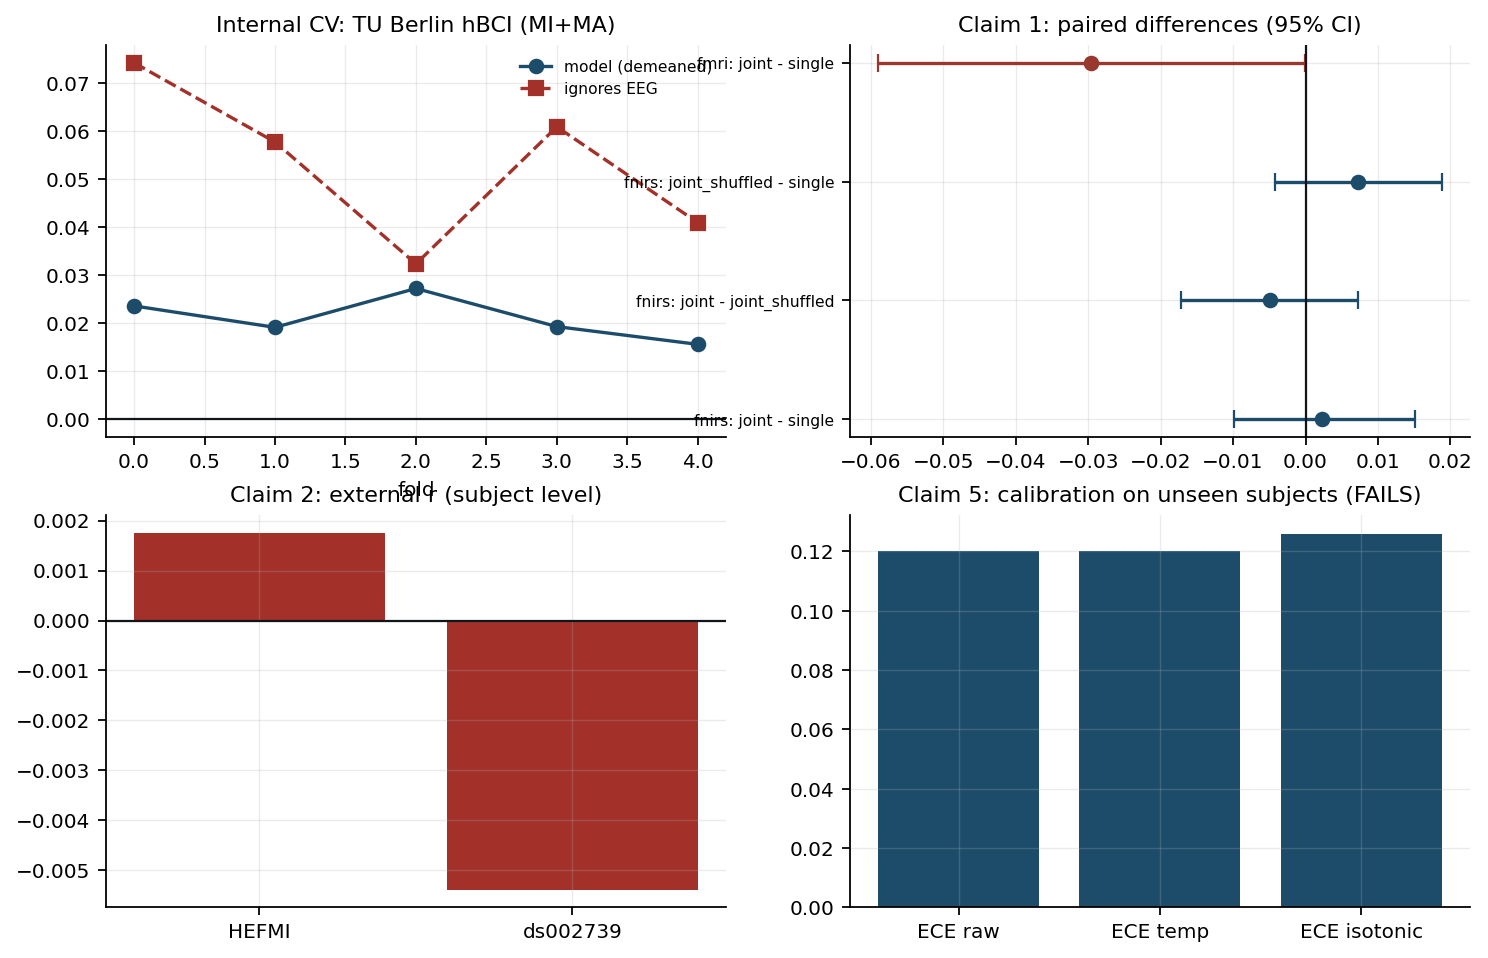

In [27]:
try:
    fig, ax = plt.subplots(2, 2, figsize=(11, 7))
    if TRAIN_SETS and TRAIN_SETS[0]["name"] in cv_tables:
        t = cv_tables[TRAIN_SETS[0]["name"]]
        ax[0, 0].plot(t.fold, t.r_demeaned, "o-", color=ACC, label="model (demeaned)")
        ax[0, 0].plot(t.fold, t.r_no_eeg_baseline, "s--", color=HBO, label="ignores EEG")
        ax[0, 0].axhline(0, color=INK, lw=1); ax[0, 0].legend(fontsize=7)
        ax[0, 0].set_title(f"Internal CV: {TRAIN_SETS[0]['name']}"); ax[0, 0].set_xlabel("fold")
    if controls is not None:
        for i, r in enumerate(controls.itertuples()):
            ax[0, 1].errorbar(r.mean_diff, i, xerr=[[r.mean_diff - r.ci_low], [r.ci_high - r.mean_diff]],
                              fmt="o", color=OK_ if r.ci_low > 0 else (NO_ if r.ci_high < 0 else ACC), capsize=4)
        ax[0, 1].set_yticks(range(len(controls)))
        ax[0, 1].set_yticklabels([f"{r.cohort}: {r.comparison}" for r in controls.itertuples()], fontsize=7)
        ax[0, 1].axvline(0, color=INK, lw=1); ax[0, 1].set_title("Claim 1: paired differences (95% CI)")
    if external:
        names = list(external)
        ax[1, 0].bar(names, [external[n]["r_subject"] for n in names], color=HBO)
        ax[1, 0].axhline(0, color=INK, lw=1); ax[1, 0].set_title("Claim 2: external r (subject level)")
    if claim5 and claim5.get("internal"):
        ax[1, 1].bar(["ECE raw", "ECE temp", "ECE isotonic"],
                     [claim5["internal"][k] for k in ("ece_raw", "ece_temp", "ece_iso")], color=ACC)
        ax[1, 1].set_title(f"Claim 5: calibration on unseen subjects ({claim5['verdict']})")
    save_fig(fig, "summary_panel", "Internal CV, Claim 1, Claim 2, Claim 5")
    from IPython.display import Image
    display(Image(filename=str(FIGDIR / "summary_panel.png")))
except Exception as exc:
    print(f"(summary figure skipped: {type(exc).__name__}: {exc})")